# 🛡️ File 6: Evaluasi Model Transformer pada Dataset Eksternal Baru (Cross-Dataset OOD v2)
**Riset Skripsi**: Perbandingan Kinerja RoBERTa-base dan DistilBERT-base untuk Deteksi Phishing URL  
- **Target Runtime**: Google Colab (GPU NVIDIA Tesla T4 16GB / CUDA 12.x)  
- **Storage Backend**: Google Drive (`/content/drive/MyDrive/Skripsi/`)  
- **Tujuan Utama**: Menguji performa generalisasi SELURUH model Transformer yang telah dilatih (DistilBERT seed 42, seed 123, seed 999 dan RoBERTa-base seed 42) pada dataset URL berbahaya (didominasi URL distribusi malware) vs URL aman, sumber url_features_extracted1.csv (`external2`), menerapkan validasi ketat anti-kebocoran data (*zero-leak OOD protocol*), mengukur metrik klasifikasi standar, metrik keamanan siber industri (TPR @ low FPR), kalibrasi probabilitas (ECE & Brier score), serta menganalisis komparasi Delta untuk menjawab secara empiris: **apakah kinerja model meningkat, menurun, atau stabil** dibanding hasil in-domain (`test.csv`) dan OOD lama.

---
### 📋 Ringkasan Alur Kerja Notebook:
1. **Setup Lingkungan & Instalasi Dependensi**: Menyiapkan pustaka evaluasi, mendeteksi GPU T4, menetapkan random seed (`set_seed(42)`).
2. **Mount Google Drive & Konfigurasi Parameter**: Menghubungkan Google Drive, mengatur path dataset mentah baru (`EXTERNAL_RAW_CSV`), flag konfigurasi (`DROP_DOMAIN_OVERLAP`, `BALANCE_CLASSES`), direktori model, dan hasil acuan.
3. **Pemuatan & Preprocessing Dataset Eksternal Baru**:
   - Pemuatan CSV, pemuatan langsung kolom URL & ClassLabel, ekstraksi metadata fitur, Polarity Guard, mapping biner multi-class (`label_map`).
   - Normalisasi URL standar skripsi (`normalize_url`), pembersihan duplikat & eliminasi konflik label.
   - Ekstraksi domain dengan `tldextract` ber-cache dan penanganan shared hosting (`domain_group`).
4. **Protokol Anti-Kebocoran Data (Zero-Leak Verification)**:
   - Eliminasi irisan URL dengan train/val/test in-domain dan OOD lama.
   - Analisis & pembuangan domain overlap (`DROP_DOMAIN_OVERLAP=True`).
   - Preprocessing representasi teks (`url_spaced` untuk WordPiece vs `url_norm` untuk BPE).
   - Zero-leak assertions & ekspor `external2_clean.csv`.
5. **Konstruksi PyTorch Dataset & Benchmark Inference Engine**:
   - Dataset loader `EvalURLDataset` berpelindung out-of-vocab (`unk_token_id`).
   - Evaluator berpresisi FP16 AMP (`torch.amp.autocast('cuda')`), warmup, tracking latensi (ms), throughput (sampel/s), peak VRAM (GB).
6. **Eksekusi Evaluasi Seluruh Model Transformer**:
   - DistilBERT-base (Seed 42, 123, 999).
   - RoBERTa-base (Seed 42).
   - Agregasi statistik Mean ± Std Dev 3 seed DistilBERT.
   - Metrik: Acc, Prec, Rec, F1-Binary, F1-Macro, ROC-AUC, PR-AUC, TPR @ FPR≤0.1% & ≤1.0%, FPR, FNR, ECE (15-bin), Brier score.
7. **Analisis Komparatif: Apakah Ada Peningkatan? (Delta Analysis)**:
   - Pemuatan acuan In-Domain (`transformer_training_results.csv`) & acuan OOD Lama (`final_ood_evaluation_results.csv`).
   - Komputasi Delta = Nilai Baru - Acuan (Status: ⬆️ Meningkat, ⬇️ Menurun, ➖ Stabil).
   - Visualisasi tabel dengan pandas Styler (hijau/merah) & simpulan otomatis berbahasa Indonesia.
8. **Uji Signifikansi Statistik & Analisis Domain Overlap Subgroup**:
   - Bootstrap 95% Confidence Interval (1000 resamples) untuk F1 & ROC-AUC.
   - McNemar Test (DistilBERT seed 42 vs RoBERTa-base).
   - Analisis performa subgroup domain terlihat vs domain belum terlihat (seen vs unseen), host berbasis IP vs domain, dan ekstensi file mencurigakan.
9. **Visualisasi Publikasi 300 DPI (12 Grafik Komprehensif)**:
   - `ext2_01_confusion_matrices.png` s.d. `ext2_12_calibration_curves.png`.
10. **Error Analysis (FP/FN) & Analisis Error Konsensus**:
    - Ekstraksi 5 sampel FP & FN teratas per model.
    - Analisis URL yang salah di SEMUA model (konsensus) vs salah hanya di SATU model.
11. **Pencatatan ke Logbook Skripsi (`SKRIPSI_LOG.md`) & Ekspor CSV**:
    - Ekspor 5 file CSV ke `RESULTS_DIR`.
    - Append tabel rekapitulasi evaluasi baru ke `SKRIPSI_LOG.md`.
12. **Simpulan Riset & Rekomendasi Deployment Skripsi**:
    - Rangkuman naratif otomatis: model terbaik/terburuk, tren delta, trade-off akurasi vs efisiensi, dan catatan reliabilitas sampel.


## 1. Setup Lingkungan & Instalasi Dependensi
Menginstalasi seluruh pustaka deep learning dan NLP yang dibutuhkan untuk evaluasi di Google Colab: `transformers`, `tokenizers`, `torch`, `scipy`, `scikit-learn`, `pandas`, `numpy`, `matplotlib`, `seaborn`, `tldextract`, `statsmodels`. Mengatur random seed (`seed=42`) untuk menjamin reproduktifitas eksperimen.

In [1]:
# Instalasi library pendukung di Google Colab
!pip install transformers tokenizers torch scipy scikit-learn pandas numpy tqdm matplotlib seaborn tldextract statsmodels -q

import os
import sys
import gc
import time
import re
import math
import random
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import interpolate
from scipy import stats

import torch
from torch.utils.data import Dataset, DataLoader
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    AutoConfig
)
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, confusion_matrix,
    roc_curve, precision_recall_curve, brier_score_loss
)
from sklearn.calibration import calibration_curve

# Mengatur random seed untuk reproduktifitas riset
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False

set_seed(42)

# Setup Hardware Device
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
print("======================================================================")
print(f"Device Operasi  : {device}")
if torch.cuda.is_available():
    print(f"GPU Hardware    : {torch.cuda.get_device_name(0)}")
    print(f"VRAM Capacity   : {torch.cuda.get_device_properties(0).total_memory / (1024**3):.2f} GB")
else:
    print("[PERINGATAN] GPU tidak terdeteksi. Evaluasi akan berjalan di CPU (lambat).")
print("======================================================================")

# Setup Gaya Grafik Publikasi
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.dpi'] = 300
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'

print("[OK] Seluruh pustaka pendukung berhasil diimpor & konfigurasi seed aktif.")

Device Operasi  : cuda:0
GPU Hardware    : NVIDIA L4
VRAM Capacity   : 22.03 GB
[OK] Seluruh pustaka pendukung berhasil diimpor & konfigurasi seed aktif.


## 2. Mount Google Drive & Konfigurasi Parameter Evaluasi
Menghubungkan direktori Google Drive (`/content/drive/MyDrive/Skripsi/`) dan menyiapkan konfigurasi jalur direktori model checkpoint, dataset input baru, hasil acuan in-domain dan OOD lama, serta flag konfigurasi pipeline.

In [2]:
# 1. Mount Google Drive
print("[INFO] Melakukan mounting Google Drive...")
try:
    from google.colab import drive
    drive.mount('/content/drive')
    print("[OK] Google Drive berhasil terhubung.")
except Exception as e:
    print(f"[INFO] Melewati drive.mount (berjalan di luar lingkungan standar Colab): {e}")

# 2. Direktori Utama & Sub-direktori Proyek (Hardcoded Path) # [DIUBAH]
BASE_DIR              = "/content/drive/MyDrive/Skripsi" # [DIUBAH]
DATA_DIR              = "/content/drive/MyDrive/Skripsi/new data" # [DIUBAH]
MODELS_DIR            = "/content/drive/MyDrive/Skripsi/models" # [DIUBAH]
RESULTS_DIR           = "/content/drive/MyDrive/Skripsi/results" # [DIUBAH]
EXTERNAL2_DIR         = "/content/drive/MyDrive/Skripsi/data/external2" # [DIUBAH]
os.makedirs(RESULTS_DIR, exist_ok=True) # [DIUBAH]
os.makedirs(EXTERNAL2_DIR, exist_ok=True) # [DIUBAH]

# 3. Path Dataset Eksternal Baru (Input & Output) # [DIUBAH]
EXTERNAL_RAW_CSV      = "/content/drive/MyDrive/Skripsi/data/external2/url_features_extracted1.csv" # [DIUBAH]
OUTPUT_CLEAN_CSV      = "/content/drive/MyDrive/Skripsi/data/external2/external2_clean.csv" # [DIUBAH]

# 4. Path Dataset Acuan In-Domain & OOD Lama untuk Anti-Kebocoran & Delta # [DIUBAH]
TRAIN_CSV             = "/content/drive/MyDrive/Skripsi/new data/train.csv" # [DIUBAH]
VAL_CSV               = "/content/drive/MyDrive/Skripsi/new data/val.csv" # [DIUBAH]
TEST_CSV              = "/content/drive/MyDrive/Skripsi/new data/test.csv" # [DIUBAH]
OOD_LAMA_CSV          = "/content/drive/MyDrive/Skripsi/data/external/phishing_url_dataset_unique.csv" # [DIUBAH]

IN_DOMAIN_RESULTS_CSV = "/content/drive/MyDrive/Skripsi/results/transformer_training_results.csv" # [DIUBAH]
OOD_LAMA_RESULTS_CSV  = "/content/drive/MyDrive/Skripsi/results/final_ood_evaluation_results.csv" # [DIUBAH]
LOG_FILE              = "/content/drive/MyDrive/Skripsi/SKRIPSI_LOG.md" # [DIUBAH]

# 5. Path Checkpoints Model yang Diuji (4 Model) # [DIUBAH]
MODEL_CHECKPOINTS = { # [DIUBAH]
  "DistilBERT (Seed 42)":   "/content/drive/MyDrive/Skripsi/models/distilbert_seed42", # [DIUBAH]
  "DistilBERT (Seed 123)":  "/content/drive/MyDrive/Skripsi/models/distilbert_seed123", # [DIUBAH]
  "DistilBERT (Seed 999)":  "/content/drive/MyDrive/Skripsi/models/distilbert_seed999", # [DIUBAH]
  "RoBERTa-base (Seed 42)": "/content/drive/MyDrive/Skripsi/models/roberta_phishing" # [DIUBAH]
} # [DIUBAH]

# 6. Konfigurasi Kolom Dataset Input # [DIUBAH]
URL_COL = "URL"              # [DIUBAH] Kolom input URL dari url_features_extracted1.csv
LABEL_COL = "ClassLabel"     # [DIUBAH] Kolom input label dari url_features_extracted1.csv

# 7. Flag Konfigurasi Pipeline Data & Inferensi
DROP_DOMAIN_OVERLAP = True   # True: Buang URL dengan domain yang pernah muncul di train.csv
BALANCE_CLASSES = False      # False: Pertahankan rasio kelas riil dataset baru (tanpa balancing diam-diam)
BATCH_SIZE = 64
MAX_LENGTH = 128

# 8. Konfigurasi Pemetaan Label Tambahan
LABEL_MAP_OVERRIDE = None    # Dict opsional untuk menimpa pemetaan label
INVERT_LABELS = True         # [DIUBAH] True: Nilai mentah 0 adalah berbahaya dan 1 aman, kebalikan konvensi skripsi

print(f"[OK] Direktori Utama      : {BASE_DIR}")
print(f"[OK] Direktori Model      : {MODELS_DIR}")
print(f"[OK] Direktori Hasil      : {RESULTS_DIR}")
print(f"[OK] Target Dataset Baru  : {EXTERNAL_RAW_CSV}")
print(f"[OK] Flag Drop Overlap    : {DROP_DOMAIN_OVERLAP}")
print(f"[OK] Flag Balance Classes : {BALANCE_CLASSES}")
print(f"[OK] Label Map Override   : {LABEL_MAP_OVERRIDE}")
print(f"[OK] Flag Invert Labels   : {INVERT_LABELS}")


Mounted at /content/drive
[OK] Google Drive berhasil terhubung.
[OK] Direktori Utama      : /content/drive/MyDrive/Skripsi
[OK] Direktori Model      : /content/drive/MyDrive/Skripsi/models
[OK] Direktori Hasil      : /content/drive/MyDrive/Skripsi/results
[OK] Target Dataset Baru  : /content/drive/MyDrive/Skripsi/data/external2/url_features_extracted1.csv
[OK] Flag Drop Overlap    : True
[OK] Flag Balance Classes : False
[OK] Label Map Override   : None
[OK] Flag Invert Labels   : True


In [3]:
# [DIUBAH] Sel Verifikasi Keberadaan Seluruh File dan Folder Input
import os

print("======================================================================")
print("🔍 VERIFIKASI KEBERADAAN FILE DAN DIREKTORI INPUT")
print("======================================================================")

# Pastikan folder hasil dan external2 dibuat jika belum ada # [DIUBAH]
os.makedirs(RESULTS_DIR, exist_ok=True) # [DIUBAH]
os.makedirs(EXTERNAL2_DIR, exist_ok=True) # [DIUBAH]

verify_items = [
    ("BASE_DIR", BASE_DIR, True),
    ("DATA_DIR", DATA_DIR, True),
    ("MODELS_DIR", MODELS_DIR, True),
    ("RESULTS_DIR", RESULTS_DIR, True),
    ("EXTERNAL2_DIR", EXTERNAL2_DIR, True),
    ("EXTERNAL_RAW_CSV", EXTERNAL_RAW_CSV, False),
    ("TRAIN_CSV", TRAIN_CSV, False),
    ("VAL_CSV", VAL_CSV, False),
    ("TEST_CSV", TEST_CSV, False),
    ("OOD_LAMA_CSV", OOD_LAMA_CSV, False),
    ("IN_DOMAIN_RESULTS_CSV", IN_DOMAIN_RESULTS_CSV, False),
    ("OOD_LAMA_RESULTS_CSV", OOD_LAMA_RESULTS_CSV, False),
]

for model_name, ckpt_dir in MODEL_CHECKPOINTS.items():
    verify_items.append((f"Model: {model_name}", ckpt_dir, True))

missing_items = []
for label, path, is_dir in verify_items:
    exists = os.path.isdir(path) if is_dir else os.path.isfile(path)
    status_icon = "✅" if exists else "❌"
    print(f" {status_icon} {label:<28}: {path}")
    if not exists:
        missing_items.append(path)

if missing_items:
    error_msg = f"❌ Terdapat {len(missing_items)} file/folder input yang tidak ditemukan! Eksekusi dihentikan.\n" + \
                f"File/Folder pertama yang hilang: {missing_items[0]}"
    raise FileNotFoundError(error_msg)
else:
    print("\n✅ Seluruh file dan direktori input terverifikasi lengkap. Melanjutkan eksekusi...")


🔍 VERIFIKASI KEBERADAAN FILE DAN DIREKTORI INPUT
 ✅ BASE_DIR                    : /content/drive/MyDrive/Skripsi
 ✅ DATA_DIR                    : /content/drive/MyDrive/Skripsi/new data
 ✅ MODELS_DIR                  : /content/drive/MyDrive/Skripsi/models
 ✅ RESULTS_DIR                 : /content/drive/MyDrive/Skripsi/results
 ✅ EXTERNAL2_DIR               : /content/drive/MyDrive/Skripsi/data/external2
 ✅ EXTERNAL_RAW_CSV            : /content/drive/MyDrive/Skripsi/data/external2/url_features_extracted1.csv
 ✅ TRAIN_CSV                   : /content/drive/MyDrive/Skripsi/new data/train.csv
 ✅ VAL_CSV                     : /content/drive/MyDrive/Skripsi/new data/val.csv
 ✅ TEST_CSV                    : /content/drive/MyDrive/Skripsi/new data/test.csv
 ✅ OOD_LAMA_CSV                : /content/drive/MyDrive/Skripsi/data/external/phishing_url_dataset_unique.csv
 ✅ IN_DOMAIN_RESULTS_CSV       : /content/drive/MyDrive/Skripsi/results/transformer_training_results.csv
 ✅ OOD_LAMA_RESULTS_CSV 

## 3. Pemuatan & Inspeksi Dataset Eksternal Baru
Memuat dataset URL berbahaya (didominasi URL distribusi malware) vs URL aman, sumber url_features_extracted1.csv, memuat kolom URL dan ClassLabel langsung beserta metadata, memetakan kategori multi-class ke label biner (0 = Benign, 1 = Phishing) dilengkapi Polarity Guard, serta membersihkan nilai kosong atau tidak valid.


In [4]:
# 1. Pemuatan File Dataset Eksternal Baru Secara Langsung (Hardcoded Path) # [DIUBAH]
if not os.path.exists(EXTERNAL_RAW_CSV): # [DIUBAH]
    raise FileNotFoundError(f"❌ File dataset eksternal baru tidak ditemukan: {EXTERNAL_RAW_CSV}") # [DIUBAH]

print(f"[INFO] Membaca dataset eksternal baru dari: {EXTERNAL_RAW_CSV}...") # [DIUBAH]
df_raw_input = pd.read_csv(EXTERNAL_RAW_CSV) # [DIUBAH]
initial_raw_rows = len(df_raw_input) # [DIUBAH]
print(f"[OK] Berhasil memuat {initial_raw_rows:,} baris mentah | Kolom: {df_raw_input.columns.tolist()}") # [DIUBAH]

# 2. Ekstraksi Kolom URL, Label, dan Metadata (Tanpa Deteksi Otomatis) # [DIUBAH]
print(f"[INFO] Kolom Input Ditentukan -> URL: '{URL_COL}' | Label: '{LABEL_COL}'") # [DIUBAH]
if URL_COL not in df_raw_input.columns: # [DIUBAH]
    raise KeyError(f"❌ Kolom URL '{URL_COL}' tidak ditemukan di {EXTERNAL_RAW_CSV}!") # [DIUBAH]
if LABEL_COL not in df_raw_input.columns: # [DIUBAH]
    raise KeyError(f"❌ Kolom Label '{LABEL_COL}' tidak ditemukan di {EXTERNAL_RAW_CSV}!") # [DIUBAH]

# Bawa metadata has_ip_address dan suspicious_file_extension untuk analisis subgroup # [DIUBAH]
meta_cols = ['has_ip_address', 'suspicious_file_extension'] # [DIUBAH]
for m_col in meta_cols: # [DIUBAH]
    if m_col not in df_raw_input.columns: # [DIUBAH]
        raise KeyError(f"❌ Kolom metadata '{m_col}' tidak ditemukan di {EXTERNAL_RAW_CSV}!") # [DIUBAH]

df_work = df_raw_input[[URL_COL, LABEL_COL] + meta_cols].copy() # [DIUBAH]
df_work = df_work.rename(columns={URL_COL: 'url', LABEL_COL: 'label'}) # [DIUBAH]

# Tampilkan estimasi pembanding karakteristik dataset # [DIUBAH]
print("\n[INFO] Estimasi Pembanding Dataset Mentah: ±1 label kosong, ±346 duplikat persis, ±1.357 duplikat setelah normalisasi, 0 konflik.") # [DIUBAH]
n_raw_label_na = df_work['label'].isna().sum() # [DIUBAH]
n_raw_exact_dups = df_work['url'].duplicated().sum() # [DIUBAH]
print(f"       Aktual Terdeteksi: {n_raw_label_na} label kosong (NaN), {n_raw_exact_dups:,} duplikat URL persis.") # [DIUBAH]

# Tampilkan distribusi kelas mentah sebelum mapping biner
print("\n--- Distribusi Kelas Mentah Sebelum Pemetaan ---")
print(df_work['label'].value_counts(dropna=False))

# 3. Standarisasi Multi-Class ke Biner (0 = Benign, 1 = Phishing/Malicious)
# Pemetaan dasar untuk seluruh tipe label (string kategorikal dan numerik int/float)
base_label_map = {
    'benign': 0, 'legitimate': 0, 'good': 0, 'safe': 0, 'normal': 0, '0': 0, 'false': 0, '-1': 0,
    'phishing': 1, 'malicious': 1, 'bad': 1, 'unsafe': 1, 'defacement': 1, 'malware': 1, 'spam': 1, '1': 1, 'true': 1,
    0: 0, 1: 1, -1: 0, 0.0: 0, 1.0: 1, -1.0: 0, '0.0': 0, '1.0': 1, '-1.0': 0
}

# Terapkan LABEL_MAP_OVERRIDE jika didefinisikan oleh pengguna
active_label_map = dict(base_label_map)
if LABEL_MAP_OVERRIDE and isinstance(LABEL_MAP_OVERRIDE, dict):
    print(f"\n[INFO] Menerapkan LABEL_MAP_OVERRIDE: {LABEL_MAP_OVERRIDE}")
    active_label_map.update(LABEL_MAP_OVERRIDE)

def map_single_label(raw_val):
    if pd.isna(raw_val):
        return np.nan
    # Cek nilai asli langsung di dictionary
    if raw_val in active_label_map:
        return active_label_map[raw_val]
    # Cek nilai numerik (int/float)
    if isinstance(raw_val, (int, float, np.integer, np.floating)):
        try:
            int_v = int(raw_val)
            if int_v in active_label_map:
                return active_label_map[int_v]
        except Exception:
            pass
    # Normalisasi string (lowercase & strip)
    s_val = str(raw_val).strip().lower()
    if s_val in active_label_map:
        return active_label_map[s_val]
    # Fallback parsing string angka
    try:
        f_val = float(s_val)
        if f_val in active_label_map:
            return active_label_map[f_val]
        if int(f_val) in active_label_map:
            return active_label_map[int(f_val)]
    except Exception:
        pass
    return np.nan

# Petakan seluruh baris ke label biner
df_work['mapped_label'] = df_work['label'].apply(map_single_label)

# Opsi pembalikan label jika INVERT_LABELS diaktifkan
if INVERT_LABELS:
    print("\n[INFO] Flag INVERT_LABELS=True: Membalik label biner (0 -> 1, 1 -> 0)...")
    df_work['mapped_label'] = df_work['mapped_label'].map({0: 1, 1: 0, 0.0: 1, 1.0: 0})

# c. Cetak pemetaan AKTUAL: tabel nilai unik mentah -> label biner hasil -> jumlah baris
mapping_summary = []
raw_counts = df_work['label'].value_counts(dropna=False)
for raw_v, count_v in raw_counts.items():
    mapped_res = map_single_label(raw_v)
    if INVERT_LABELS and pd.notna(mapped_res) and mapped_res in [0, 1]:
        mapped_res = 1 - int(mapped_res)
    mapped_desc = int(mapped_res) if pd.notna(mapped_res) and mapped_res in [0, 1] else "TIDAK TERPETAKAN (NaN)"
    mapping_summary.append({
        'Nilai Mentah': str(raw_v),
        'Label Biner Hasil': mapped_desc,
        'Jumlah Baris': count_v,
        'Persentase': f"{(count_v / initial_raw_rows) * 100:.2f}%"
    })

df_map_actual = pd.DataFrame(mapping_summary)
print("\n=== TABEL PEMETAAN AKTUAL NILAI MENTAH -> LABEL BINER ===")
display(df_map_actual)

# d. Cetak nilai mentah yang TIDAK terpetakan beserta jumlah barisnya sebelum dibuang
unmapped_mask = df_work['mapped_label'].isna() | (~df_work['mapped_label'].isin([0, 1]))
n_unmapped = unmapped_mask.sum()
unmapped_pct = (n_unmapped / initial_raw_rows) * 100

if n_unmapped > 0:
    print(f"\n[INFO] Nilai mentah yang TIDAK terpetakan ({n_unmapped:,} baris / {unmapped_pct:.2f}%):")
    print(df_work[unmapped_mask]['label'].value_counts(dropna=False))
    if unmapped_pct > 5.0:
        print(f"\n⚠️ [PERINGATAN] Jumlah baris terbuang karena label tidak terpetakan ({n_unmapped:,} baris, {unmapped_pct:.2f}%) > 5% dari total data!")
        print("   Harap periksa kolom label dataset baru atau sesuaikan variabel LABEL_MAP_OVERRIDE di Cell Konfigurasi.")
else:
    print("\n[OK] Seluruh nilai label mentah berhasil terpetakan 100% tanpa ada baris yang terbuang.")

# Terapkan hasil pemetaan
df_work['label'] = df_work['mapped_label']
df_work = df_work.drop(columns=['mapped_label'])

# 4. Validasi Pembersihan Awal: Drop NaN, URL Non-String, dan Label Non-Biner
df_work['label'] = pd.to_numeric(df_work['label'], errors='coerce')
valid_label_mask = df_work['label'].isin([0, 1])
valid_url_mask = df_work['url'].notna() & (df_work['url'].astype(str).str.strip() != "")

df_valid = df_work[valid_label_mask & valid_url_mask].copy()
df_valid['label'] = df_valid['label'].astype(int)
df_valid['url'] = df_valid['url'].astype(str).str.strip()

# Konversi metadata ke numerik integer # [DIUBAH]
df_valid['has_ip_address'] = pd.to_numeric(df_valid['has_ip_address'], errors='coerce').fillna(0).astype(int) # [DIUBAH]
df_valid['suspicious_file_extension'] = pd.to_numeric(df_valid['suspicious_file_extension'], errors='coerce').fillna(0).astype(int) # [DIUBAH]

discarded_initial = initial_raw_rows - len(df_valid)
print(f"\n[OK] Total baris terbuang (NaN / invalid / label di luar {0,1}): {discarded_initial:,}")
print(f"[OK] Baris tersisa setelah validasi tipe: {len(df_valid):,}")

# [DIUBAH] POLARITY GUARD (Validasi Arah Pemetaan Label)
print("\n" + "="*70) # [DIUBAH]
print("🛡️ POLARITY GUARD: VALIDASI KORELASI FITUR BERBAHAYA DENGAN LABEL") # [DIUBAH]
print("="*70) # [DIUBAH]
mean_ip_0 = df_valid[df_valid['label'] == 0]['has_ip_address'].mean() # [DIUBAH]
mean_ip_1 = df_valid[df_valid['label'] == 1]['has_ip_address'].mean() # [DIUBAH]
mean_ext_0 = df_valid[df_valid['label'] == 0]['suspicious_file_extension'].mean() # [DIUBAH]
mean_ext_1 = df_valid[df_valid['label'] == 1]['suspicious_file_extension'].mean() # [DIUBAH]

print(f"Rata-rata has_ip_address             -> Label 0 (Benign): {mean_ip_0:.4f} | Label 1 (Malicious): {mean_ip_1:.4f}") # [DIUBAH]
print(f"Rata-rata suspicious_file_extension  -> Label 0 (Benign): {mean_ext_0:.4f} | Label 1 (Malicious): {mean_ext_1:.4f}") # [DIUBAH]

if (mean_ip_1 <= mean_ip_0) or (mean_ext_1 <= mean_ext_0): # [DIUBAH]
    print("\n" + "!"*70) # [DIUBAH]
    print("⚠️⚠️⚠️ [PERINGATAN BESAR: POLARITY GUARD MENDETEKSI ANOMALI LABEL] ⚠️⚠️⚠️") # [DIUBAH]
    print("Prevalensi fitur berbahaya (IP / ekstensi mencurigakan) pada Label 1 TIDAK lebih tinggi dari Label 0!") # [DIUBAH]
    print("KEMUNGKINAN BESAR ARAH LABEL TERBALIK! Harap periksa konfigurasi INVERT_LABELS.") # [DIUBAH]
    print("!"*70 + "\n") # [DIUBAH]
else: # [DIUBAH]
    print("✅ [PASS] Polarity Guard Lolos: Label 1 terbukti memiliki prevalensi fitur berbahaya lebih tinggi dari Label 0.") # [DIUBAH]

# e. Sanity check: cetak 5 contoh URL acak untuk tiap label (0 dan 1) # [DIUBAH]
print("\n=== SANITY CHECK SAMPEL URL PER LABEL (PEMERIKSAAN VISUAL) ===")
for lbl_val, lbl_name in [(0, "Benign (0)"), (1, "Phishing (1)")]:
    sample_sub = df_valid[df_valid['label'] == lbl_val]
    n_samp = min(5, len(sample_sub)) # [DIUBAH] Ubah ke 5 sampel per label
    print(f"\n📌 {n_samp} Contoh Sampel URL untuk Kelas '{lbl_name}' (Total {len(sample_sub):,} sampel):") # [DIUBAH]
    if n_samp > 0:
        samples = sample_sub.sample(n_samp, random_state=42)['url'].tolist()
        for idx_s, u_s in enumerate(samples, 1):
            print(f"   [{idx_s}] {u_s[:90]}")
    else:
        print("   [KOSONG] Tidak ada sampel untuk kelas ini.")

# Simpan catatan funnel
funnel_records = [{"Tahapan": "1. Mentah (Raw Input)", "Jumlah_Baris": initial_raw_rows, "Keterangan": "Pemuatan file CSV mentah"},
                  {"Tahapan": "2. Validasi Tipe & NaN", "Jumlah_Baris": len(df_valid), "Keterangan": f"Membuang {discarded_initial:,} baris invalid"}]


[INFO] Membaca dataset eksternal baru dari: /content/drive/MyDrive/Skripsi/data/external2/url_features_extracted1.csv...
[OK] Berhasil memuat 101,219 baris mentah | Kolom: ['URL', 'url_length', 'has_ip_address', 'dot_count', 'https_flag', 'url_entropy', 'token_count', 'subdomain_count', 'query_param_count', 'tld_length', 'path_length', 'has_hyphen_in_domain', 'number_of_digits', 'tld_popularity', 'suspicious_file_extension', 'domain_name_length', 'percentage_numeric_chars', 'ClassLabel']
[INFO] Kolom Input Ditentukan -> URL: 'URL' | Label: 'ClassLabel'

[INFO] Estimasi Pembanding Dataset Mentah: ±1 label kosong, ±346 duplikat persis, ±1.357 duplikat setelah normalisasi, 0 konflik.
       Aktual Terdeteksi: 1 label kosong (NaN), 346 duplikat URL persis.

--- Distribusi Kelas Mentah Sebelum Pemetaan ---
label
0.0    63678
1.0    37540
NaN        1
Name: count, dtype: int64

[INFO] Flag INVERT_LABELS=True: Membalik label biner (0 -> 1, 1 -> 0)...

=== TABEL PEMETAAN AKTUAL NILAI MENTAH ->

,Nilai Mentah,Label Biner Hasil,Jumlah Baris,Persentase
0,0.0,1,63678,62.91%
1,1.0,0,37540,37.09%
2,nan,TIDAK TERPETAKAN (NaN),1,0.00%



[INFO] Nilai mentah yang TIDAK terpetakan (1 baris / 0.00%):
label
NaN    1
Name: count, dtype: int64

[OK] Total baris terbuang (NaN / invalid / label di luar (0, 1)): 1
[OK] Baris tersisa setelah validasi tipe: 101,218

🛡️ POLARITY GUARD: VALIDASI KORELASI FITUR BERBAHAYA DENGAN LABEL
Rata-rata has_ip_address             -> Label 0 (Benign): 0.0000 | Label 1 (Malicious): 0.7707
Rata-rata suspicious_file_extension  -> Label 0 (Benign): 0.0001 | Label 1 (Malicious): 0.2330
✅ [PASS] Polarity Guard Lolos: Label 1 terbukti memiliki prevalensi fitur berbahaya lebih tinggi dari Label 0.

=== SANITY CHECK SAMPEL URL PER LABEL (PEMERIKSAAN VISUAL) ===

📌 5 Contoh Sampel URL untuk Kelas 'Benign (0)' (Total 37,540 sampel):
   [1] https://www.fontenay-le-comte.fr
   [2] https://www.empowered-achiever.com
   [3] https://www.nonprofitpro.com
   [4] https://www.matec-inc.co.jp
   [5] https://www.nellessenziale.it

📌 5 Contoh Sampel URL untuk Kelas 'Phishing (1)' (Total 63,678 sampel):
   [1] http:

## 4. Normalisasi URL, Eliminasi Konflik Label & Deduplikasi Laten
Menerapkan normalisasi string URL standar skripsi (lowercasing, pemotongan skema protokol, pemotongan prefix www, pemotongan trailing slash), mengeliminasi URL yang memiliki konflik label (terlabel 0 dan 1 sekaligus), serta menghapus seluruh duplikat laten.

In [5]:
# 1. Fungsi Normalisasi URL (Identik dengan Notebook 01_Data_Prep)
def normalize_url(url: str) -> str:
    '''
    Normalisasi URL standar riset skripsi:
    - Lowercase
    - Hapus skema protokol (http://, https://, ftp://, dll)
    - Hapus prefix www dan variasinya (www1., www2.)
    - Hapus trailing slashes berulang di akhir string
    '''
    if not isinstance(url, str):
        return ""
    u = url.strip().lower()
    u = re.sub(r'^[a-z]+://', '', u)
    u = re.sub(r"^www\d*\.", "", u)
    u = re.sub(r'/+$', '', u)
    return u.strip()

print("[INFO] Menjalankan fungsi normalisasi URL standar...")
n_exact_dups_pre = df_valid['url'].duplicated().sum() # [DIUBAH] Hitung duplikat persis sebelum normalisasi
df_valid['url_norm'] = df_valid['url'].apply(normalize_url)
df_valid = df_valid[df_valid['url_norm'] != ""].reset_index(drop=True)
print(f"[OK] Baris setelah normalisasi: {len(df_valid):,}")

# 2. Deteksi & Eliminasi Konflik Label (URL identik yang memiliki label 0 dan 1 sekaligus)
print("\n[INFO] Mendeteksi URL dengan konflik label (label 0 dan 1 pada URL yang sama)...")
url_label_nunique = df_valid.groupby('url_norm')['label'].transform('nunique')
conflict_mask = url_label_nunique > 1
n_conflicts = conflict_mask.sum()

if n_conflicts > 0:
    print(f"[PERINGATAN] Ditemukan {n_conflicts:,} baris URL dengan label konflik (0 dan 1). Menghapus URL tersebut...")
    df_no_conflict = df_valid[~conflict_mask].copy().reset_index(drop=True)
    print(f"[OK] Baris setelah eliminasi konflik: {len(df_no_conflict):,}")
else:
    print("[OK] Tidak ditemukan konflik label pada dataset eksternal.")
    df_no_conflict = df_valid.copy().reset_index(drop=True)

del df_valid
gc.collect()

# 3. Deduplikasi Laten (Menghapus duplikat berdasarkan url_norm)
len_before_dedup = len(df_no_conflict)
df_dedup = df_no_conflict.drop_duplicates(subset=['url_norm']).reset_index(drop=True)
n_dups_removed = len_before_dedup - len(df_dedup)
print(f"[OK] Berhasil menghapus {n_dups_removed:,} duplikat laten.")
print(f"[OK] Total baris dataset bersih dan unik: {len(df_dedup):,}")

# [DIUBAH] Cetak angka perkiraan sebagai pembanding (bukan error)
print("\n=== PERBANDINGAN ANGKA PEMBERSIHAN TERHADAP EKSPEKTASI DATASET ===") # [DIUBAH]
print(f" - Label Kosong (NaN)          : Terdeteksi {discarded_initial} baris  | Ekspektasi: ±1 label kosong") # [DIUBAH]
print(f" - Duplikat Persis             : Terdeteksi {n_exact_dups_pre:,} baris  | Ekspektasi: ±346 duplikat persis") # [DIUBAH]
print(f" - Duplikat Pasca-Normalisasi  : Terdeteksi {n_dups_removed:,} baris  | Ekspektasi: ±1.357 duplikat setelah normalisasi") # [DIUBAH]
print(f" - Konflik Label               : Terdeteksi {n_conflicts} baris  | Ekspektasi: 0 konflik") # [DIUBAH]

print("\n=== DISTRIBUSI LABEL SETELAH DEDUPLIKASI ===")
vc = df_dedup['label'].value_counts()
vcp = df_dedup['label'].value_counts(normalize=True) * 100
for lbl_val in [0, 1]:
    lbl_name = "Benign (0)" if lbl_val == 0 else "Phishing (1)"
    print(f" - {lbl_name:<13}: {vc.get(lbl_val, 0):,} ({vcp.get(lbl_val, 0):.2f}%)")

funnel_records.append({"Tahapan": "3. Eliminasi Konflik", "Jumlah_Baris": len_before_dedup, "Keterangan": f"Dihapus {n_conflicts:,} baris konflik"})
funnel_records.append({"Tahapan": "4. Deduplikasi Laten", "Jumlah_Baris": len(df_dedup), "Keterangan": f"Dihapus {n_dups_removed:,} duplikat"})


[INFO] Menjalankan fungsi normalisasi URL standar...
[OK] Baris setelah normalisasi: 101,218

[INFO] Mendeteksi URL dengan konflik label (label 0 dan 1 pada URL yang sama)...
[OK] Tidak ditemukan konflik label pada dataset eksternal.
[OK] Berhasil menghapus 1,357 duplikat laten.
[OK] Total baris dataset bersih dan unik: 99,861

=== PERBANDINGAN ANGKA PEMBERSIHAN TERHADAP EKSPEKTASI DATASET ===
 - Label Kosong (NaN)          : Terdeteksi 1 baris  | Ekspektasi: ±1 label kosong
 - Duplikat Persis             : Terdeteksi 346 baris  | Ekspektasi: ±346 duplikat persis
 - Duplikat Pasca-Normalisasi  : Terdeteksi 1,357 baris  | Ekspektasi: ±1.357 duplikat setelah normalisasi
 - Konflik Label               : Terdeteksi 0 baris  | Ekspektasi: 0 konflik

=== DISTRIBUSI LABEL SETELAH DEDUPLIKASI ===
 - Benign (0)   : 37,375 (37.43%)
 - Phishing (1) : 62,486 (62.57%)


## 5. Ekstraksi Domain Menggunakan `tldextract` & Penanganan Shared Hosting
Mengekstrak registered domain dari URL menggunakan `tldextract` dengan caching pada host unik, serta menangani domain *shared hosting* / *URL shortener* / *free web hosting* (`SHARED_DOMAINS`) dengan menyertakan path tingkat pertama untuk membentuk `domain_group`.

In [6]:
import tldextract

# Inisialisasi ekstraktor tldextract tanpa local cache disk
extractor = tldextract.TLDExtract(cache_dir=None)

# Daftar domain shared hosting, shortener, dan platform publik (Identik dengan Notebook 01_Data_Prep)
SHARED_DOMAINS = {
    'google.com', 'sites.google.com', 'docs.google.com', 'drive.google.com',
    'github.io', 'gitlab.io', 'bit.ly', 'tinyurl.com', 'wordpress.com',
    'blogspot.com', 'firebaseapp.com', 'web.app', 'weebly.com', 'wixsite.com',
    'azurewebsites.net', 'appspot.com', '000webhostapp.com', 'ngrok.io',
    'herokuapp.com', 'pages.dev', 'netlify.app', 'vercel.app', 'glitch.me',
    'replit.app', 's3.amazonaws.com'
}

def split_host_path(url_norm: str):
    parts = url_norm.split('/', 1)
    host = parts[0].split(':', 1)[0]  # buang port jika ada
    first_path = parts[1].split('/')[0] if len(parts) > 1 and parts[1] else ""
    return host, first_path

print("[INFO] Mengekstrak host dan path tingkat pertama...")
host_path_series = df_dedup['url_norm'].apply(split_host_path)
df_dedup['host'] = [hp[0] for hp in host_path_series]
df_dedup['first_path'] = [hp[1] for hp in host_path_series]

# Cache tldextract pada unique hosts untuk efisiensi kecepatan eksekusi
unique_hosts = df_dedup['host'].unique()
print(f"[INFO] Mengekstrak {len(unique_hosts):,} host unik dengan tldextract...")

host_to_regdom = {}
for h in unique_hosts:
    ext = extractor(h)
    reg_dom = ext.top_domain_under_public_suffix if hasattr(ext, 'top_domain_under_public_suffix') and ext.top_domain_under_public_suffix else ext.registered_domain
    host_to_regdom[h] = reg_dom.lower() if reg_dom else h.lower()

df_dedup['reg_domain'] = df_dedup['host'].map(host_to_regdom)

def create_domain_group(row):
    reg_dom = row['reg_domain']
    host = row['host']
    path_1 = row['first_path']
    if (reg_dom in SHARED_DOMAINS or host in SHARED_DOMAINS) and path_1:
        return f"{reg_dom}/{path_1}"
    return reg_dom if reg_dom else host

print("[INFO] Membentuk domain_group dengan penanganan shared hosting...")
df_dedup['domain_group'] = df_dedup.apply(create_domain_group, axis=1)

# Bersihkan kolom bantu
df_dedup = df_dedup.drop(columns=['host', 'first_path', 'reg_domain'])

# [DIUBAH] Asersi: Memastikan tidak ada domain_group kosong (URL IP:port seperti 120.61.239.166:45010/bin.sh harus menghasilkan domain_group berupa IP)
assert df_dedup['domain_group'].notna().all() and (df_dedup['domain_group'].astype(str).str.strip() != "").all(), \
    "❌ Asersi Gagal: Terdeteksi domain_group kosong! Seluruh URL (termasuk berbasis IP) harus memiliki domain_group yang valid." # [DIUBAH]
assert (df_dedup['domain_group'] != "").all(), "❌ Ada domain_group string kosong!" # [DIUBAH]
print("✅ [PASS] Asersi Domain: 100% sampel memiliki domain_group valid (tidak ada yang kosong).") # [DIUBAH]

total_groups = df_dedup['domain_group'].nunique()
print(f"\n[OK] Ekstraksi domain selesai!")
print(f"Total Sampel URL : {len(df_dedup):,}")
print(f"Total Domain Grup: {total_groups:,}")
print("\n10 Domain Grup Terbanyak:")
print(df_dedup['domain_group'].value_counts().head(10))


[INFO] Mengekstrak host dan path tingkat pertama...
[INFO] Mengekstrak 63,962 host unik dengan tldextract...


/tmp/ipykernel_2903/1783179366.py:34: DeprecationWarning: The 'registered_domain' property is deprecated and will be removed in the next major version. Use 'top_domain_under_public_suffix' instead, which has the same behavior but a more accurate name.
  reg_dom = ext.top_domain_under_public_suffix if hasattr(ext, 'top_domain_under_public_suffix') and ext.top_domain_under_public_suffix else ext.registered_domain


[INFO] Membentuk domain_group dengan penanganan shared hosting...
✅ [PASS] Asersi Domain: 100% sampel memiliki domain_group valid (tidak ada yang kosong).

[OK] Ekstraksi domain selesai!
Total Sampel URL : 99,861
Total Domain Grup: 62,934

10 Domain Grup Terbanyak:
domain_group
cumpar-auto-orice-tip.ro    958
powerforxes.shop            769
uniformeslaamistad.com      767
mugutu.com                  765
veritas.org.ng              718
esalesin.com                691
johnmccrea.com              688
amwebsolution.com           686
iestpchincha.edu.pe         685
amazonscouts.com            681
Name: count, dtype: int64


## 6. Protokol Anti-Kebocoran Data & Zero-Leak Verification
Menerapkan protokol anti-kebocoran data ketat agar evaluasi benar-benar mencerminkan generalisasi *Out-of-Distribution* (OOD):
1. Mengeliminasi URL yang pernah muncul pada data latih, validasi, atau uji in-domain (`train.csv`, `val.csv`, `test.csv`).
2. Mengeliminasi URL yang pernah diuji pada dataset OOD lama (`phishing_url_dataset_unique.csv`).
3. Menganalisis overlap registered domain dengan data latih, serta membuang domain overlap (`DROP_DOMAIN_OVERLAP=True`).
4. Memvalidasi integritas dataset dengan serangkaian pengujian asersi ketat (*zero-leak assertions*).
5. Menyiapkan representasi teks per model (`url_spaced` untuk WordPiece dan `url_norm` untuk BPE) serta mengekspor `external2_clean.csv`.

In [7]:
# 1. Pemuatan URL Data Historis In-Domain (Train, Val, Test) Secara Langsung # [DIUBAH]
train_urls, val_urls, test_urls = set(), set(), set()
train_domains = set()

for split_name, split_path, url_set in [("Train", TRAIN_CSV, train_urls),
                                         ("Val", VAL_CSV, val_urls),
                                         ("Test", TEST_CSV, test_urls)]:
    # [DIUBAH] Baca langsung tanpa pengecekan fallback / peringatan dilewati
    if not os.path.exists(split_path): # [DIUBAH]
        raise FileNotFoundError(f"❌ File {split_name} tidak ditemukan: {split_path}") # [DIUBAH]
    print(f"[INFO] Membaca URL in-domain {split_name} dari: {split_path}...") # [DIUBAH]
    df_split = pd.read_csv(split_path, usecols=['url_norm', 'domain_group'] if 'domain_group' in pd.read_csv(split_path, nrows=2).columns else ['url_norm']) # [DIUBAH]
    url_set.update(df_split['url_norm'].dropna().astype(str).str.strip().tolist()) # [DIUBAH]
    if split_name == "Train" and 'domain_group' in df_split.columns: # [DIUBAH]
        train_domains.update(df_split['domain_group'].dropna().astype(str).str.strip().tolist()) # [DIUBAH]
    print(f"   [OK] {split_name} URLs: {len(url_set):,} unik") # [DIUBAH]

in_domain_urls_total = train_urls.union(val_urls).union(test_urls)
print(f"[INFO] Total URL In-Domain Unik yang Terdaftar: {len(in_domain_urls_total):,}")

# 2. Pemuatan URL OOD Lama Secara Langsung # [DIUBAH]
if not os.path.exists(OOD_LAMA_CSV): # [DIUBAH]
    raise FileNotFoundError(f"❌ File OOD Lama tidak ditemukan: {OOD_LAMA_CSV}") # [DIUBAH]

old_ood_urls = set()
print(f"[INFO] Membaca URL OOD Lama dari: {OOD_LAMA_CSV}...") # [DIUBAH]
df_old_ood = pd.read_csv(OOD_LAMA_CSV) # [DIUBAH]
col_u = 'url_norm' if 'url_norm' in df_old_ood.columns else 'url' # [DIUBAH]
if col_u == 'url': # [DIUBAH]
    old_ood_urls.update(df_old_ood[col_u].dropna().apply(normalize_url).tolist()) # [DIUBAH]
else: # [DIUBAH]
    old_ood_urls.update(df_old_ood[col_u].dropna().astype(str).str.strip().tolist()) # [DIUBAH]
print(f"   [OK] OOD Lama URLs: {len(old_ood_urls):,} unik") # [DIUBAH]

# 3. Filtrasi Kebocoran URL
len_before_leak_filter = len(df_dedup)
leak_in_domain_mask = df_dedup['url_norm'].isin(in_domain_urls_total)
n_leaks_indomain = leak_in_domain_mask.sum()

df_filtered = df_dedup[~leak_in_domain_mask].copy().reset_index(drop=True)
print(f"\n[OK] Eliminasi kebocoran in-domain: {n_leaks_indomain:,} baris dibuang.")

leak_ood_mask = df_filtered['url_norm'].isin(old_ood_urls)
n_leaks_ood = leak_ood_mask.sum()
df_filtered = df_filtered[~leak_ood_mask].copy().reset_index(drop=True)
print(f"[OK] Eliminasi kebocoran OOD lama: {n_leaks_ood:,} baris dibuang.")
print(f"[OK] Sisa sampel setelah filtrasi kebocoran URL: {len(df_filtered):,}")

funnel_records.append({"Tahapan": "5. Anti-Kebocoran URL", "Jumlah_Baris": len(df_filtered),
                       "Keterangan": f"Dihapus {n_leaks_indomain:,} in-domain & {n_leaks_ood:,} OOD lama"})

# 4. Preprocessing Teks Khusus per Model (url_spaced untuk WordPiece, url_norm untuk BPE)
def preprocess_delimiter_spacing(u: str) -> str:
    '''
    Menambahkan spasi di sekitar karakter delimiter khusus URL
    sesuai format training tokenizer WordPiece URLBERT.
    '''
    if not isinstance(u, str):
        return ""
    u = u.strip()
    u = u.replace('://', ' :// ')
    u = u.replace('/', ' / ')
    u = u.replace('?', ' ? ')
    u = u.replace('=', ' = ')
    u = u.replace('&', ' & ')
    u = u.replace('.', ' . ')
    u = u.replace('-', ' - ')
    return re.sub(r'\s+', ' ', u).strip()

print("\n[INFO] Menghasilkan representasi url_spaced untuk DistilBERT WordPiece...")
df_filtered['url_spaced'] = df_filtered['url_norm'].apply(preprocess_delimiter_spacing) # [DIUBAH] Diterapkan pada df_filtered

# 5. Analisis & Penandaan Domain Overlap dengan Data Latih # [DIUBAH]
overlap_mask = df_filtered['domain_group'].isin(train_domains)
df_filtered['is_seen_domain'] = overlap_mask.values # [DIUBAH] Flag is_seen_domain untuk analisis subgroup

n_overlap_rows = overlap_mask.sum()
overlap_pct = (n_overlap_rows / max(len(df_filtered), 1)) * 100
print(f"\n[INFO] Analisis Domain Overlap dengan Train Set In-Domain:")
print(f"   Jumlah Baris Overlap Domain: {n_overlap_rows:,} ({overlap_pct:.2f}%)")

df_seen_domain = df_filtered[overlap_mask].copy().reset_index(drop=True)
df_unseen_domain = df_filtered[~overlap_mask].copy().reset_index(drop=True)

# Simpan gabungan seen+unseen lengkap untuk inferensi satu kali # [DIUBAH]
df_eval_all = df_filtered.copy().reset_index(drop=True) # [DIUBAH]

if DROP_DOMAIN_OVERLAP:
    print(f"[INFO] Flag DROP_DOMAIN_OVERLAP=True: Membuang {n_overlap_rows:,} baris domain overlap agar murni Unseen Domain OOD...")
    df_clean = df_unseen_domain.copy().reset_index(drop=True)
else:
    print("[INFO] Flag DROP_DOMAIN_OVERLAP=False: Mempertahankan domain overlap dalam dataset uji...")
    df_clean = df_filtered.copy().reset_index(drop=True)

funnel_records.append({"Tahapan": "6. Filter Domain Overlap", "Jumlah_Baris": len(df_clean),
                       "Keterangan": f"DROP_DOMAIN_OVERLAP={DROP_DOMAIN_OVERLAP} (Dibuang {n_overlap_rows:,} baris)"})

# 6. Penanganan Keseimbangan Kelas (BALANCE_CLASSES Flag)
if BALANCE_CLASSES:
    print("[INFO] Flag BALANCE_CLASSES=True: Menjalankan stratified subsampling...")
    min_count = df_clean['label'].value_counts().min()
    df_clean = df_clean.groupby('label', group_keys=False).apply(lambda x: x.sample(min_count, random_state=42)).reset_index(drop=True)
else:
    print("[INFO] Flag BALANCE_CLASSES=False: Melaporkan distribusi kelas riil apa adanya.")

prop_0 = (df_clean['label'] == 0).mean() * 100
prop_1 = (df_clean['label'] == 1).mean() * 100
if prop_0 > 90 or prop_1 > 90:
    print(f"\n⚠️ [PERINGATAN] Rasio kelas sangat timpang (Benign: {prop_0:.1f}% vs Phishing: {prop_1:.1f}%).")
    print("   Metrik Accuracy dapat menjadi bias/menyesatkan. Prioritaskan F1-Macro, ROC-AUC, PR-AUC, dan TPR @ low FPR!")

# 7. Asersi Nol Kebocoran (Zero-Leak Assertions)
print("\n[INFO] Menjalankan serangkaian Zero-Leak Assertions...")
assert len(set(df_clean['url_norm']).intersection(train_urls)) == 0, "❌ Terdeteksi kebocoran URL dengan Train Set!"
assert len(set(df_clean['url_norm']).intersection(val_urls)) == 0, "❌ Terdeteksi kebocoran URL dengan Val Set!"
assert len(set(df_clean['url_norm']).intersection(test_urls)) == 0, "❌ Terdeteksi kebocoran URL dengan Test Set!"
assert len(set(df_clean['url_norm']).intersection(old_ood_urls)) == 0, "❌ Terdeteksi kebocoran URL dengan OOD Lama!"
assert set(df_clean['label'].unique()).issubset({0, 1}), "❌ Label tidak biner {0, 1}!"
assert df_clean['url_norm'].duplicated().sum() == 0, "❌ Ditemukan duplikat laten pada url_norm!"
print("✅ [PASS] Seluruh Zero-Leak Assertions Lolos Sempurna!")

# 8. Tampilkan Funnel & Simpan external2_clean.csv
df_funnel = pd.DataFrame(funnel_records)
print("\n=== TABEL FUNNEL DATA PREPARATION ===")
display(df_funnel)

# Pastikan urutan kolom sesuai spesifikasi, membawa metadata has_ip_address & suspicious_file_extension # [DIUBAH]
output_cols = ['url', 'url_norm', 'url_spaced', 'domain_group', 'label', 'has_ip_address', 'suspicious_file_extension'] # [DIUBAH]
df_clean = df_clean[output_cols].copy() # [DIUBAH]
df_clean.to_csv(OUTPUT_CLEAN_CSV, index=False)
print(f"\n✅ [SUKSES] Dataset eksternal bersih tersimpan ke: {OUTPUT_CLEAN_CSV}")
print(f"Total Sampel Siap Uji: {len(df_clean):,} baris")
print("\n5 Baris Pertama:")
display(df_clean.head())

# Statistik Panjang URL & Domain
url_lengths = df_clean['url_norm'].str.len()
print("\nStatistik Ringkas Dataset Baru:")
print(f" - Jumlah Domain Grup Unik : {df_clean['domain_group'].nunique():,}")
print(f" - Rata-rata Panjang URL    : {url_lengths.mean():.2f} karakter")
print(f" - Median Panjang URL       : {url_lengths.median():.0f} karakter")
print(f" - Panjang URL Min / Max    : {url_lengths.min()} / {url_lengths.max()} karakter")


[INFO] Membaca URL in-domain Train dari: /content/drive/MyDrive/Skripsi/new data/train.csv...
   [OK] Train URLs: 927,898 unik
[INFO] Membaca URL in-domain Val dari: /content/drive/MyDrive/Skripsi/new data/val.csv...
   [OK] Val URLs: 198,052 unik
[INFO] Membaca URL in-domain Test dari: /content/drive/MyDrive/Skripsi/new data/test.csv...
   [OK] Test URLs: 222,316 unik
[INFO] Total URL In-Domain Unik yang Terdaftar: 1,348,266
[INFO] Membaca URL OOD Lama dari: /content/drive/MyDrive/Skripsi/data/external/phishing_url_dataset_unique.csv...
   [OK] OOD Lama URLs: 48,660 unik

[OK] Eliminasi kebocoran in-domain: 934 baris dibuang.
[OK] Eliminasi kebocoran OOD lama: 846 baris dibuang.
[OK] Sisa sampel setelah filtrasi kebocoran URL: 98,081

[INFO] Menghasilkan representasi url_spaced untuk DistilBERT WordPiece...

[INFO] Analisis Domain Overlap dengan Train Set In-Domain:
   Jumlah Baris Overlap Domain: 1,904 (1.94%)
[INFO] Flag DROP_DOMAIN_OVERLAP=True: Membuang 1,904 baris domain overlap 

,Tahapan,Jumlah_Baris,Keterangan
0,1. Mentah (Raw Input),101219,Pemuatan file CSV mentah
1,2. Validasi Tipe & NaN,101218,Membuang 1 baris invalid
2,3. Eliminasi Konflik,101218,Dihapus 0 baris konflik
3,4. Deduplikasi Laten,99861,"Dihapus 1,357 duplikat"
4,5. Anti-Kebocoran URL,98081,Dihapus 934 in-domain & 846 OOD lama
5,6. Filter Domain Overlap,96177,"DROP_DOMAIN_OVERLAP=True (Dibuang 1,904 baris)"



✅ [SUKSES] Dataset eksternal bersih tersimpan ke: /content/drive/MyDrive/Skripsi/data/external2/external2_clean.csv
Total Sampel Siap Uji: 96,177 baris

5 Baris Pertama:


,url,url_norm,url_spaced,domain_group,label,has_ip_address,suspicious_file_extension
0,https://keraekken-loagginnusa.godaddysites.com/,keraekken-loagginnusa.godaddysites.com,keraekken - loagginnusa . godaddysites . com,godaddysites.com,1,0,0
1,https://metamsk01lgiix.godaddysites.com/,metamsk01lgiix.godaddysites.com,metamsk01lgiix . godaddysites . com,godaddysites.com,1,0,0
2,http://myglobaltech.in/,myglobaltech.in,myglobaltech . in,myglobaltech.in,1,0,0
3,http://djtool-for-spotify.com/,djtool-for-spotify.com,djtool - for - spotify . com,djtool-for-spotify.com,1,0,0
4,https://scearmcoommunnlty.com/invent/freind/get,scearmcoommunnlty.com/invent/freind/get,scearmcoommunnlty . com / invent / freind / get,scearmcoommunnlty.com,1,0,0



Statistik Ringkas Dataset Baru:
 - Jumlah Domain Grup Unik : 61,196
 - Rata-rata Panjang URL    : 25.03 karakter
 - Median Panjang URL       : 22 karakter
 - Panjang URL Min / Max    : 5 / 474 karakter


## 7. PyTorch Dataset Loader dengan Proteksi Out-of-Vocab & Engine Evaluasi FP16 AMP
Membangun kelas `EvalURLDataset` dengan proteksi indeks token melebihi batas ukuran kosakata (`vocab_size` $
ightarrow$ `[UNK]`), fungsi penghitungan Expected Calibration Error (ECE 15-bin) dan Brier score, serta engine evaluasi modular berpresisi FP16 AMP (`torch.amp.autocast('cuda')`) dengan tracking latensi, throughput, dan peak VRAM GPU.

In [8]:
# 1. Definisi PyTorch Dataset Loader dengan Proteksi Out-of-Vocab
class EvalURLDataset(Dataset):
    def __init__(self, texts, labels, tokenizer, max_length=128, vocab_size=None):
        self.texts = list(texts)
        self.labels = list(labels)
        self.tokenizer = tokenizer
        self.max_length = max_length
        self.vocab_size = vocab_size
        self.unk_id = tokenizer.unk_token_id if tokenizer.unk_token_id is not None else 0

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        text = str(self.texts[idx])
        label = self.labels[idx]
        encoding = self.tokenizer(
            text,
            truncation=True,
            padding='max_length',
            max_length=self.max_length,
            return_tensors='pt'
        )
        input_ids = encoding['input_ids'].squeeze(0)
        # Proteksi: Jika ada input_id >= model.config.vocab_size, ganti ke unk_id
        if self.vocab_size is not None:
            input_ids = torch.where(input_ids >= self.vocab_size, torch.tensor(self.unk_id, dtype=torch.long), input_ids)

        attention_mask = encoding['attention_mask'].squeeze(0)
        return {
            'input_ids': input_ids,
            'attention_mask': attention_mask,
            'labels': torch.tensor(label, dtype=torch.long)
        }

# 2. Fungsi Komputasi Expected Calibration Error (ECE - 15 Bins) & Brier Score
def compute_ece(y_true, y_prob, n_bins=15):
    '''
    Menghitung Expected Calibration Error (ECE) dengan 15 bin yang terdistribusi seragam.
    Mengukur seberapa akurat probabilitas model mencerminkan akurasi empiris.
    '''
    bin_limits = np.linspace(0, 1, n_bins + 1)
    ece = 0.0
    for i in range(n_bins):
        bin_lower = bin_limits[i]
        bin_upper = bin_limits[i + 1]
        if i == n_bins - 1:
            in_bin = (y_prob >= bin_lower) & (y_prob <= bin_upper)
        else:
            in_bin = (y_prob >= bin_lower) & (y_prob < bin_upper)
        prop_in_bin = np.mean(in_bin)
        if prop_in_bin > 0:
            accuracy_in_bin = np.mean(y_true[in_bin])
            avg_confidence_in_bin = np.mean(y_prob[in_bin])
            ece += np.abs(avg_confidence_in_bin - accuracy_in_bin) * prop_in_bin
    return float(ece)

def compute_brier_score(y_true, y_prob):
    '''
    Menghitung Brier Score (Mean Squared Error antara probabilitas prediksi dan label biner).
    '''
    return float(brier_score_loss(y_true, y_prob))

# 3. Helper Autocast FP16 yang Kompatibel Antar-Versi PyTorch
def get_autocast(device_type='cuda', enabled=True):
    if hasattr(torch, 'amp') and hasattr(torch.amp, 'autocast'):
        return torch.amp.autocast(device_type, enabled=enabled)
    return torch.cuda.amp.autocast(enabled=enabled)

# 4. Engine Evaluasi Model Modular Berpresisi FP16 AMP
def evaluate_model_pipeline(model_path, model_label, texts, labels, device, batch_size=64, max_length=128):
    print(f"\n======================================================================")
    print(f"🔍 Evaluasi Model: {model_label} ({len(texts):,} sampel)...")
    print(f"   Path Checkpoint: {model_path}")
    print(f"======================================================================")

    # Muat Tokenizer dan Model
    tokenizer = AutoTokenizer.from_pretrained(model_path)
    model = AutoModelForSequenceClassification.from_pretrained(model_path)
    vocab_size = getattr(model.config, 'vocab_size', None)

    dataset = EvalURLDataset(texts, labels, tokenizer, max_length=max_length, vocab_size=vocab_size)
    dataloader = DataLoader(dataset, batch_size=batch_size, shuffle=False, num_workers=2, pin_memory=True)

    model.eval()
    model.to(device)

    # Reset Peak VRAM GPU sebelum evaluasi
    if torch.cuda.is_available():
        torch.cuda.reset_peak_memory_stats()

    # Warmup 1 batch (4 sampel) untuk menstabilkan overhead CUDA context
    use_amp = torch.cuda.is_available()
    with torch.no_grad():
        for b in dataloader:
            _ = model(b['input_ids'][:4].to(device), b['attention_mask'][:4].to(device))
            break

    all_preds, all_labels, all_probs = [], [], []

    # Mulai Benchmarking Waktu Inferensi
    t_start = time.perf_counter()

    with torch.no_grad():
        for batch in dataloader:
            input_ids = batch['input_ids'].to(device)
            attention_mask = batch['attention_mask'].to(device)
            lbls = batch['labels'].to(device)

            with get_autocast('cuda', enabled=use_amp):
                outputs = model(input_ids=input_ids, attention_mask=attention_mask)

            logits = outputs.logits
            probs = torch.softmax(logits, dim=-1)
            preds = torch.argmax(logits, dim=-1)

            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(lbls.cpu().numpy())
            all_probs.extend(probs[:, 1].cpu().numpy())

    total_time = time.perf_counter() - t_start
    peak_vram = torch.cuda.max_memory_allocated() / (1024**3) if torch.cuda.is_available() else 0.0

    all_labels = np.array(all_labels)
    all_preds = np.array(all_preds)
    all_probs = np.array(all_probs)

    num_samples = len(all_labels)
    latency_ms = (total_time / max(num_samples, 1)) * 1000.0
    throughput = num_samples / max(total_time, 1e-6)
    total_params = sum(p.numel() for p in model.parameters())

    # Pembersihan Memori GPU Segera
    del model
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    gc.collect()

    # Perhitungan Metrik Klasifikasi Standar
    acc = accuracy_score(all_labels, all_preds)
    prec = precision_score(all_labels, all_preds, zero_division=0)
    rec = recall_score(all_labels, all_preds, zero_division=0)
    f1_bin = f1_score(all_labels, all_preds, average='binary', zero_division=0)
    f1_mac = f1_score(all_labels, all_preds, average='macro', zero_division=0)

    try:
        roc_auc = roc_auc_score(all_labels, all_probs)
    except Exception:
        roc_auc = np.nan

    try:
        pr_auc = average_precision_score(all_labels, all_probs)
    except Exception:
        pr_auc = np.nan

    # Confusion Matrix, FPR, FNR
    cm = confusion_matrix(all_labels, all_preds)
    tn = cm[0, 0] if cm.shape == (2, 2) else 0
    fp = cm[0, 1] if cm.shape == (2, 2) else 0
    fn = cm[1, 0] if cm.shape == (2, 2) else 0
    tp = cm[1, 1] if cm.shape == (2, 2) else 0

    fpr_val = fp / max(fp + tn, 1)
    fnr_val = fn / max(fn + tp, 1)

    # Metrik Industri: TPR @ low FPR (<= 0.1% dan <= 1.0%)
    try:
        fpr_arr, tpr_arr, _ = roc_curve(all_labels, all_probs)
        interp_tpr = interpolate.interp1d(fpr_arr, tpr_arr, bounds_error=False, fill_value=(0.0, 1.0))
        tpr_at_01_fpr = float(interp_tpr(0.001))
        tpr_at_1_fpr = float(interp_tpr(0.010))
    except Exception:
        tpr_at_01_fpr = np.nan
        tpr_at_1_fpr = np.nan

    # Kalibrasi Probabilitas
    ece_val = compute_ece(all_labels, all_probs, n_bins=15)
    brier_val = compute_brier_score(all_labels, all_probs)

    metrics = {
        'model': model_label,
        'accuracy': round(acc, 4),
        'precision': round(prec, 4),
        'recall': round(rec, 4),
        'f1_binary': round(f1_bin, 4),
        'f1_macro': round(f1_mac, 4),
        'roc_auc': round(roc_auc, 4) if not np.isnan(roc_auc) else np.nan,
        'pr_auc': round(pr_auc, 4) if not np.isnan(pr_auc) else np.nan,
        'tpr_at_fpr_0.1pct': round(tpr_at_01_fpr, 4) if not np.isnan(tpr_at_01_fpr) else np.nan,
        'tpr_at_fpr_1.0pct': round(tpr_at_1_fpr, 4) if not np.isnan(tpr_at_1_fpr) else np.nan,
        'fpr': round(fpr_val, 4),
        'fnr': round(fnr_val, 4),
        'ece': round(ece_val, 4),
        'brier_score': round(brier_val, 4),
        'latency_ms': round(latency_ms, 4),
        'throughput_sps': round(throughput, 1),
        'peak_vram_gb': round(peak_vram, 3),
        'total_params': total_params,
        'y_true': all_labels,
        'y_pred': all_preds,
        'y_prob': all_probs,
        'confusion_matrix': cm
    }

    print(f"Accuracy         : {acc*100:.2f}%")
    print(f"Precision        : {prec:.4f}")
    print(f"Recall           : {rec:.4f}")
    print(f"F1-Score (Binary): {f1_bin:.4f}")
    print(f"F1-Score (Macro) : {f1_mac:.4f}")
    print(f"ROC-AUC          : {roc_auc:.4f}")
    print(f"PR-AUC           : {pr_auc:.4f}")
    print(f"TPR @ FPR<=0.1%  : {tpr_at_01_fpr*100:.2f}%")
    print(f"TPR @ FPR<=1.0%  : {tpr_at_1_fpr*100:.2f}%")
    print(f"FPR / FNR        : {fpr_val:.4f} / {fnr_val:.4f}")
    print(f"ECE (15-bins)    : {ece_val:.4f}")
    print(f"Brier Score      : {brier_val:.4f}")
    print(f"Latency          : {latency_ms:.4f} ms/sampel")
    print(f"Throughput       : {throughput:,.1f} sampel/detik")
    print(f"Peak VRAM        : {peak_vram:.3f} GB")

    return metrics

print("[OK] Pipeline evaluasi model dan kalkulator metrik siap.")

[OK] Pipeline evaluasi model dan kalkulator metrik siap.


## 8. Eksekusi Evaluasi Seluruh Model Transformer
Memuat checkpoint masing-masing model Transformer yang tersimpan di Google Drive dan mengeksekusi inferensi pada dataset eksternal baru:
1. `DistilBERT-base (Seed 42)` (URLBERT Tokenizer + `url_spaced`)
2. `DistilBERT-base (Seed 123)` (URLBERT Tokenizer + `url_spaced`)
3. `DistilBERT-base (Seed 999)` (URLBERT Tokenizer + `url_spaced`)
4. `RoBERTa-base (Seed 42)` (BPE Tokenizer + `url_norm`)
Serta menghitung metrik agregat **DistilBERT (Mean ± Std Dev, 3 seed)** untuk mengukur stabilitas statistik.

In [9]:
# Eksekusi Evaluasi untuk Seluruh Model
all_model_results = {}
distilbert_seeds_metrics = []

# [DIUBAH] Mask untuk memisahkan data unseen (evaluasi utama) dari gabungan df_eval_all
is_unseen_mask = (~df_eval_all['is_seen_domain']).values if DROP_DOMAIN_OVERLAP else np.ones(len(df_eval_all), dtype=bool) # [DIUBAH]

for model_name, model_dir in MODEL_CHECKPOINTS.items(): # [DIUBAH] Iterasi langsung tanpa cek-lewati
    # Pemilihan input teks yang konsisten dengan pre-training:
    # DistilBERT memakai url_spaced (WordPiece), RoBERTa memakai url_norm (BPE)
    if "DistilBERT" in model_name:
        texts_input = df_eval_all['url_spaced'] # [DIUBAH] Inferensi satu kali pada df_eval_all (seen+unseen)
    else:
        texts_input = df_eval_all['url_norm'] # [DIUBAH] Inferensi satu kali pada df_eval_all (seen+unseen)

    labels_input = df_eval_all['label'] # [DIUBAH]

    res_all = evaluate_model_pipeline( # [DIUBAH]
        model_path=model_dir,
        model_label=model_name,
        texts=texts_input,
        labels=labels_input,
        device=device,
        batch_size=BATCH_SIZE,
        max_length=MAX_LENGTH
    )

    # [DIUBAH] Evaluasi utama tetap hanya pada data unseen (df_clean)
    y_true_unseen = res_all['y_true'][is_unseen_mask] # [DIUBAH]
    y_pred_unseen = res_all['y_pred'][is_unseen_mask] # [DIUBAH]
    y_prob_unseen = res_all['y_prob'][is_unseen_mask] # [DIUBAH]

    # Hitung metrik evaluasi utama pada data unseen # [DIUBAH]
    acc = accuracy_score(y_true_unseen, y_pred_unseen) # [DIUBAH]
    prec = precision_score(y_true_unseen, y_pred_unseen, zero_division=0) # [DIUBAH]
    rec = recall_score(y_true_unseen, y_pred_unseen, zero_division=0) # [DIUBAH]
    f1_bin = f1_score(y_true_unseen, y_pred_unseen, average='binary', zero_division=0) # [DIUBAH]
    f1_mac = f1_score(y_true_unseen, y_pred_unseen, average='macro', zero_division=0) # [DIUBAH]
    try: # [DIUBAH]
        roc_auc = roc_auc_score(y_true_unseen, y_prob_unseen) # [DIUBAH]
    except Exception: # [DIUBAH]
        roc_auc = np.nan # [DIUBAH]
    try: # [DIUBAH]
        pr_auc = average_precision_score(y_true_unseen, y_prob_unseen) # [DIUBAH]
    except Exception: # [DIUBAH]
        pr_auc = np.nan # [DIUBAH]

    cm = confusion_matrix(y_true_unseen, y_pred_unseen, labels=[0, 1]) # [DIUBAH]
    tn, fp, fn, tp = cm.ravel() if cm.shape == (2, 2) else (0, 0, 0, 0) # [DIUBAH]
    fpr_val = fp / max(fp + tn, 1) # [DIUBAH]
    fnr_val = fn / max(fn + tp, 1) # [DIUBAH]

    try: # [DIUBAH]
        fpr_arr, tpr_arr, _ = roc_curve(y_true_unseen, y_prob_unseen) # [DIUBAH]
        interp_tpr = interpolate.interp1d(fpr_arr, tpr_arr, bounds_error=False, fill_value=(0.0, 1.0)) # [DIUBAH]
        tpr_at_01_fpr = float(interp_tpr(0.001)) # [DIUBAH]
        tpr_at_1_fpr = float(interp_tpr(0.010)) # [DIUBAH]
    except Exception: # [DIUBAH]
        tpr_at_01_fpr = np.nan # [DIUBAH]
        tpr_at_1_fpr = np.nan # [DIUBAH]

    ece_val = compute_ece(y_true_unseen, y_prob_unseen, n_bins=15) # [DIUBAH]
    brier_val = compute_brier_score(y_true_unseen, y_prob_unseen) # [DIUBAH]

    res = { # [DIUBAH]
        'model': model_name, # [DIUBAH]
        'accuracy': round(acc, 4), # [DIUBAH]
        'precision': round(prec, 4), # [DIUBAH]
        'recall': round(rec, 4), # [DIUBAH]
        'f1_binary': round(f1_bin, 4), # [DIUBAH]
        'f1_macro': round(f1_mac, 4), # [DIUBAH]
        'roc_auc': round(roc_auc, 4) if not np.isnan(roc_auc) else np.nan, # [DIUBAH]
        'pr_auc': round(pr_auc, 4) if not np.isnan(pr_auc) else np.nan, # [DIUBAH]
        'tpr_at_fpr_0.1pct': round(tpr_at_01_fpr, 4) if not np.isnan(tpr_at_01_fpr) else np.nan, # [DIUBAH]
        'tpr_at_fpr_1.0pct': round(tpr_at_1_fpr, 4) if not np.isnan(tpr_at_1_fpr) else np.nan, # [DIUBAH]
        'fpr': round(fpr_val, 4), # [DIUBAH]
        'fnr': round(fnr_val, 4), # [DIUBAH]
        'ece': round(ece_val, 4), # [DIUBAH]
        'brier_score': round(brier_val, 4), # [DIUBAH]
        'latency_ms': res_all['latency_ms'], # [DIUBAH]
        'throughput_sps': res_all['throughput_sps'], # [DIUBAH]
        'peak_vram_gb': res_all['peak_vram_gb'], # [DIUBAH]
        'total_params': res_all['total_params'], # [DIUBAH]
        'y_true': y_true_unseen, # [DIUBAH]
        'y_pred': y_pred_unseen, # [DIUBAH]
        'y_prob': y_prob_unseen, # [DIUBAH]
        'confusion_matrix': cm, # [DIUBAH]
        'y_true_all': res_all['y_true'], # [DIUBAH] Disimpan untuk analisis subgroup
        'y_pred_all': res_all['y_pred'], # [DIUBAH]
        'y_prob_all': res_all['y_prob']  # [DIUBAH]
    } # [DIUBAH]

    all_model_results[model_name] = res

    if "DistilBERT" in model_name:
        distilbert_seeds_metrics.append(res)

# Hitung Agregat Rata-rata dan Standar Deviasi untuk 3 Seed DistilBERT
if len(distilbert_seeds_metrics) >= 2:
    print("\n[INFO] Menghitung agregat statistik Mean ± Std Dev untuk 3 Seed DistilBERT...")
    distil_agg = {'model': 'DistilBERT (Mean ± Std, 3 seed)'}
    numeric_keys = ['accuracy', 'precision', 'recall', 'f1_binary', 'f1_macro', 'roc_auc', 'pr_auc',
                    'tpr_at_fpr_0.1pct', 'tpr_at_fpr_1.0pct', 'fpr', 'fnr', 'ece', 'brier_score',
                    'latency_ms', 'throughput_sps', 'peak_vram_gb']

    for k in numeric_keys:
        vals = [m[k] for m in distilbert_seeds_metrics if not np.isnan(m[k])]
        mean_v = np.mean(vals)
        std_v = np.std(vals)
        distil_agg[f'{k}_mean'] = round(mean_v, 4)
        distil_agg[f'{k}_std'] = round(std_v, 4)
        distil_agg[k] = round(mean_v, 4)  # Untuk komparasi tabel

    distil_agg['total_params'] = distilbert_seeds_metrics[0]['total_params']
    all_model_results['DistilBERT (Mean ± Std, 3 seed)'] = distil_agg

# Susun Tabel Ringkasan Evaluasi Dataset Eksternal Baru
summary_rows = []
for m_label, m_data in all_model_results.items():
    row = {k: v for k, v in m_data.items() if k not in ['y_true', 'y_pred', 'y_prob', 'confusion_matrix', 'y_true_all', 'y_pred_all', 'y_prob_all']} # [DIUBAH]
    summary_rows.append(row)

df_ext2_summary = pd.DataFrame(summary_rows)
print("\n======================================================================")
print("📊 RINGKASAN LENGKAP METRIK EVALUASI DATASET EKSTERNAL BARU")
print("======================================================================")
display(df_ext2_summary)



🔍 Evaluasi Model: DistilBERT (Seed 42) (98,081 sampel)...
   Path Checkpoint: /content/drive/MyDrive/Skripsi/models/distilbert_seed42


Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

Accuracy         : 62.53%
Precision        : 0.6353
Recall           : 0.9472
F1-Score (Binary): 0.7605
F1-Score (Macro) : 0.4497
ROC-AUC          : 0.7459
PR-AUC           : 0.8062
TPR @ FPR<=0.1%  : 0.37%
TPR @ FPR<=1.0%  : 3.73%
FPR / FNR        : 0.9187 / 0.0528
ECE (15-bins)    : 0.3636
Brier Score      : 0.3627
Latency          : 0.3904 ms/sampel
Throughput       : 2,561.8 sampel/detik
Peak VRAM        : 0.508 GB

🔍 Evaluasi Model: DistilBERT (Seed 123) (98,081 sampel)...
   Path Checkpoint: /content/drive/MyDrive/Skripsi/models/distilbert_seed123


Loading weights:   0%|          | 0/104 [00:01<?, ?it/s]

Accuracy         : 62.84%
Precision        : 0.6380
Recall           : 0.9444
F1-Score (Binary): 0.7615
F1-Score (Macro) : 0.4603
ROC-AUC          : 0.7089
PR-AUC           : 0.7879
TPR @ FPR<=0.1%  : 0.43%
TPR @ FPR<=1.0%  : 4.30%
FPR / FNR        : 0.9055 / 0.0556
ECE (15-bins)    : 0.3483
Brier Score      : 0.3459
Latency          : 0.4041 ms/sampel
Throughput       : 2,474.4 sampel/detik
Peak VRAM        : 0.509 GB

🔍 Evaluasi Model: DistilBERT (Seed 999) (98,081 sampel)...
   Path Checkpoint: /content/drive/MyDrive/Skripsi/models/distilbert_seed999


Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

Accuracy         : 63.61%
Precision        : 0.6421
Recall           : 0.9505
F1-Score (Binary): 0.7664
F1-Score (Macro) : 0.4714
ROC-AUC          : 0.7669
PR-AUC           : 0.8261
TPR @ FPR<=0.1%  : 0.45%
TPR @ FPR<=1.0%  : 4.51%
FPR / FNR        : 0.8952 / 0.0495
ECE (15-bins)    : 0.3378
Brier Score      : 0.3312
Latency          : 0.4209 ms/sampel
Throughput       : 2,375.7 sampel/detik
Peak VRAM        : 0.509 GB

🔍 Evaluasi Model: RoBERTa-base (Seed 42) (98,081 sampel)...
   Path Checkpoint: /content/drive/MyDrive/Skripsi/models/roberta_phishing


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Accuracy         : 64.98%
Precision        : 0.6561
Recall           : 0.9300
F1-Score (Binary): 0.7694
F1-Score (Macro) : 0.5210
ROC-AUC          : 0.8766
PR-AUC           : 0.9192
TPR @ FPR<=0.1%  : 1.19%
TPR @ FPR<=1.0%  : 11.92%
FPR / FNR        : 0.8235 / 0.0700
ECE (15-bins)    : 0.3213
Brier Score      : 0.3060
Latency          : 0.7653 ms/sampel
Throughput       : 1,306.7 sampel/detik
Peak VRAM        : 0.829 GB

[INFO] Menghitung agregat statistik Mean ± Std Dev untuk 3 Seed DistilBERT...

📊 RINGKASAN LENGKAP METRIK EVALUASI DATASET EKSTERNAL BARU


,model,accuracy,precision,recall,f1_binary,f1_macro,roc_auc,pr_auc,tpr_at_fpr_0.1pct,tpr_at_fpr_1.0pct,...,ece_mean,ece_std,brier_score_mean,brier_score_std,latency_ms_mean,latency_ms_std,throughput_sps_mean,throughput_sps_std,peak_vram_gb_mean,peak_vram_gb_std
0,DistilBERT (Seed 42),0.6291,0.6350,0.9607,0.7646,0.4454,0.7532,0.8078,0.0037,0.0372,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,DistilBERT (Seed 123),0.6322,0.6376,0.9577,0.7656,0.4564,0.7146,0.7883,0.0041,0.0414,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,DistilBERT (Seed 999),0.6399,0.6417,0.9638,0.7704,0.4677,0.7746,0.8280,0.0045,0.0450,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,RoBERTa-base (Seed 42),0.6535,0.6554,0.9434,0.7734,0.5184,0.8882,0.9234,0.0120,0.1195,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,"DistilBERT (Mean ± Std, 3 seed)",0.6337,0.6381,0.9607,0.7669,0.4565,0.7475,0.8080,0.0041,0.0412,...,0.3461,0.0106,0.3427,0.013,0.4051,0.0125,2470.6333,76.0217,0.5087,0.0005


## 9. Analisis Komparatif Peningkatan Performa (Delta Analysis)
Membandingkan performa model pada dataset eksternal baru terhadap dua acuan historis riset skripsi:
- **Acuan A (In-Domain)**: Hasil uji pada `test.csv` (`transformer_training_results.csv`).
- **Acuan B (OOD Lama)**: Hasil uji pada dataset eksternal lama (`final_ood_evaluation_results.csv`).
Menghitung selisih $\Delta = \text{Nilai Baru} - \text{Nilai Acuan}$ dengan kriteria status:
- $\Delta > +0.005$ : **⬆️ Meningkat**
- $\Delta < -0.005$ : **⬇️ Menurun**
- Selain itu : **➖ Stabil**
Menampilkan tabel berwarna (pandas Styler) dan menyusun simpulan otomatis per model berbahasa Indonesia.

In [10]:
# 1. Pemuatan Hasil Acuan In-Domain & OOD Lama Secara Langsung (Hardcoded Path) # [DIUBAH]
if not os.path.exists(IN_DOMAIN_RESULTS_CSV): # [DIUBAH]
    raise FileNotFoundError(f"❌ File acuan In-Domain tidak ditemukan: {IN_DOMAIN_RESULTS_CSV}") # [DIUBAH]
print(f"[OK] Memuat acuan In-Domain dari: {IN_DOMAIN_RESULTS_CSV}") # [DIUBAH]
df_indomain_ref = pd.read_csv(IN_DOMAIN_RESULTS_CSV) # [DIUBAH]

if not os.path.exists(OOD_LAMA_RESULTS_CSV): # [DIUBAH]
    raise FileNotFoundError(f"❌ File acuan OOD Lama tidak ditemukan: {OOD_LAMA_RESULTS_CSV}") # [DIUBAH]
print(f"[OK] Memuat acuan OOD Lama dari: {OOD_LAMA_RESULTS_CSV}") # [DIUBAH]
df_ood_lama_ref = pd.read_csv(OOD_LAMA_RESULTS_CSV) # [DIUBAH]

# Metrik Utama yang Dihitung Nilai Deltanya
DELTA_METRICS = ['accuracy', 'precision', 'recall', 'f1_binary', 'f1_macro', 'roc_auc', 'pr_auc', 'tpr_at_fpr_0.1pct', 'tpr_at_fpr_1.0pct']

def compute_delta_table(current_results_dict, ref_df, baseline_name="In-Domain", skip_models=None):
    if skip_models is None:
        skip_models = []

    rows = []
    if ref_df is None or ref_df.empty:
        return pd.DataFrame()

    ref_col_map = {str(c).lower().strip(): c for c in ref_df.columns}
    ref_model_col = next((ref_col_map[k] for k in ['model', 'model_name', 'architecture'] if k in ref_col_map), ref_df.columns[0])
    seed_col_name = next((ref_col_map[k] for k in ['seed', 'random_seed'] if k in ref_col_map), None)

    for model_name, curr_data in current_results_dict.items():
        if model_name in skip_models:
            continue

        row_dict = {'Model': model_name, 'Acuan': baseline_name}
        ref_values = {}
        acuan_detail = ""

        is_distilbert = "distilbert" in model_name.lower()
        is_roberta = "roberta" in model_name.lower()

        # Kasus b: "DistilBERT (Mean ± Std, 3 seed)" -> Rata-rata dari semua baris DistilBERT di ref_df
        if "mean" in model_name.lower() and is_distilbert:
            distil_sub = ref_df[ref_df[ref_model_col].astype(str).str.contains("distilbert", case=False, na=False)]
            if not distil_sub.empty:
                acuan_detail = "rata-rata 3 seed"
                for m_key in DELTA_METRICS:
                    target_ref_col = next((ref_col_map[k] for k in [m_key, m_key.replace('_', ' ')] if k in ref_col_map), None)
                    if target_ref_col and target_ref_col in distil_sub:
                        numeric_s = pd.to_numeric(distil_sub[target_ref_col], errors='coerce').dropna()
                        if not numeric_s.empty:
                            ref_values[m_key] = float(numeric_s.mean())
        # Kasus a & c: Model individual
        else:
            arch_mask = ref_df[ref_model_col].astype(str).str.contains(
                "roberta" if is_roberta else "distilbert", case=False, na=False
            )
            matched_row = None

            # a. Jika ref_df punya kolom 'seed'
            if seed_col_name is not None and seed_col_name in ref_df.columns:
                seed_match = re.search(r'[Ss]eed\s*(\d+)', model_name)
                if seed_match:
                    target_seed = int(seed_match.group(1))
                elif is_roberta:
                    target_seed = 42
                else:
                    target_seed = 42

                ref_seeds = pd.to_numeric(ref_df[seed_col_name], errors='coerce')
                seed_mask = (ref_seeds == target_seed)
                cand = ref_df[arch_mask & seed_mask]
                if not cand.empty:
                    matched_row = cand.iloc[0]
                    acuan_detail = f"seed {target_seed}"
                else:
                    cand_arch = ref_df[arch_mask]
                    if not cand_arch.empty:
                        matched_row = cand_arch.iloc[0]
                        acuan_detail = "baris pertama (fallback)"
            # c. Jika tidak ada kolom 'seed' (kasus acuan OOD lama)
            else:
                cand = ref_df[arch_mask]
                if not cand.empty:
                    matched_row = cand.iloc[0]
                    acuan_detail = "baris pertama"

            if matched_row is not None:
                for m_key in DELTA_METRICS:
                    target_ref_col = next((ref_col_map[k] for k in [m_key, m_key.replace('_', ' ')] if k in ref_col_map), None)
                    if target_ref_col and target_ref_col in matched_row and pd.notna(matched_row[target_ref_col]):
                        try:
                            ref_values[m_key] = float(matched_row[target_ref_col])
                        except (ValueError, TypeError):
                            pass

        if not ref_values:
            continue

        # d. Tambahkan kolom 'Acuan_Detail'
        row_dict['Acuan_Detail'] = acuan_detail

        for m_key in DELTA_METRICS:
            curr_val = curr_data.get(m_key, np.nan)
            if m_key in ref_values and not np.isnan(curr_val):
                ref_val = ref_values[m_key]
                delta_val = curr_val - ref_val
                if delta_val > 0.005:
                    status = "⬆️ Meningkat"
                elif delta_val < -0.005:
                    status = "⬇️ Menurun"
                else:
                    status = "➖ Stabil"
                row_dict[f'{m_key}_baru'] = round(curr_val, 4)
                row_dict[f'{m_key}_acuan'] = round(ref_val, 4)
                row_dict[f'{m_key}_delta'] = round(delta_val, 4)
                row_dict[f'{m_key}_status'] = status
            else:
                row_dict[f'{m_key}_delta'] = np.nan
                row_dict[f'{m_key}_status'] = "N/A"

        rows.append(row_dict)

    return pd.DataFrame(rows)

# 2. Komputasi Tabel Delta
df_delta_indomain = compute_delta_table(all_model_results, df_indomain_ref, baseline_name="In-Domain (test.csv)")

# Perbaikan 2: Tambahkan "DistilBERT (Mean ± Std, 3 seed)" ke skip_models untuk OOD lama
skip_models_ood = ["DistilBERT (Seed 123)", "DistilBERT (Seed 999)", "DistilBERT (Mean ± Std, 3 seed)"]
print(f"[INFO] Model yang di-skip pada evaluasi Delta OOD Lama: {', '.join(skip_models_ood)} karena dataset acuan OOD lama hanya menguji DistilBERT seed 42.")
df_delta_ood_lama = compute_delta_table(all_model_results, df_ood_lama_ref, baseline_name="OOD Lama", skip_models=skip_models_ood)

# 3. Format Pewarnaan Pandas Styler (Kompatibel dengan pandas baru 'map' dan pandas lama 'applymap')
def color_deltas(val):
    if isinstance(val, (int, float)):
        if val > 0.005:
            return 'background-color: #d4edda; color: #155724; font-weight: bold;'
        elif val < -0.005:
            return 'background-color: #f8d7da; color: #721c24; font-weight: bold;'
        elif not np.isnan(val):
            return 'background-color: #fff3cd; color: #856404;'
    return ''

def apply_styler_map(styler, func, subset=None):
    '''
    Kompatibilitas multi-versi pandas:
    Menggunakan Styler.map jika tersedia (pandas >= 2.1.0),
    fallback ke Styler.applymap jika pandas versi sebelumnya.
    '''
    if hasattr(styler, 'map'):
        return styler.map(func, subset=subset)
    return styler.applymap(func, subset=subset)

delta_cols_indomain = [c for c in df_delta_indomain.columns if c.endswith('_delta')]
delta_cols_ood = [c for c in df_delta_ood_lama.columns if c.endswith('_delta')]

print("\n======================================================================")
print("📈 TABEL DELTA PERFORMA VS ACUAN IN-DOMAIN (test.csv)")
print("======================================================================")
if not df_delta_indomain.empty:
    display_cols_in = ['Model', 'Acuan_Detail'] + [f'{k}_delta' for k in DELTA_METRICS if f'{k}_delta' in df_delta_indomain.columns]
    display(apply_styler_map(df_delta_indomain[display_cols_in].style, color_deltas, subset=delta_cols_indomain))
else:
    print("[INFO] Tabel Delta In-Domain kosong atau file acuan belum tersedia.")

print("\n======================================================================")
print("📈 TABEL DELTA PERFORMA VS ACUAN OOD LAMA (phishing_url_dataset_unique.csv)")
print("======================================================================")
if not df_delta_ood_lama.empty:
    display_cols_ood = ['Model', 'Acuan_Detail'] + [f'{k}_delta' for k in DELTA_METRICS if f'{k}_delta' in df_delta_ood_lama.columns]
    display(apply_styler_map(df_delta_ood_lama[display_cols_ood].style, color_deltas, subset=delta_cols_ood))
else:
    print("[INFO] Tabel Delta OOD Lama kosong atau file acuan belum tersedia.")

# 4. Simpulan Otomatis Berbahasa Indonesia per Model
print("\n======================================================================")
print("📝 SIMPULAN OTOMATIS PENINGKATAN / PENURUNAN PERFORMA PER MODEL")
print("======================================================================")
for m_name in all_model_results.keys():
    if "Mean" in m_name:
        continue
    summary_parts = []

    # Cek vs In-Domain
    sub_in = df_delta_indomain[df_delta_indomain['Model'] == m_name] if not df_delta_indomain.empty else pd.DataFrame()
    if not sub_in.empty and 'f1_binary_delta' in sub_in.columns and pd.notna(sub_in['f1_binary_delta'].iloc[0]):
        d_f1 = sub_in['f1_binary_delta'].iloc[0]
        direction = "naik" if d_f1 > 0.005 else ("turun" if d_f1 < -0.005 else "stabil")
        summary_parts.append(f"F1 {direction} {abs(d_f1):.4f} vs In-Domain")

    # Cek vs OOD Lama
    sub_ood = df_delta_ood_lama[df_delta_ood_lama['Model'] == m_name] if not df_delta_ood_lama.empty else pd.DataFrame()
    if not sub_ood.empty and 'f1_binary_delta' in sub_ood.columns and pd.notna(sub_ood['f1_binary_delta'].iloc[0]):
        d_f1_ood = sub_ood['f1_binary_delta'].iloc[0]
        direction_ood = "naik" if d_f1_ood > 0.005 else ("turun" if d_f1_ood < -0.005 else "stabil")
        summary_parts.append(f"F1 {direction_ood} {abs(d_f1_ood):.4f} vs OOD Lama")

    if summary_parts:
        print(f"📌 {m_name}: " + " dan ".join(summary_parts) + ".")
    else:
        print(f"📌 {m_name}: Evaluasi selesai pada dataset eksternal baru.")

# Ekspor tabel delta ke CSV
if not df_delta_indomain.empty:
    df_delta_indomain.to_csv(os.path.join(RESULTS_DIR, "ext2_delta_vs_indomain.csv"), index=False)
if not df_delta_ood_lama.empty:
    df_delta_ood_lama.to_csv(os.path.join(RESULTS_DIR, "ext2_delta_vs_ood_lama.csv"), index=False)


[OK] Memuat acuan In-Domain dari: /content/drive/MyDrive/Skripsi/results/transformer_training_results.csv
[OK] Memuat acuan OOD Lama dari: /content/drive/MyDrive/Skripsi/results/final_ood_evaluation_results.csv
[INFO] Model yang di-skip pada evaluasi Delta OOD Lama: DistilBERT (Seed 123), DistilBERT (Seed 999), DistilBERT (Mean ± Std, 3 seed) karena dataset acuan OOD lama hanya menguji DistilBERT seed 42.

📈 TABEL DELTA PERFORMA VS ACUAN IN-DOMAIN (test.csv)


,Model,Acuan_Detail,accuracy_delta,precision_delta,recall_delta,f1_binary_delta,f1_macro_delta,roc_auc_delta,pr_auc_delta,tpr_at_fpr_0.1pct_delta,tpr_at_fpr_1.0pct_delta
0,DistilBERT (Seed 42),seed 42,-0.294700,-0.238600,-0.014200,-0.156900,-0.478300,-0.227400,-0.158300,nan,nan
1,DistilBERT (Seed 123),seed 123,-0.287300,-0.225900,-0.021600,-0.152200,-0.463100,-0.271500,-0.191500,nan,nan
2,DistilBERT (Seed 999),seed 999,-0.271800,-0.208400,-0.016700,-0.140200,-0.444000,-0.202300,-0.130400,nan,nan
3,RoBERTa-base (Seed 42),seed 42,-0.318700,-0.301500,-0.040300,-0.196700,-0.453700,-0.107000,-0.068200,nan,nan
4,"DistilBERT (Mean ± Std, 3 seed)",rata-rata 3 seed,-0.284600,-0.224300,-0.017500,-0.149700,-0.461800,-0.233700,-0.160100,nan,nan



📈 TABEL DELTA PERFORMA VS ACUAN OOD LAMA (phishing_url_dataset_unique.csv)


,Model,Acuan_Detail,accuracy_delta,precision_delta,recall_delta,f1_binary_delta,f1_macro_delta,roc_auc_delta,pr_auc_delta,tpr_at_fpr_0.1pct_delta,tpr_at_fpr_1.0pct_delta
0,DistilBERT (Seed 42),baris pertama,0.025400,0.074300,0.002500,0.057100,-0.101400,-0.084800,-0.014000,-0.005500,-0.054900
1,RoBERTa-base (Seed 42),baris pertama,-0.027900,0.040300,-0.025700,0.020800,-0.134200,-0.064700,-0.030100,-0.026400,-0.264800



📝 SIMPULAN OTOMATIS PENINGKATAN / PENURUNAN PERFORMA PER MODEL
📌 DistilBERT (Seed 42): F1 turun 0.1569 vs In-Domain dan F1 naik 0.0571 vs OOD Lama.
📌 DistilBERT (Seed 123): F1 turun 0.1522 vs In-Domain.
📌 DistilBERT (Seed 999): F1 turun 0.1402 vs In-Domain.
📌 RoBERTa-base (Seed 42): F1 turun 0.1967 vs In-Domain dan F1 naik 0.0208 vs OOD Lama.


## 10. Uji Signifikansi Statistik & Analisis Domain Overlap Subgroup
Melakukan validasi statistik ketat terhadap hasil evaluasi:
1. **Bootstrap 95% Confidence Interval** (1.000 iterasi) untuk F1-Binary dan ROC-AUC pada setiap model.
2. **McNemar Test** untuk menguji signifikansi perbedaan performa antara `DistilBERT (Seed 42)` dan `RoBERTa-base (Seed 42)`.
3. **Analisis Subgroup (Seen vs Unseen Domain)**: Membandingkan metrik deteksi pada URL dengan domain yang pernah muncul di data latih vs domain yang benar-benar baru.

In [11]:
# 1. Bootstrap 95% Confidence Interval (1000 Resamples)
def bootstrap_metric_ci(y_true, y_pred, y_prob, n_bootstraps=1000, alpha=0.05, seed=42):
    rng = np.random.RandomState(seed)
    n_samples = len(y_true)
    f1_bootstraps = []
    roc_bootstraps = []

    for _ in range(n_bootstraps):
        idx = rng.randint(0, n_samples, n_samples)
        y_t = y_true[idx]
        y_p = y_pred[idx]
        y_pr = y_prob[idx]

        f1_bootstraps.append(f1_score(y_t, y_p, zero_division=0))
        try:
            roc_bootstraps.append(roc_auc_score(y_t, y_pr))
        except Exception:
            pass

    f1_lower = np.percentile(f1_bootstraps, 100 * (alpha / 2))
    f1_upper = np.percentile(f1_bootstraps, 100 * (1 - alpha / 2))
    roc_lower = np.percentile(roc_bootstraps, 100 * (alpha / 2)) if roc_bootstraps else np.nan
    roc_upper = np.percentile(roc_bootstraps, 100 * (1 - alpha / 2)) if roc_bootstraps else np.nan

    return {
        'f1_mean': np.mean(f1_bootstraps),
        'f1_ci': (round(f1_lower, 4), round(f1_upper, 4)),
        'roc_mean': np.mean(roc_bootstraps) if roc_bootstraps else np.nan,
        'roc_ci': (round(roc_lower, 4), round(roc_upper, 4)) if roc_bootstraps else (np.nan, np.nan)
    }

print("======================================================================")
print("📊 BOOTSTRAP 95% CONFIDENCE INTERVAL (1,000 RESAMPLES)")
print("======================================================================")
ci_records = []
for m_name, m_data in all_model_results.items():
    if "y_true" in m_data:
        ci_res = bootstrap_metric_ci(m_data['y_true'], m_data['y_pred'], m_data['y_prob'])
        ci_records.append({
            'Model': m_name,
            'F1-Score': m_data['f1_binary'],
            'F1-Score 95% CI': f"[{ci_res['f1_ci'][0]:.4f}, {ci_res['f1_ci'][1]:.4f}]",
            'ROC-AUC': m_data['roc_auc'],
            'ROC-AUC 95% CI': f"[{ci_res['roc_ci'][0]:.4f}, {ci_res['roc_ci'][1]:.4f}]"
        })

df_ci = pd.DataFrame(ci_records)
display(df_ci)

# 2. McNemar Test (DistilBERT Seed 42 vs RoBERTa-base Seed 42)
if "DistilBERT (Seed 42)" in all_model_results and "RoBERTa-base (Seed 42)" in all_model_results:
    print("\n======================================================================")
    print("🔬 MCNEMAR TEST: DistilBERT (Seed 42) vs RoBERTa-base (Seed 42)")
    print("======================================================================")
    y_true_eval = all_model_results["DistilBERT (Seed 42)"]["y_true"]
    pred_distil = all_model_results["DistilBERT (Seed 42)"]["y_pred"]
    pred_roberta = all_model_results["RoBERTa-base (Seed 42)"]["y_pred"]

    correct_distil = (pred_distil == y_true_eval)
    correct_roberta = (pred_roberta == y_true_eval)

    # Contingency Table:
    # b: DistilBERT benar, RoBERTa salah
    # c: DistilBERT salah, RoBERTa benar
    b = np.sum(correct_distil & ~correct_roberta)
    c = np.sum(~correct_distil & correct_roberta)
    a = np.sum(correct_distil & correct_roberta)
    d = np.sum(~correct_distil & ~correct_roberta)

    print("Tabel Kontinjensi McNemar (Sampel Uji):")
    print(f" - Keduanya Benar (a)                      : {a:,}")
    print(f" - DistilBERT Benar, RoBERTa Salah (b)     : {b:,}")
    print(f" - DistilBERT Salah, RoBERTa Benar (c)     : {c:,}")
    print(f" - Keduanya Salah (d)                      : {d:,}")

    # Uji McNemar dengan koreksi kontinuitas Edwards: chi2 = (|b - c| - 1)^2 / (b + c)
    if (b + c) > 0:
        chi2_stat = ((abs(b - c) - 1.0) ** 2) / (b + c)
        p_value = 1.0 - stats.chi2.cdf(chi2_stat, df=1)
        print(f"\nMcNemar Chi-Square Statistic : {chi2_stat:.4f}")
        print(f"p-value                      : {p_value:.4e}")
        if p_value < 0.05:
            print("✅ [HASIL] Terdapat perbedaan kinerja yang SIGNIFIKAN secara statistik (p < 0.05).")
        else:
            print("➖ [HASIL] Tidak terdapat perbedaan kinerja yang signifikan secara statistik (p >= 0.05).")
    else:
        print("[INFO] Tidak ada sampel discordant (b + c == 0).")

# 3. Analisis Subgroup (Seen vs Unseen, IP vs Domain, Suspicious Extension 1 vs 0) # [DIUBAH]
print("\n======================================================================") # [DIUBAH]
print("🌐 ANALISIS SUBGROUP: DOMAIN OVERLAP, HOST BERBASIS IP, & EKSTENSI FILE") # [DIUBAH]
print("======================================================================") # [DIUBAH]

def evaluate_subgroup_metrics(y_true_sub, y_pred_sub, y_prob_sub): # [DIUBAH]
    n_samples = len(y_true_sub) # [DIUBAH]
    if n_samples == 0: # [DIUBAH]
        return {'Jumlah Sampel': 0, 'Recall': np.nan, 'FPR': np.nan, 'F1-Score': np.nan, 'ROC-AUC': 'N/A'} # [DIUBAH]
    rec = recall_score(y_true_sub, y_pred_sub, zero_division=0) # [DIUBAH]
    cm = confusion_matrix(y_true_sub, y_pred_sub, labels=[0, 1]) # [DIUBAH]
    tn, fp, fn, tp = cm.ravel() if cm.shape == (2, 2) else (0, 0, 0, 0) # [DIUBAH]
    fpr = fp / max(fp + tn, 1) # [DIUBAH]
    f1 = f1_score(y_true_sub, y_pred_sub, average='binary', zero_division=0) # [DIUBAH]
    # Jika subgroup hanya berisi satu kelas, tulis "N/A" untuk AUC # [DIUBAH]
    if len(np.unique(y_true_sub)) > 1: # [DIUBAH]
        try: # [DIUBAH]
            auc_val = f"{roc_auc_score(y_true_sub, y_prob_sub):.4f}" # [DIUBAH]
        except Exception: # [DIUBAH]
            auc_val = "N/A" # [DIUBAH]
    else: # [DIUBAH]
        auc_val = "N/A" # [DIUBAH]
    return { # [DIUBAH]
        'Jumlah Sampel': n_samples, # [DIUBAH]
        'Recall': round(rec, 4), # [DIUBAH]
        'FPR': round(fpr, 4), # [DIUBAH]
        'F1-Score': round(f1, 4), # [DIUBAH]
        'ROC-AUC': auc_val # [DIUBAH]
    } # [DIUBAH]

all_subgroup_rows = [] # [DIUBAH]
evaluated_models = [m for m in all_model_results.keys() if "Mean" not in m] # [DIUBAH]

for m_label in evaluated_models: # [DIUBAH]
    m_data = all_model_results[m_label] # [DIUBAH]
    if 'y_true_all' not in m_data: # [DIUBAH]
        continue # [DIUBAH]
    
    y_t_all = m_data['y_true_all'] # [DIUBAH]
    y_p_all = m_data['y_pred_all'] # [DIUBAH]
    y_pr_all = m_data['y_prob_all'] # [DIUBAH]
    
    # Subgroup 1: Seen vs Unseen Domains (dari gabungan df_eval_all) # [DIUBAH]
    seen_mask = df_eval_all['is_seen_domain'].values.astype(bool) # [DIUBAH]
    unseen_mask = ~seen_mask # [DIUBAH]
    
    subgroups = [ # [DIUBAH]
        ("Domain: Seen Domain (In-Domain Overlap)", y_t_all[seen_mask], y_p_all[seen_mask], y_pr_all[seen_mask]), # [DIUBAH]
        ("Domain: Unseen Domain (Murni OOD)", y_t_all[unseen_mask], y_p_all[unseen_mask], y_pr_all[unseen_mask]), # [DIUBAH]
    ] # [DIUBAH]
    
    # Subgroup 2: URL Berbasis IP vs Berbasis Domain (pada df_clean) # [DIUBAH]
    y_t_unseen = m_data['y_true'] # [DIUBAH]
    y_p_unseen = m_data['y_pred'] # [DIUBAH]
    y_pr_unseen = m_data['y_prob'] # [DIUBAH]
    
    ip_mask = (df_clean['has_ip_address'] == 1).values # [DIUBAH]
    domain_mask = (df_clean['has_ip_address'] == 0).values # [DIUBAH]
    
    subgroups.append(("Host: URL Berbasis IP (has_ip_address=1)", y_t_unseen[ip_mask], y_p_unseen[ip_mask], y_pr_unseen[ip_mask])) # [DIUBAH]
    subgroups.append(("Host: URL Berbasis Domain (has_ip_address=0)", y_t_unseen[domain_mask], y_p_unseen[domain_mask], y_pr_unseen[domain_mask])) # [DIUBAH]
    
    # Subgroup 3: Suspicious File Extension (pada df_clean) # [DIUBAH]
    ext1_mask = (df_clean['suspicious_file_extension'] == 1).values # [DIUBAH]
    ext0_mask = (df_clean['suspicious_file_extension'] == 0).values # [DIUBAH]
    
    subgroups.append(("Ekstensi: suspicious_file_extension=1", y_t_unseen[ext1_mask], y_p_unseen[ext1_mask], y_pr_unseen[ext1_mask])) # [DIUBAH]
    subgroups.append(("Ekstensi: suspicious_file_extension=0", y_t_unseen[ext0_mask], y_p_unseen[ext0_mask], y_pr_unseen[ext0_mask])) # [DIUBAH]
    
    # Hitung metrik dan tampilkan tabel per model # [DIUBAH]
    model_subgroup_records = [] # [DIUBAH]
    for sub_name, yt_s, yp_s, ypr_s in subgroups: # [DIUBAH]
        metrics_s = evaluate_subgroup_metrics(yt_s, yp_s, ypr_s) # [DIUBAH]
        rec_entry = {'Model': m_label, 'Subgroup': sub_name} # [DIUBAH]
        rec_entry.update(metrics_s) # [DIUBAH]
        model_subgroup_records.append(rec_entry) # [DIUBAH]
        all_subgroup_rows.append(rec_entry) # [DIUBAH]
        
    print(f"\n📊 Tabel Analisis Subgroup untuk Model: {m_label}") # [DIUBAH]
    df_sub_model = pd.DataFrame(model_subgroup_records) # [DIUBAH]
    display(df_sub_model) # [DIUBAH]

# Ekspor rekapitulasi seluruh analisis subgroup ke CSV # [DIUBAH]
df_all_subgroups = pd.DataFrame(all_subgroup_rows) # [DIUBAH]
subgroup_csv_path = os.path.join(RESULTS_DIR, "ext2_subgroup_analysis.csv") # [DIUBAH]
df_all_subgroups.to_csv(subgroup_csv_path, index=False) # [DIUBAH]
print(f"\n✅ Rekapitulasi Analisis Subgroup tersimpan ke: {subgroup_csv_path}") # [DIUBAH]


📊 BOOTSTRAP 95% CONFIDENCE INTERVAL (1,000 RESAMPLES)


,Model,F1-Score,F1-Score 95% CI,ROC-AUC,ROC-AUC 95% CI
0,DistilBERT (Seed 42),0.7646,"[0.7623, 0.7669]",0.7532,"[0.7499, 0.7563]"
1,DistilBERT (Seed 123),0.7656,"[0.7631, 0.7678]",0.7146,"[0.7111, 0.7179]"
2,DistilBERT (Seed 999),0.7704,"[0.7681, 0.7727]",0.7746,"[0.7713, 0.7776]"
3,RoBERTa-base (Seed 42),0.7734,"[0.7711, 0.7757]",0.8882,"[0.8858, 0.8904]"



🔬 MCNEMAR TEST: DistilBERT (Seed 42) vs RoBERTa-base (Seed 42)
Tabel Kontinjensi McNemar (Sampel Uji):
 - Keduanya Benar (a)                      : 57,320
 - DistilBERT Benar, RoBERTa Salah (b)     : 3,186
 - DistilBERT Salah, RoBERTa Benar (c)     : 5,527
 - Keduanya Salah (d)                      : 30,144

McNemar Chi-Square Statistic : 628.4403
p-value                      : 0.0000e+00
✅ [HASIL] Terdapat perbedaan kinerja yang SIGNIFIKAN secara statistik (p < 0.05).

🌐 ANALISIS SUBGROUP: DOMAIN OVERLAP, HOST BERBASIS IP, & EKSTENSI FILE

📊 Tabel Analisis Subgroup untuk Model: DistilBERT (Seed 42)


,Model,Subgroup,Jumlah Sampel,Recall,FPR,F1-Score,ROC-AUC
0,DistilBERT (Seed 42),Domain: Seen Domain (In-Domain Overlap),1904,0.3305,0.3435,0.4451,0.5399
1,DistilBERT (Seed 42),Domain: Unseen Domain (Murni OOD),96177,0.9607,0.9282,0.7646,0.7532
2,DistilBERT (Seed 42),Host: URL Berbasis IP (has_ip_address=1),48702,0.9915,0.0000,0.9958,N/A
3,DistilBERT (Seed 42),Host: URL Berbasis Domain (has_ip_address=0),47475,0.8310,0.9282,0.3535,0.5834
4,DistilBERT (Seed 42),Ekstensi: suspicious_file_extension=1,13684,0.8766,0.0000,0.9343,N/A
5,DistilBERT (Seed 42),Ekstensi: suspicious_file_extension=0,82493,0.9853,0.9282,0.7300,0.7919



📊 Tabel Analisis Subgroup untuk Model: DistilBERT (Seed 123)


,Model,Subgroup,Jumlah Sampel,Recall,FPR,F1-Score,ROC-AUC
0,DistilBERT (Seed 123),Domain: Seen Domain (In-Domain Overlap),1904,0.3359,0.3350,0.4518,0.5742
1,DistilBERT (Seed 123),Domain: Unseen Domain (Murni OOD),96177,0.9577,0.9149,0.7656,0.7146
2,DistilBERT (Seed 123),Host: URL Berbasis IP (has_ip_address=1),48702,0.9843,0.0000,0.9921,N/A
3,DistilBERT (Seed 123),Host: URL Berbasis Domain (has_ip_address=0),47475,0.8458,0.9149,0.3618,0.6154
4,DistilBERT (Seed 123),Ekstensi: suspicious_file_extension=1,13684,0.8755,0.0000,0.9336,N/A
5,DistilBERT (Seed 123),Ekstensi: suspicious_file_extension=0,82493,0.9818,0.9149,0.7311,0.7486



📊 Tabel Analisis Subgroup untuk Model: DistilBERT (Seed 999)


,Model,Subgroup,Jumlah Sampel,Recall,FPR,F1-Score,ROC-AUC
0,DistilBERT (Seed 999),Domain: Seen Domain (In-Domain Overlap),1904,0.3374,0.3215,0.4553,0.5730
1,DistilBERT (Seed 999),Domain: Unseen Domain (Murni OOD),96177,0.9638,0.9046,0.7704,0.7746
2,DistilBERT (Seed 999),Host: URL Berbasis IP (has_ip_address=1),48702,0.9934,0.0000,0.9967,N/A
3,DistilBERT (Seed 999),Host: URL Berbasis Domain (has_ip_address=0),47475,0.8393,0.9046,0.3620,0.6979
4,DistilBERT (Seed 999),Ekstensi: suspicious_file_extension=1,13684,0.8849,0.0000,0.9389,N/A
5,DistilBERT (Seed 999),Ekstensi: suspicious_file_extension=0,82493,0.9870,0.9046,0.7357,0.7886



📊 Tabel Analisis Subgroup untuk Model: RoBERTa-base (Seed 42)


,Model,Subgroup,Jumlah Sampel,Recall,FPR,F1-Score,ROC-AUC
0,RoBERTa-base (Seed 42),Domain: Seen Domain (In-Domain Overlap),1904,0.3115,0.1878,0.4463,0.6084
1,RoBERTa-base (Seed 42),Domain: Unseen Domain (Murni OOD),96177,0.9434,0.8340,0.7734,0.8882
2,RoBERTa-base (Seed 42),Host: URL Berbasis IP (has_ip_address=1),48702,1.0000,0.0000,1.0000,N/A
3,RoBERTa-base (Seed 42),Host: URL Berbasis Domain (has_ip_address=0),47475,0.7059,0.8340,0.3295,0.5679
4,RoBERTa-base (Seed 42),Ekstensi: suspicious_file_extension=1,13684,0.7841,0.0000,0.8790,N/A
5,RoBERTa-base (Seed 42),Ekstensi: suspicious_file_extension=0,82493,0.9902,0.8340,0.7524,0.9478



✅ Rekapitulasi Analisis Subgroup tersimpan ke: /content/drive/MyDrive/Skripsi/results/ext2_subgroup_analysis.csv


## 11. Visualisasi Publikasi Standar Skripsi (12 Grafik Resolusi 300 DPI)
Menghasilkan 12 grafik komparatif berkualitas publikasi (300 DPI, style `seaborn-v0_8-whitegrid`, font `DejaVu Sans`, anotasi nilai di atas bar) dan menyimpannya secara otomatis ke direktori `RESULTS_DIR` dengan awalan nama file `ext2_`.

[INFO] Membuat visualisasi komparatif 300 DPI (Plot 1 s.d. 4)...


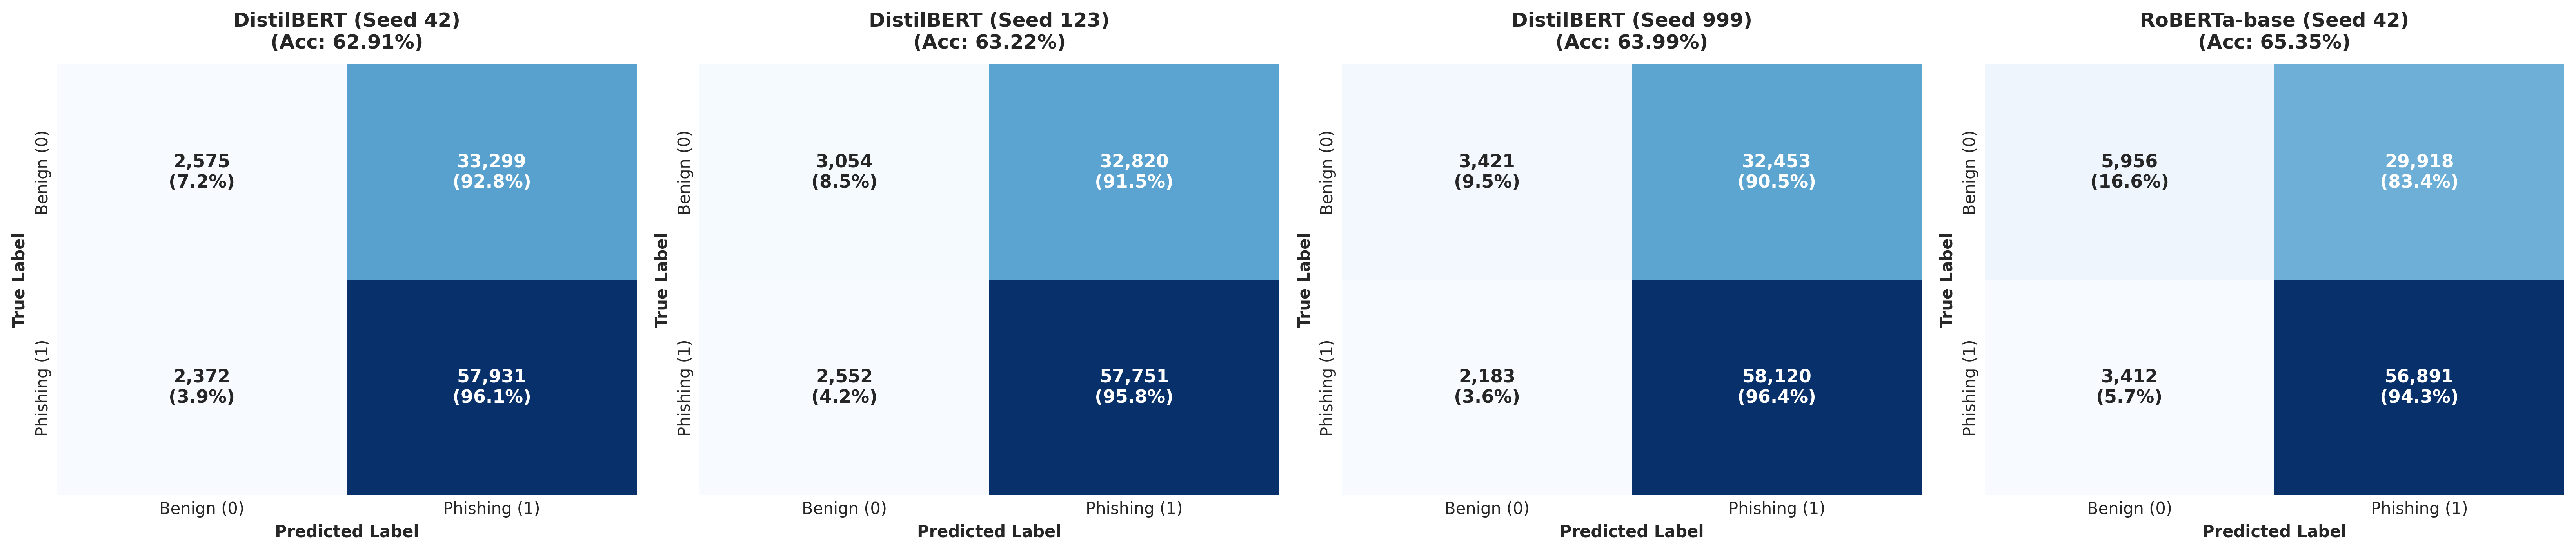

✅ Tersimpan: /content/drive/MyDrive/Skripsi/results/ext2_01_confusion_matrices.png


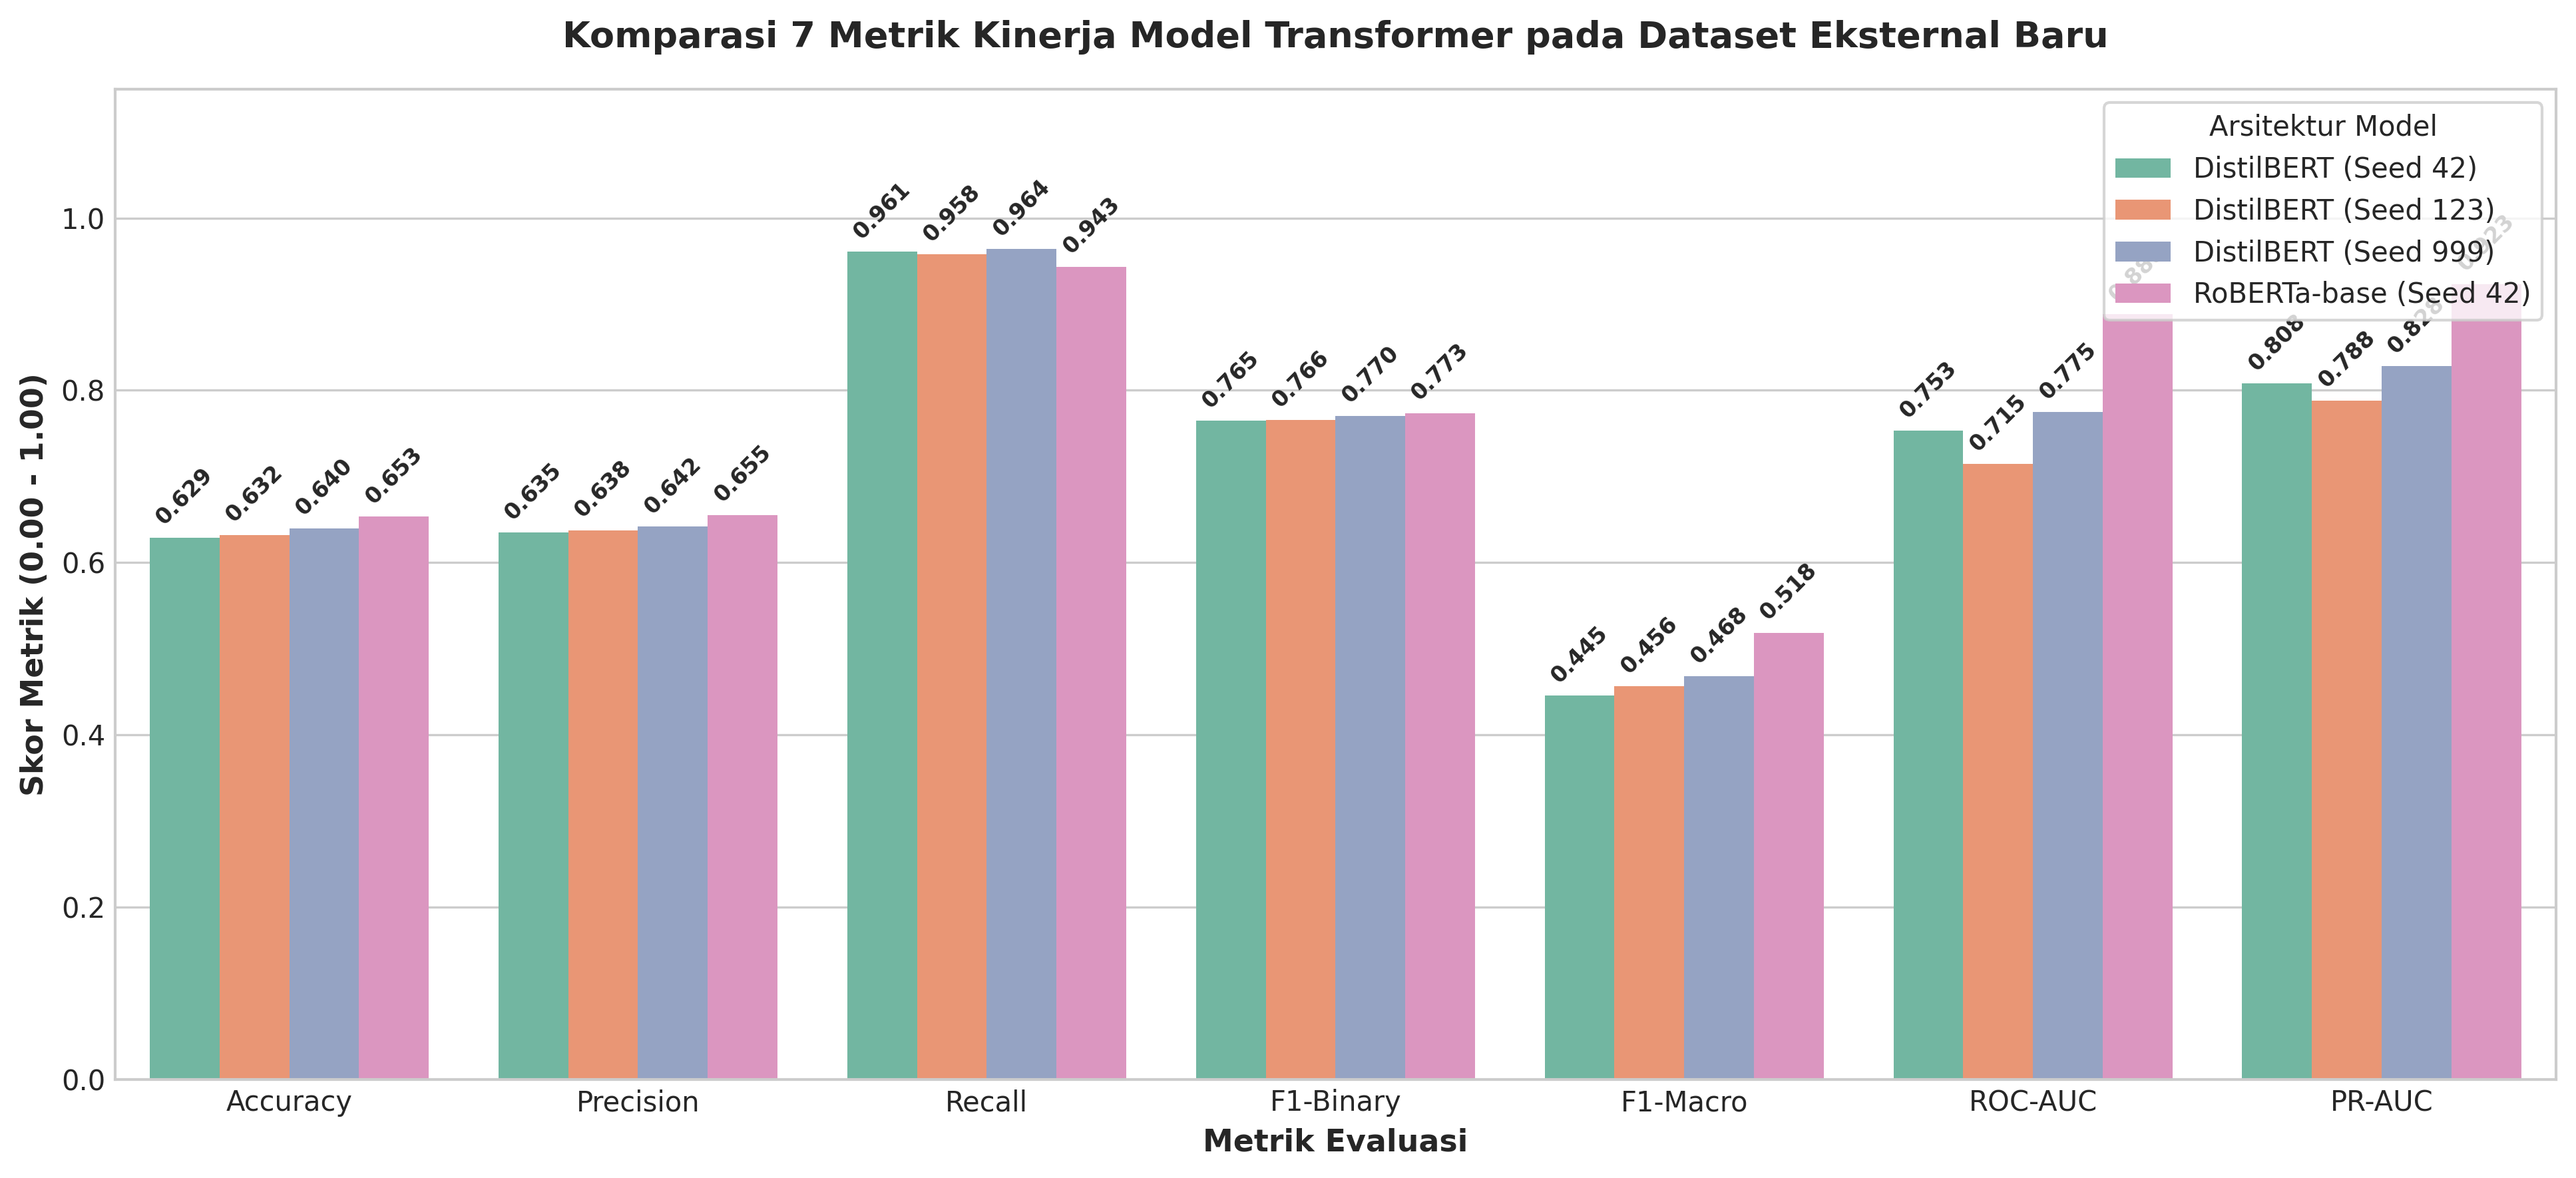

✅ Tersimpan: /content/drive/MyDrive/Skripsi/results/ext2_02_performance_metrics_bars.png


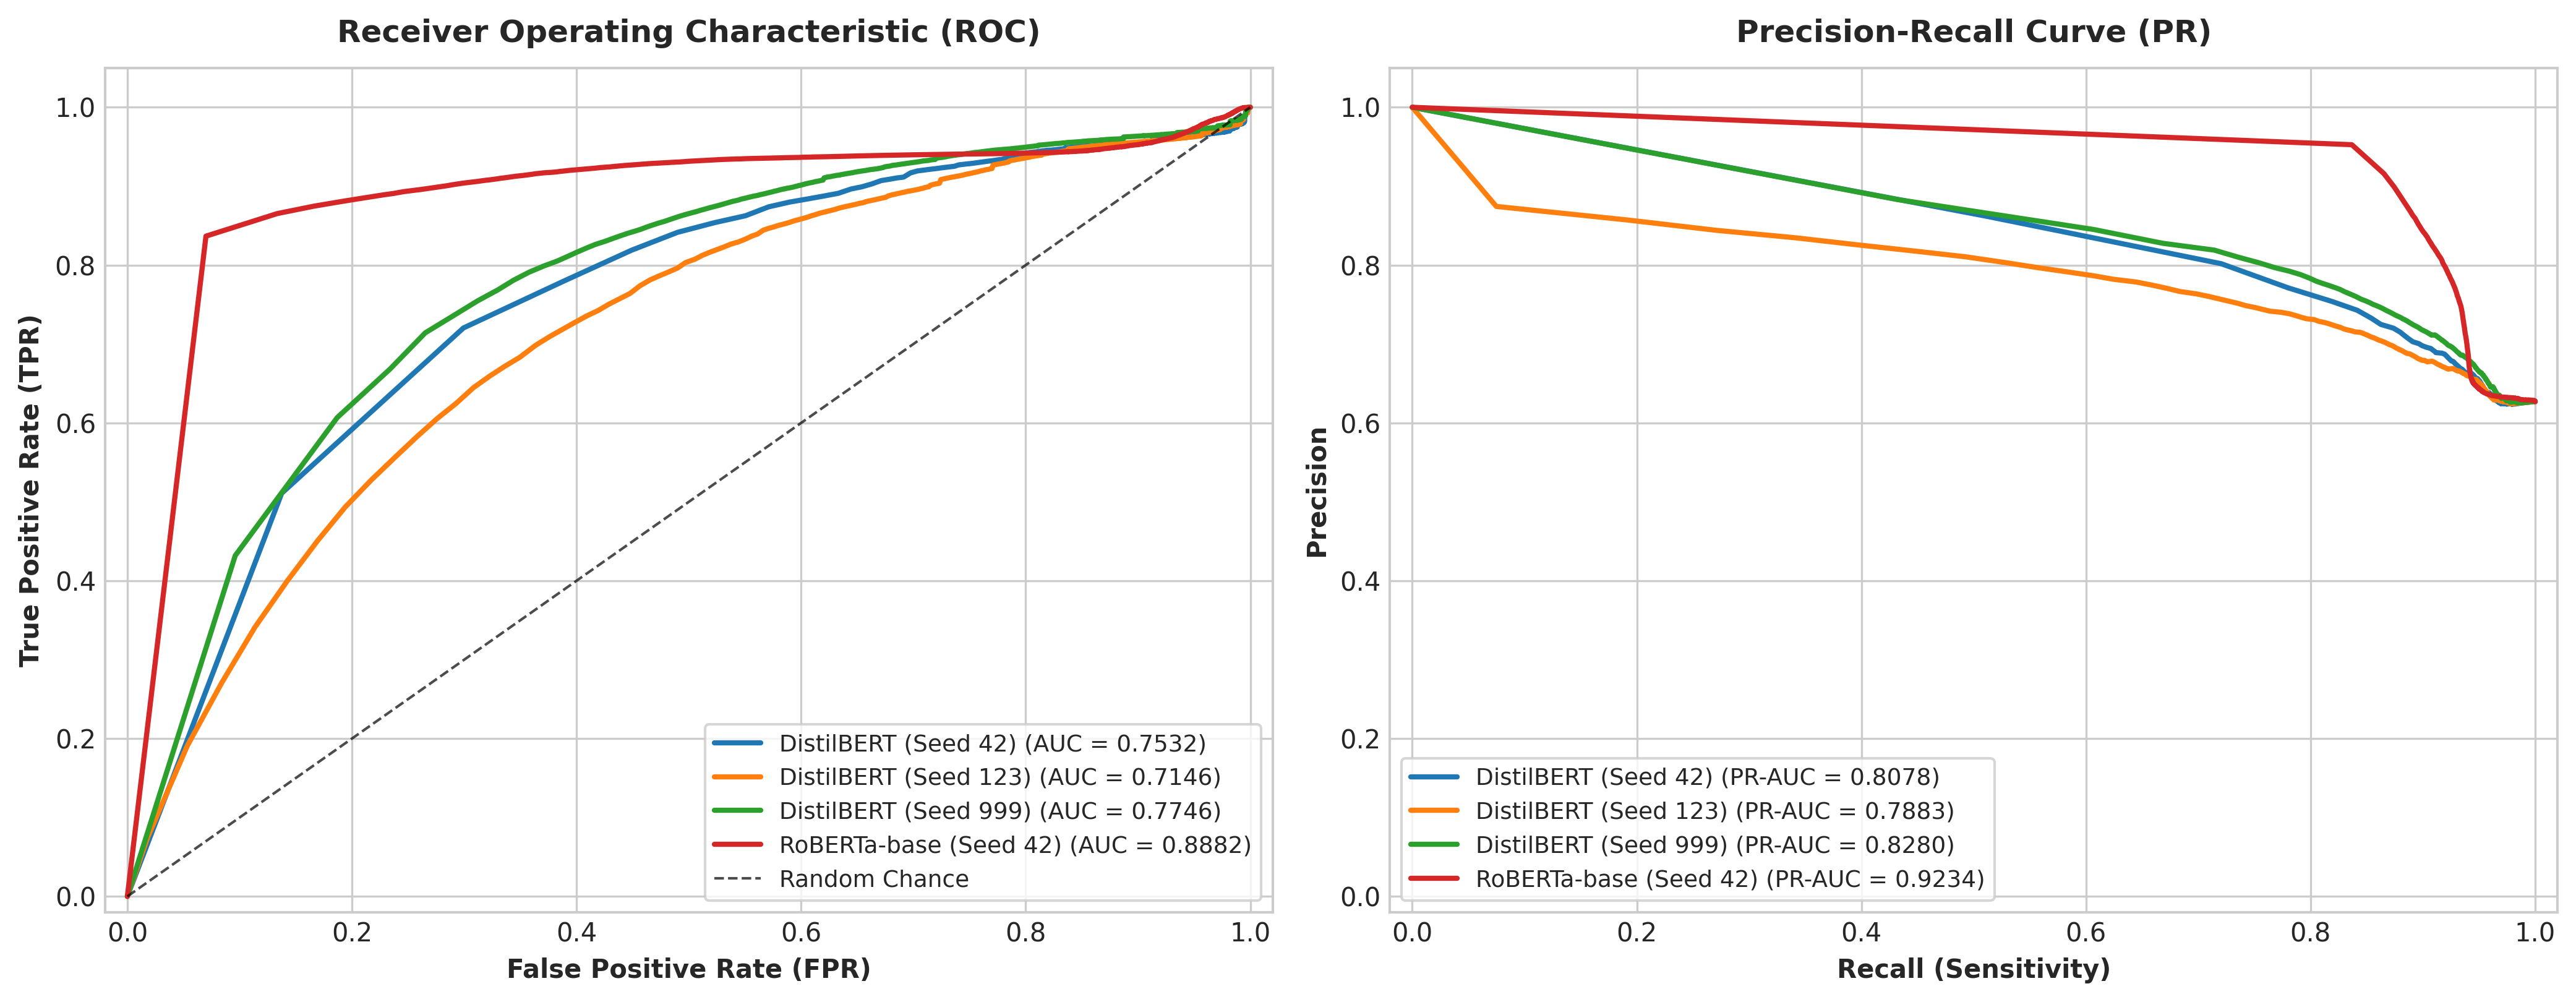

✅ Tersimpan: /content/drive/MyDrive/Skripsi/results/ext2_03_roc_and_pr_curves.png


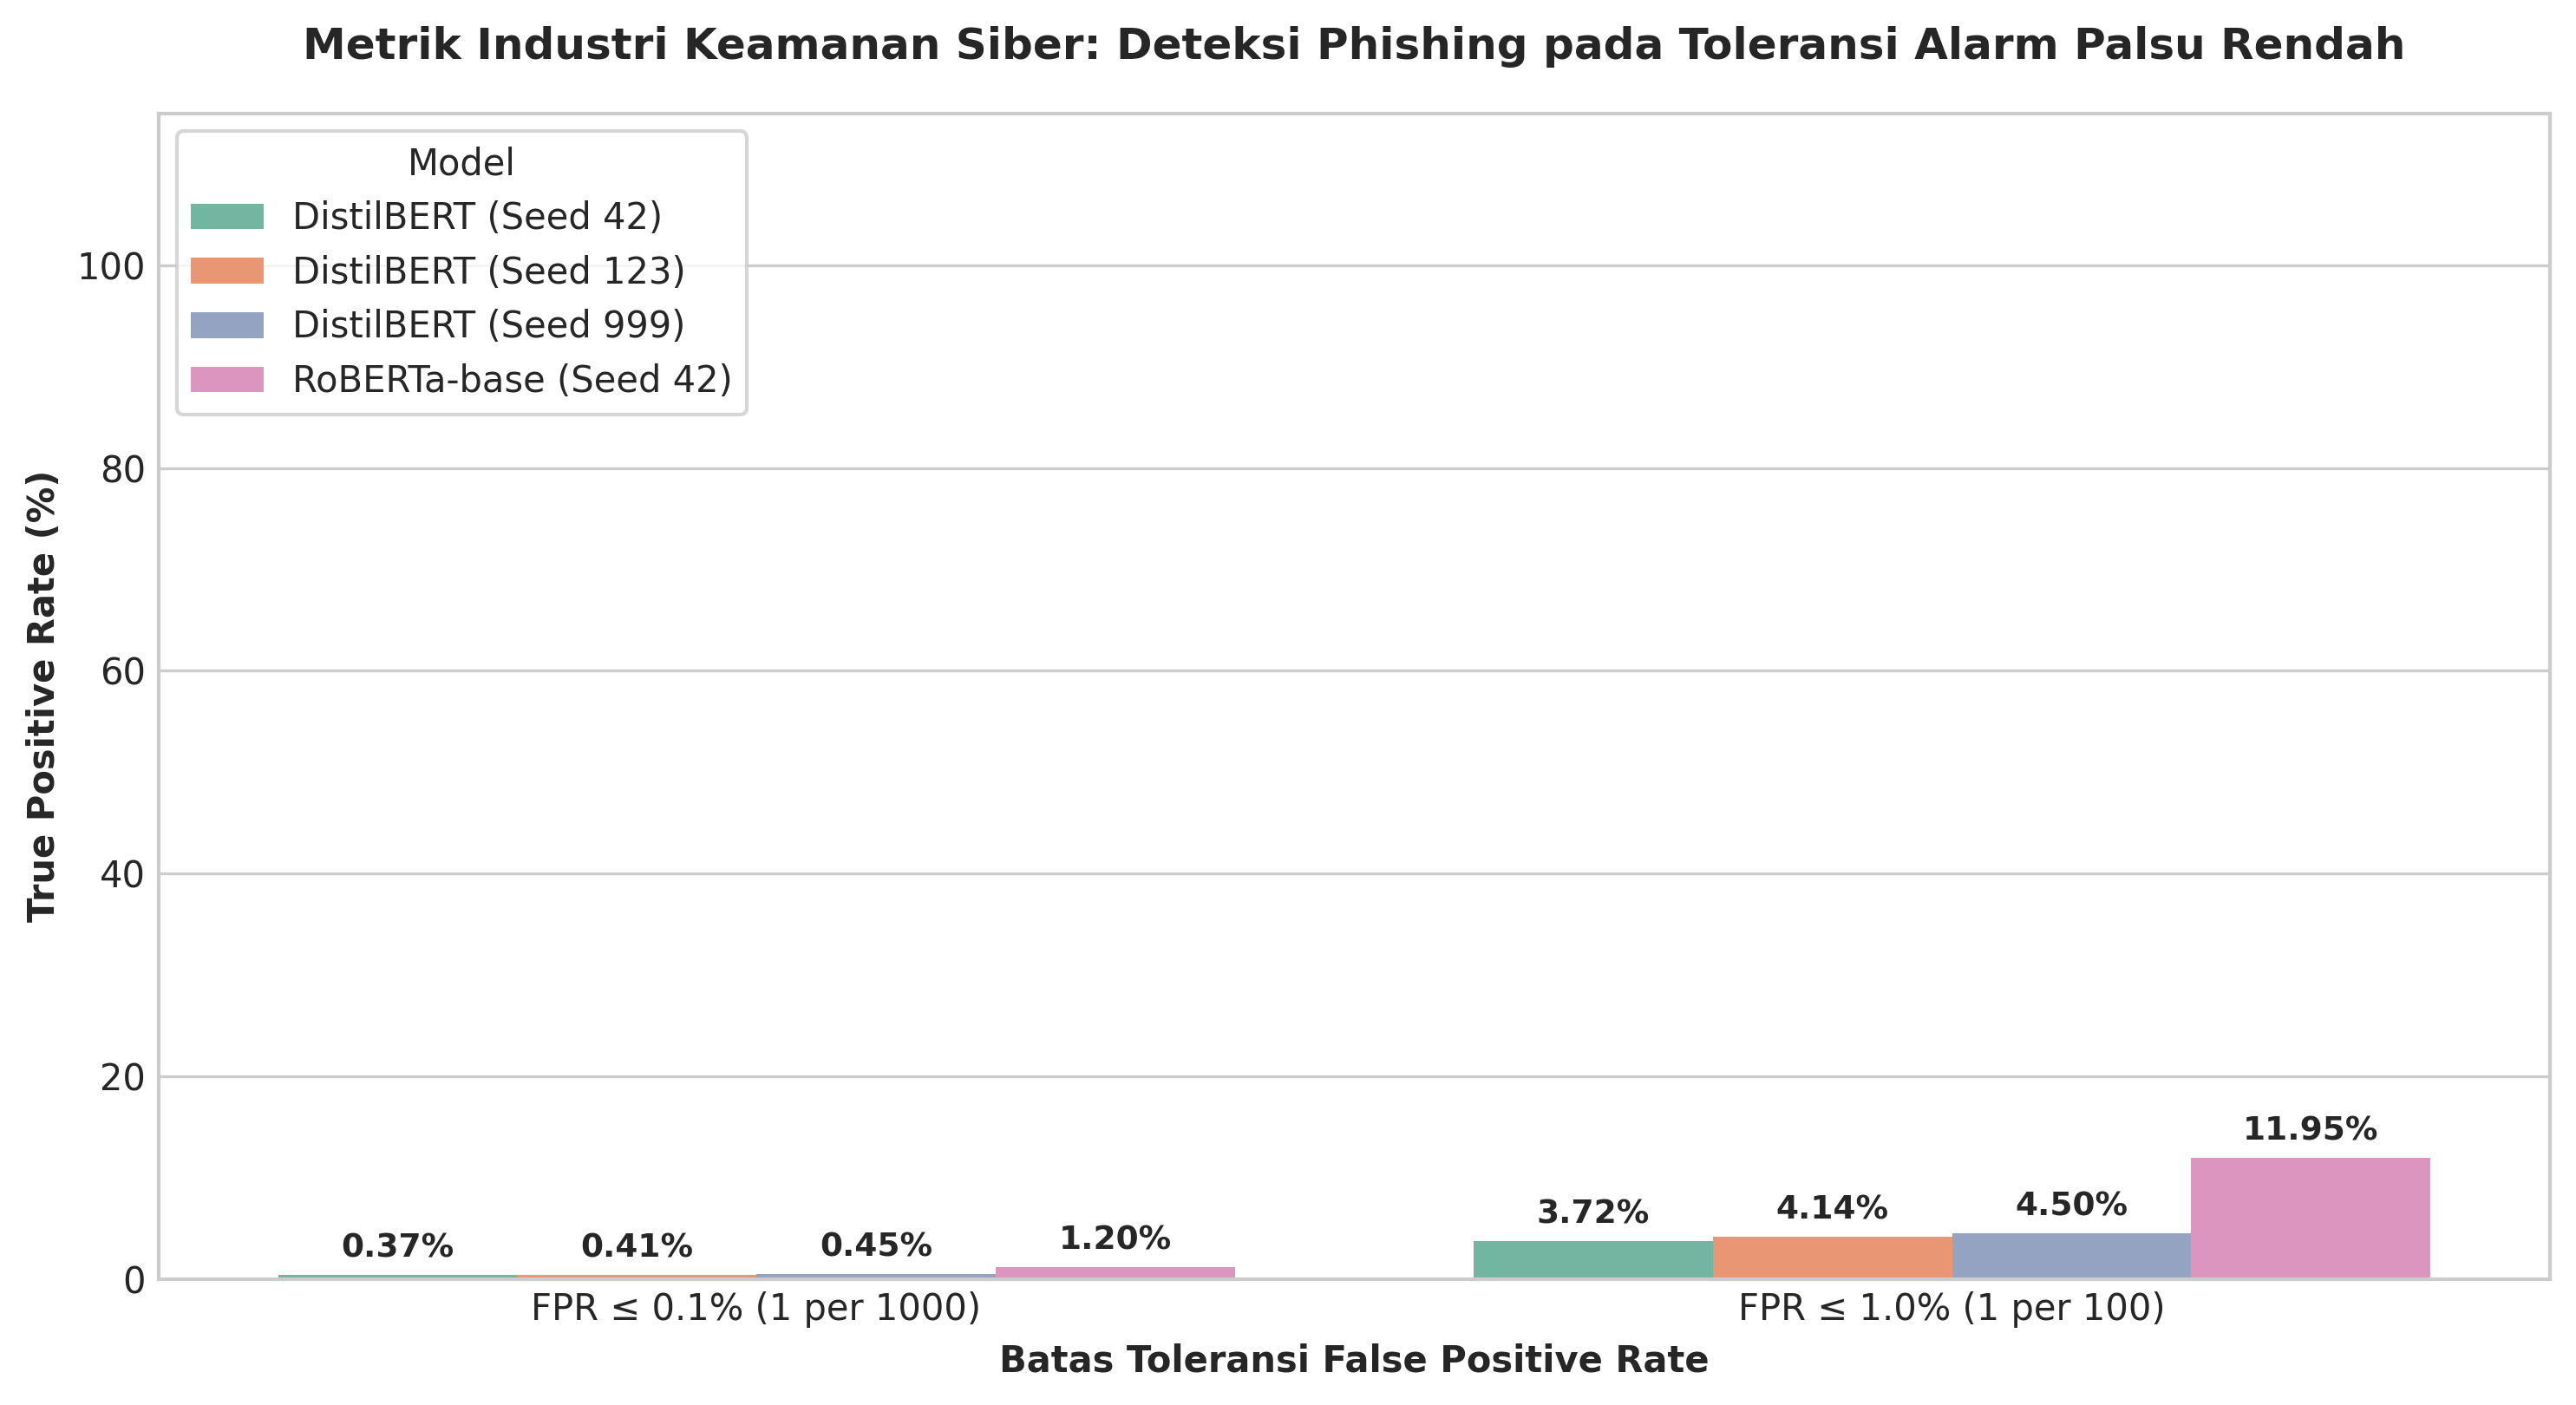

✅ Tersimpan: /content/drive/MyDrive/Skripsi/results/ext2_04_tpr_at_low_fpr_bars.png


In [12]:
print("[INFO] Membuat visualisasi komparatif 300 DPI (Plot 1 s.d. 4)...")
active_models = [m for m, v in all_model_results.items() if 'y_true' in v]

# ---------------------------------------------------------------------
# PLOT 1: Grid Confusion Matrices (Angka + Persentase Baris)
# ---------------------------------------------------------------------
n_models = len(active_models)
fig, axes = plt.subplots(1, n_models, figsize=(5.5 * n_models, 4.8), dpi=300)
if n_models == 1:
    axes = [axes]

for ax, m_name in zip(axes, active_models):
    cm = all_model_results[m_name]['confusion_matrix']
    cm_pct = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis] * 100

    annot_matrix = np.empty_like(cm, dtype=object)
    for i in range(2):
        for j in range(2):
            annot_matrix[i, j] = f"{cm[i, j]:,}\n({cm_pct[i, j]:.1f}%)"

    sns.heatmap(cm, annot=annot_matrix, fmt="", cmap="Blues", cbar=False, ax=ax,
                xticklabels=['Benign (0)', 'Phishing (1)'],
                yticklabels=['Benign (0)', 'Phishing (1)'],
                annot_kws={"fontsize": 11, "fontweight": "bold"})
    ax.set_title(f"{m_name}\n(Acc: {all_model_results[m_name]['accuracy']*100:.2f}%)", fontsize=12, fontweight='bold', pad=10)
    ax.set_xlabel("Predicted Label", fontsize=10, fontweight='bold')
    ax.set_ylabel("True Label", fontsize=10, fontweight='bold')

plt.tight_layout()
p1_path = os.path.join(RESULTS_DIR, "ext2_01_confusion_matrices.png")
plt.savefig(p1_path, dpi=300, bbox_inches='tight')
plt.show()
print(f"✅ Tersimpan: {p1_path}")

# ---------------------------------------------------------------------
# PLOT 2: Performance Metrics Bars (7 Metrik Utama)
# ---------------------------------------------------------------------
metrics_names = ['accuracy', 'precision', 'recall', 'f1_binary', 'f1_macro', 'roc_auc', 'pr_auc']
metrics_labels = ['Accuracy', 'Precision', 'Recall', 'F1-Binary', 'F1-Macro', 'ROC-AUC', 'PR-AUC']

plot2_data = []
for m_name in active_models:
    for k_m, l_m in zip(metrics_names, metrics_labels):
        plot2_data.append({'Model': m_name, 'Metrik': l_m, 'Nilai': all_model_results[m_name][k_m]})

df_plot2 = pd.DataFrame(plot2_data)

plt.figure(figsize=(13, 6), dpi=300)
palette = sns.color_palette("Set2", len(active_models))
ax = sns.barplot(data=df_plot2, x='Metrik', y='Nilai', hue='Model', palette=palette)

plt.title("Komparasi 7 Metrik Kinerja Model Transformer pada Dataset Eksternal Baru", fontsize=13, fontweight='bold', pad=15)
plt.ylabel("Skor Metrik (0.00 - 1.00)", fontsize=11, fontweight='bold')
plt.xlabel("Metrik Evaluasi", fontsize=11, fontweight='bold')
plt.ylim(0.0, 1.15)
plt.legend(title="Arsitektur Model", frameon=True, facecolor='white', loc='upper right')

for p in ax.patches:
    h = p.get_height()
    if h > 0 and not np.isnan(h):
        ax.annotate(f"{h:.3f}", (p.get_x() + p.get_width() / 2., h),
                    ha='center', va='bottom', fontsize=8, fontweight='bold', xytext=(0, 3),
                    textcoords='offset points', rotation=45)

plt.tight_layout()
p2_path = os.path.join(RESULTS_DIR, "ext2_02_performance_metrics_bars.png")
plt.savefig(p2_path, dpi=300, bbox_inches='tight')
plt.show()
print(f"✅ Tersimpan: {p2_path}")

# ---------------------------------------------------------------------
# PLOT 3: ROC & PR Curves Berdampingan
# ---------------------------------------------------------------------
fig, (ax_roc, ax_pr) = plt.subplots(1, 2, figsize=(14, 5.5), dpi=300)
colors = sns.color_palette("tab10", len(active_models))

for m_name, col in zip(active_models, colors):
    y_t = all_model_results[m_name]['y_true']
    y_p = all_model_results[m_name]['y_prob']

    # ROC Curve
    fpr, tpr, _ = roc_curve(y_t, y_p)
    auc_val = all_model_results[m_name]['roc_auc']
    ax_roc.plot(fpr, tpr, label=f"{m_name} (AUC = {auc_val:.4f})", color=col, lw=2)

    # PR Curve
    prec, rec, _ = precision_recall_curve(y_t, y_p)
    pr_auc_val = all_model_results[m_name]['pr_auc']
    ax_pr.plot(rec, prec, label=f"{m_name} (PR-AUC = {pr_auc_val:.4f})", color=col, lw=2)

# Styling ROC
ax_roc.plot([0, 1], [0, 1], 'k--', lw=1, alpha=0.7, label='Random Chance')
ax_roc.set_title("Receiver Operating Characteristic (ROC)", fontsize=12, fontweight='bold', pad=10)
ax_roc.set_xlabel("False Positive Rate (FPR)", fontsize=10, fontweight='bold')
ax_roc.set_ylabel("True Positive Rate (TPR)", fontsize=10, fontweight='bold')
ax_roc.set_xlim(-0.02, 1.02)
ax_roc.set_ylim(-0.02, 1.05)
ax_roc.legend(loc='lower right', frameon=True, fontsize=9)

# Styling PR
ax_pr.set_title("Precision-Recall Curve (PR)", fontsize=12, fontweight='bold', pad=10)
ax_pr.set_xlabel("Recall (Sensitivity)", fontsize=10, fontweight='bold')
ax_pr.set_ylabel("Precision", fontsize=10, fontweight='bold')
ax_pr.set_xlim(-0.02, 1.02)
ax_pr.set_ylim(-0.02, 1.05)
ax_pr.legend(loc='lower left', frameon=True, fontsize=9)

plt.tight_layout()
p3_path = os.path.join(RESULTS_DIR, "ext2_03_roc_and_pr_curves.png")
plt.savefig(p3_path, dpi=300, bbox_inches='tight')
plt.show()
print(f"✅ Tersimpan: {p3_path}")

# ---------------------------------------------------------------------
# PLOT 4: TPR at Low FPR Bars (<=0.1% dan <=1.0%)
# ---------------------------------------------------------------------
tpr_rows = []
for m_name in active_models:
    tpr_rows.append({'Model': m_name, 'Toleransi FPR': 'FPR ≤ 0.1% (1 per 1000)', 'TPR (%)': all_model_results[m_name]['tpr_at_fpr_0.1pct'] * 100})
    tpr_rows.append({'Model': m_name, 'Toleransi FPR': 'FPR ≤ 1.0% (1 per 100)', 'TPR (%)': all_model_results[m_name]['tpr_at_fpr_1.0pct'] * 100})

df_tpr = pd.DataFrame(tpr_rows)

plt.figure(figsize=(10, 5.5), dpi=300)
ax = sns.barplot(data=df_tpr, x='Toleransi FPR', y='TPR (%)', hue='Model', palette="Set2")
plt.title("Metrik Industri Keamanan Siber: Deteksi Phishing pada Toleransi Alarm Palsu Rendah", fontsize=12, fontweight='bold', pad=15)
plt.ylabel("True Positive Rate (%)", fontsize=10, fontweight='bold')
plt.xlabel("Batas Toleransi False Positive Rate", fontsize=10, fontweight='bold')
plt.ylim(0, 115)
plt.legend(title="Model", frameon=True, loc='upper left')

for p in ax.patches:
    h = p.get_height()
    if h > 0 and not np.isnan(h):
        ax.annotate(f"{h:.2f}%", (p.get_x() + p.get_width() / 2., h),
                    ha='center', va='bottom', fontsize=9, fontweight='bold', xytext=(0, 3),
                    textcoords='offset points')

plt.tight_layout()
p4_path = os.path.join(RESULTS_DIR, "ext2_04_tpr_at_low_fpr_bars.png")
plt.savefig(p4_path, dpi=300, bbox_inches='tight')
plt.show()
print(f"✅ Tersimpan: {p4_path}")

[INFO] Membuat visualisasi efisiensi dan distribusi probabilitas (Plot 5 s.d. 7)...


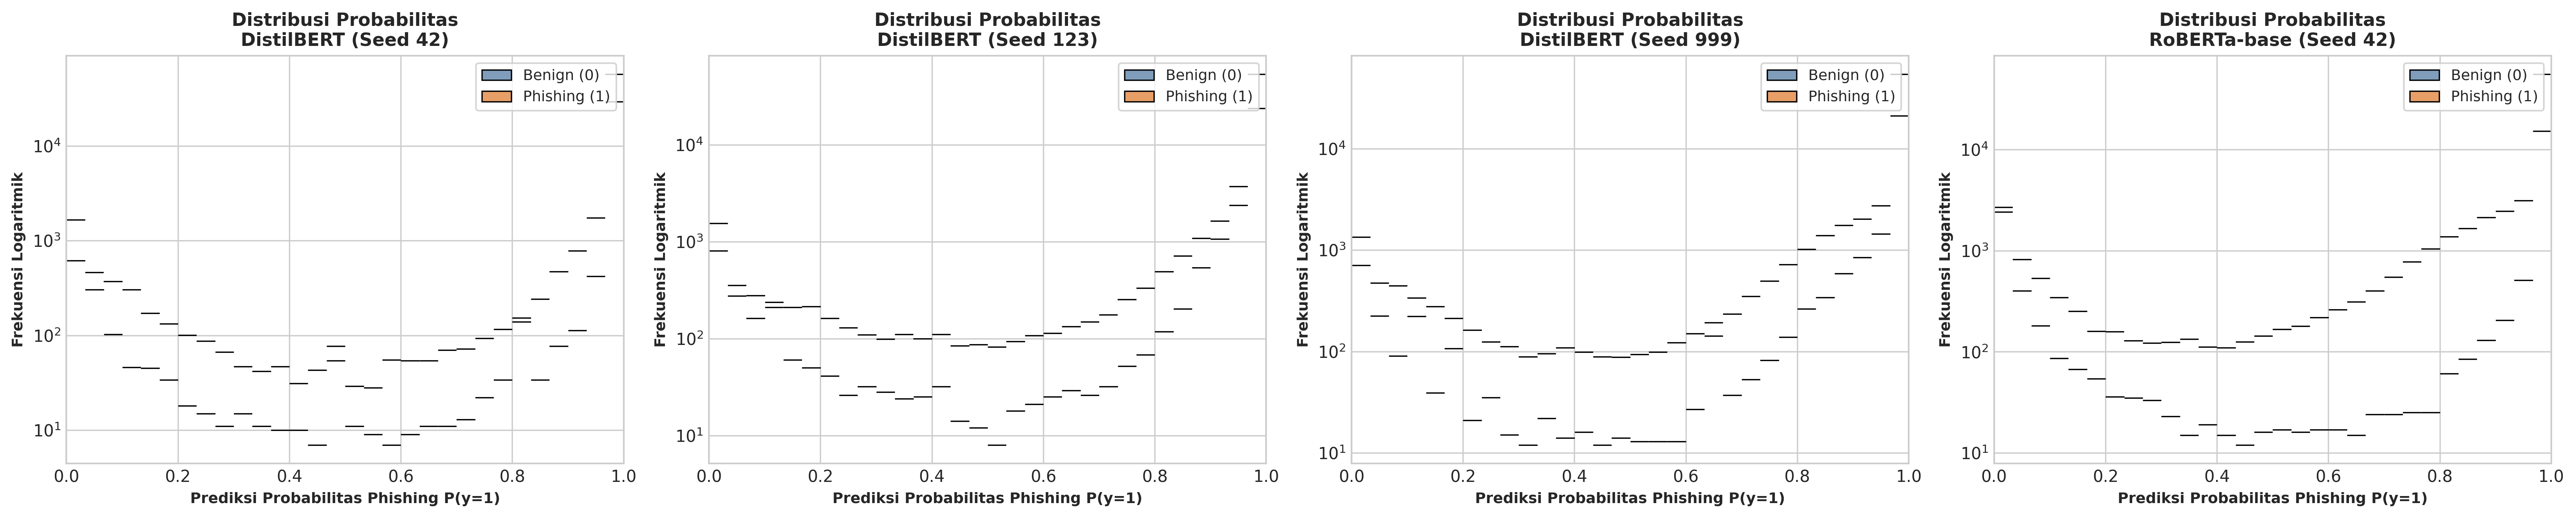

✅ Tersimpan: /content/drive/MyDrive/Skripsi/results/ext2_05_confidence_distribution.png


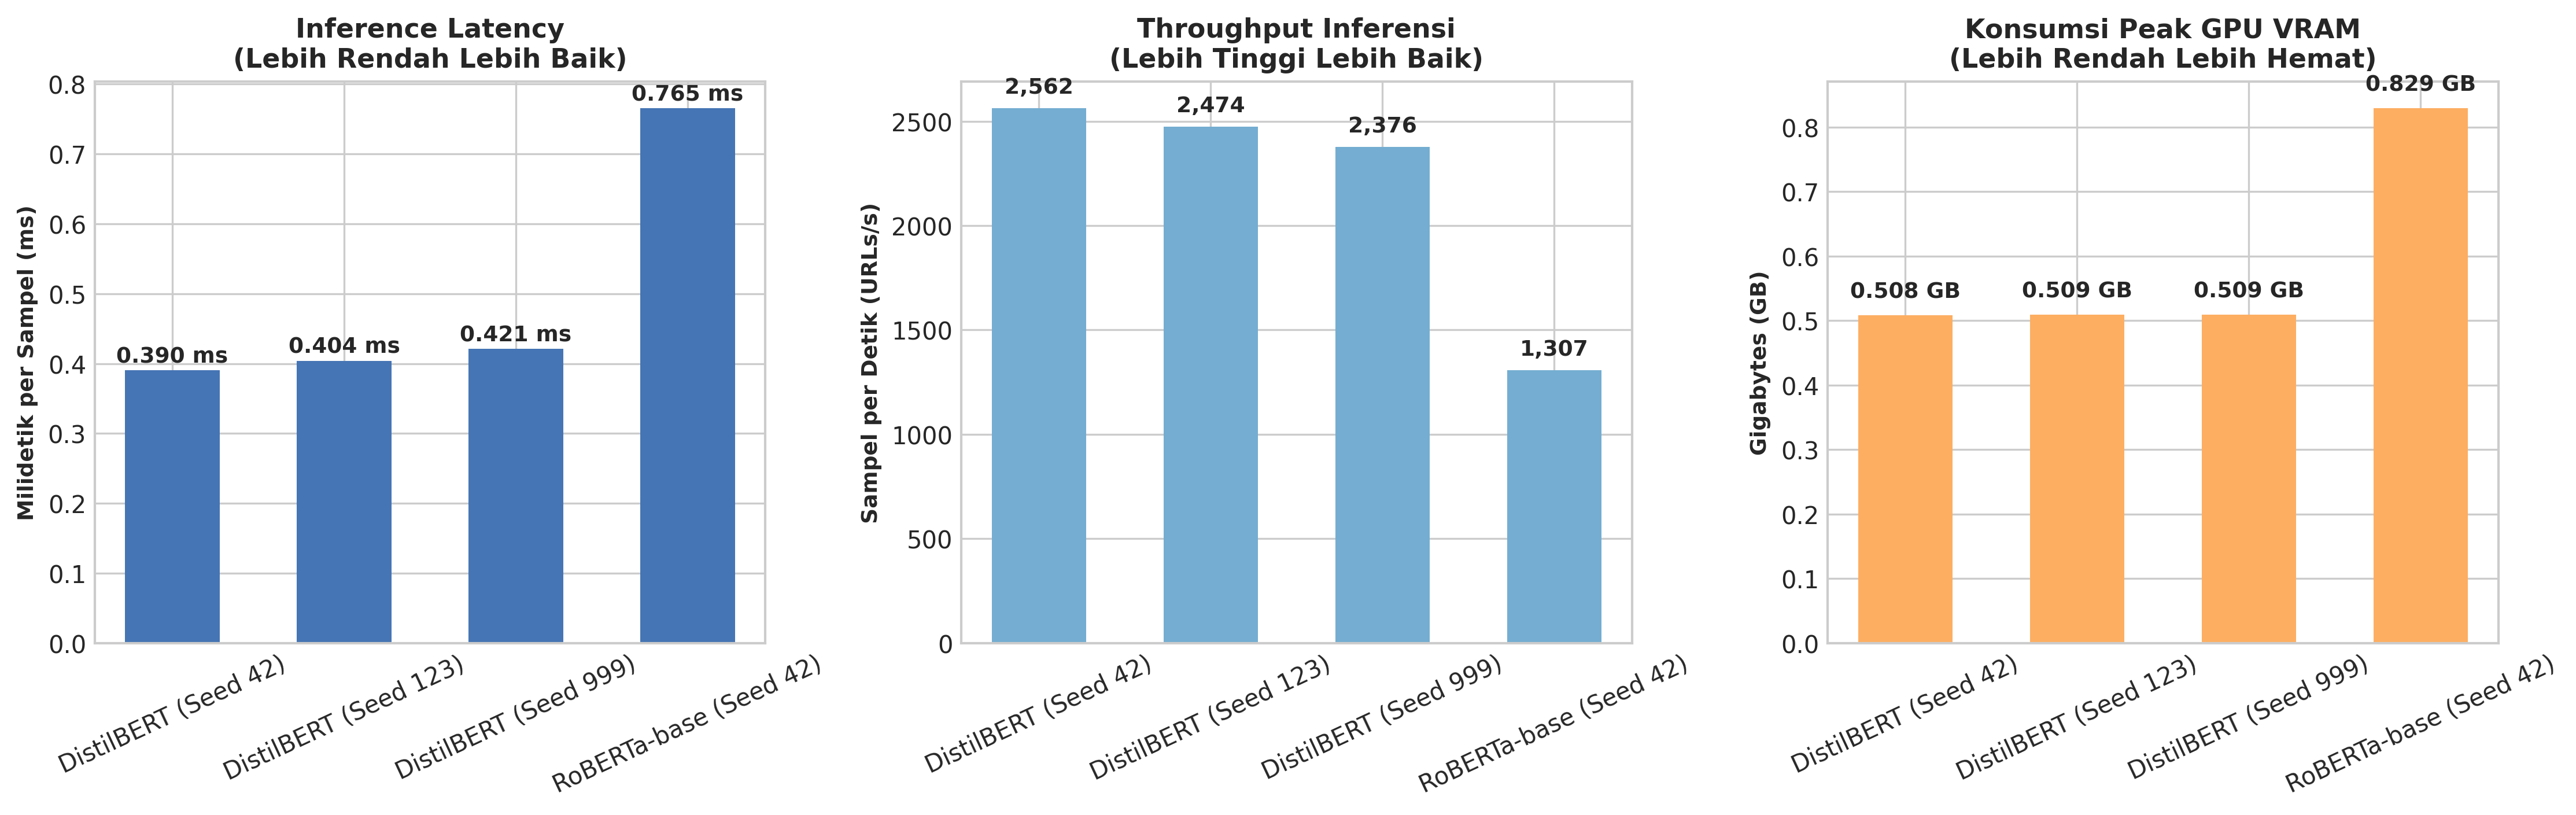

✅ Tersimpan: /content/drive/MyDrive/Skripsi/results/ext2_06_efficiency_comparison.png


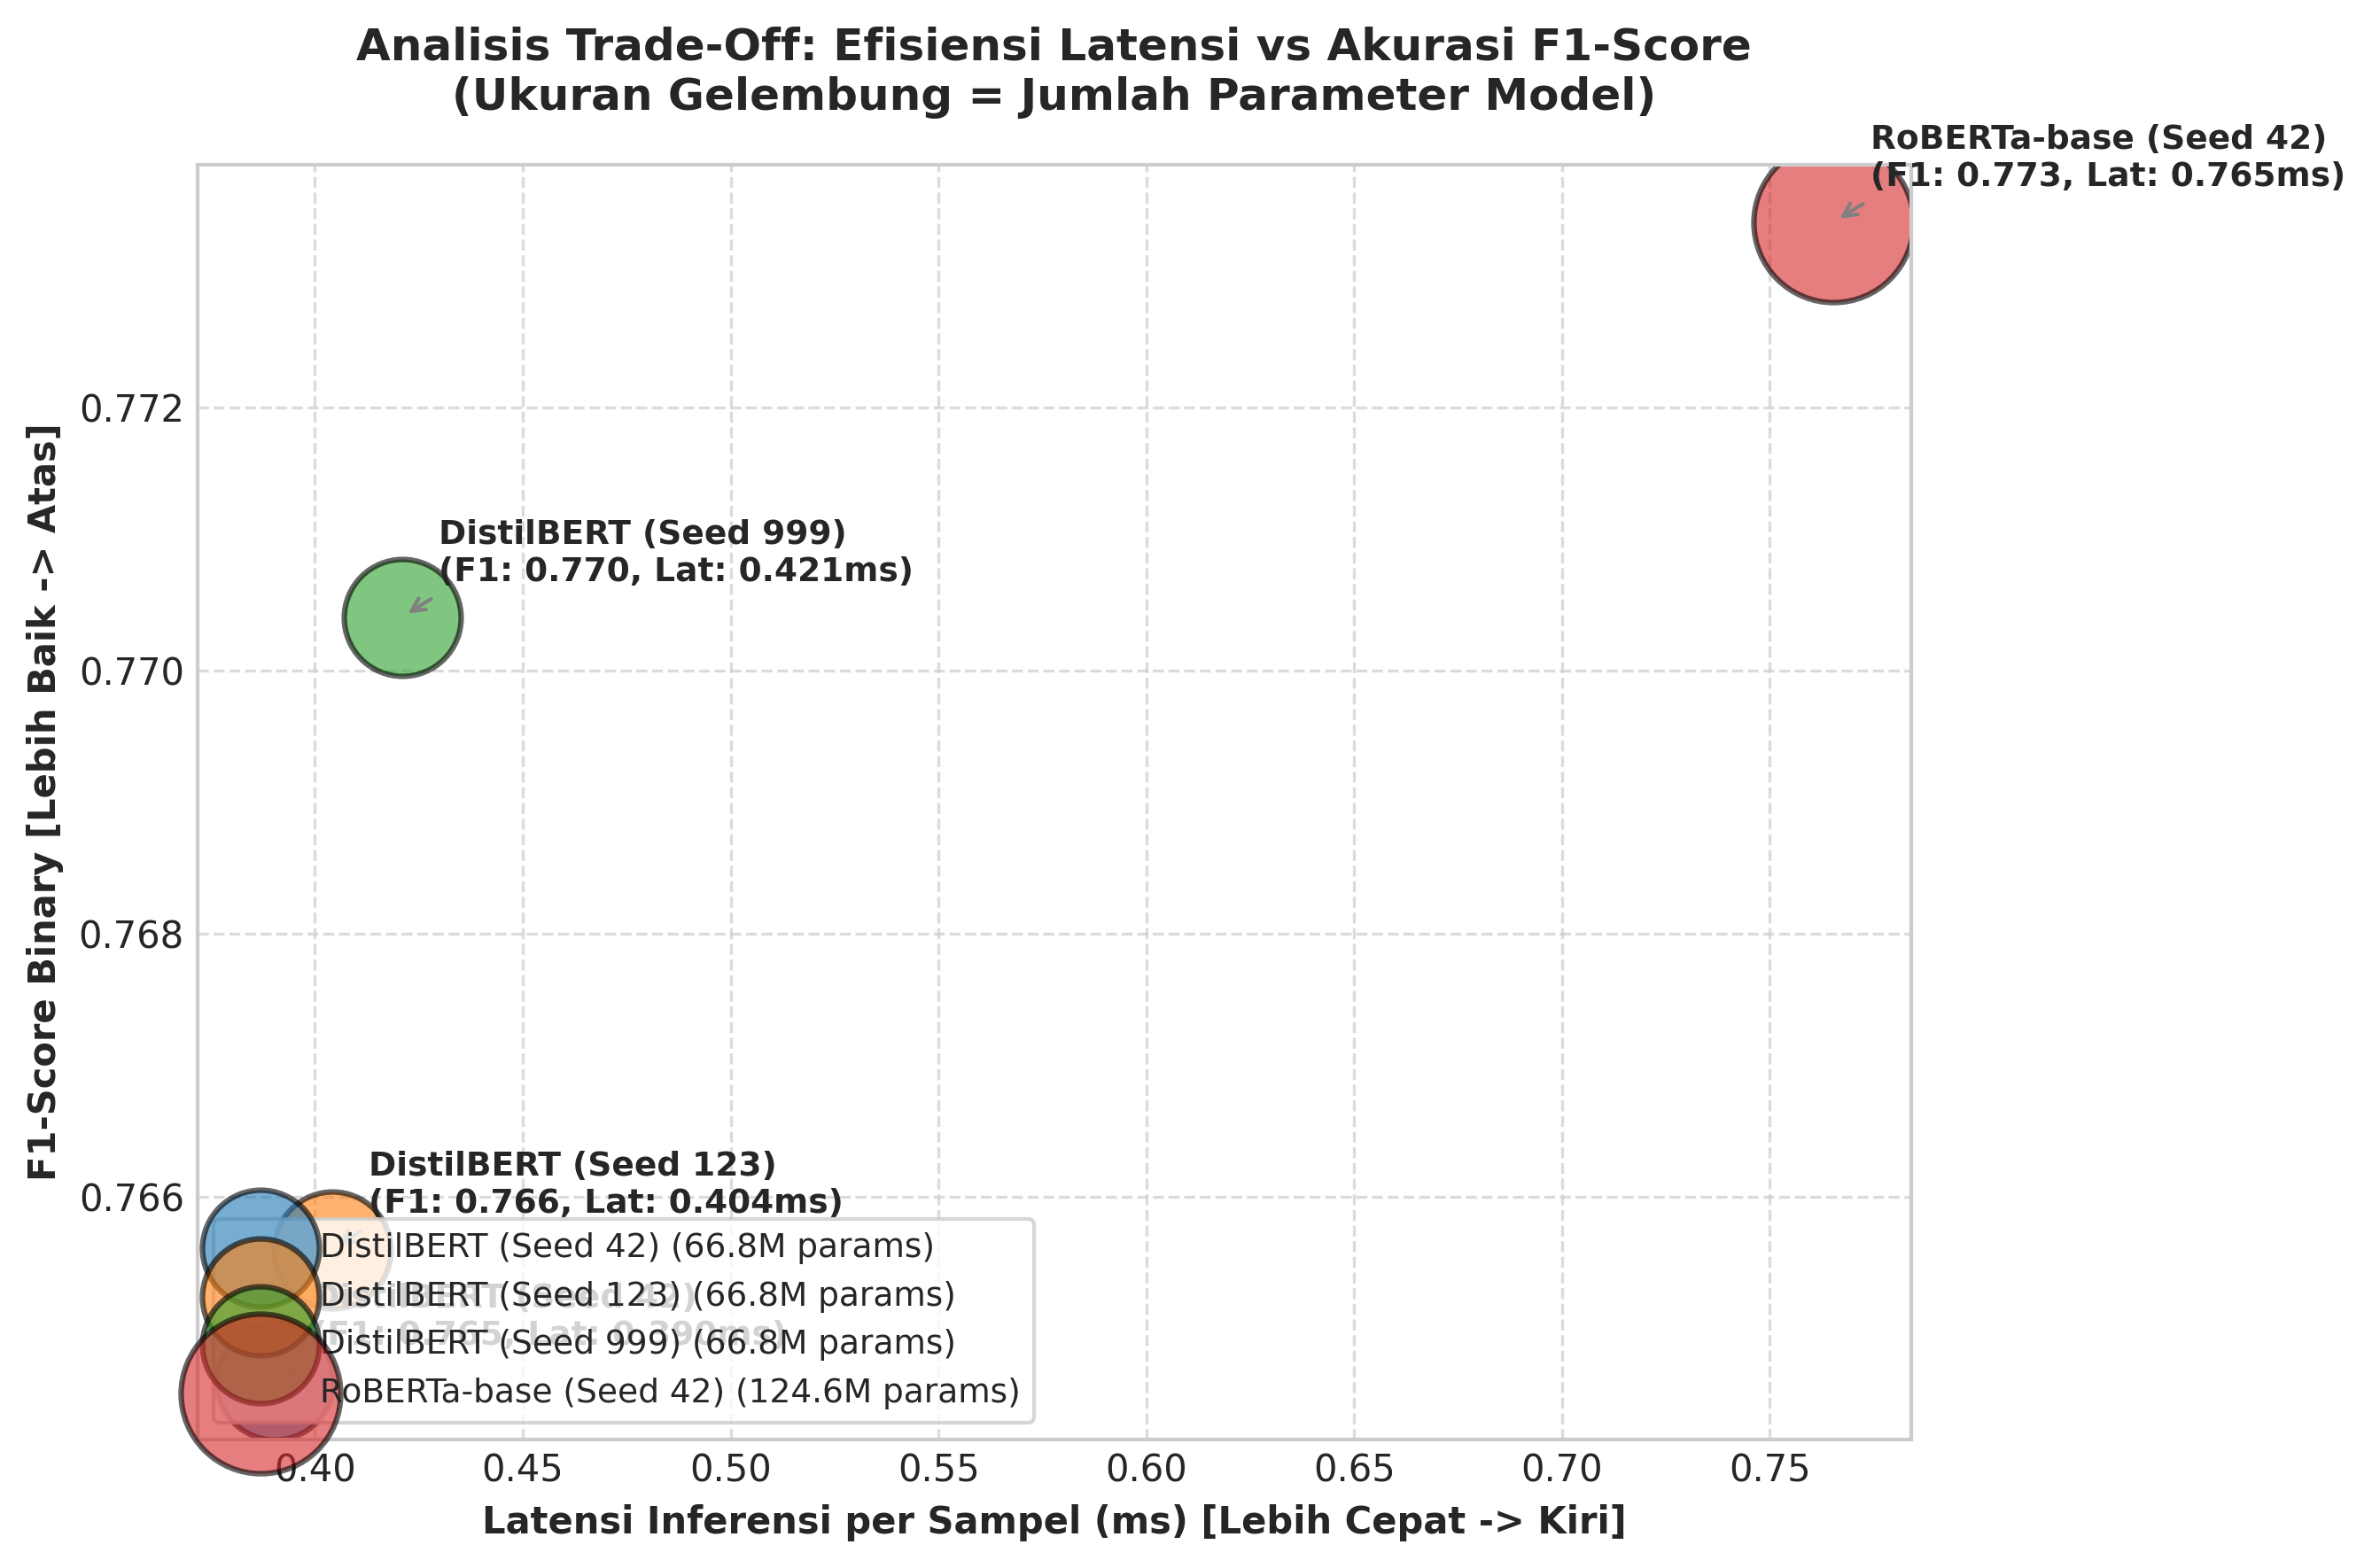

✅ Tersimpan: /content/drive/MyDrive/Skripsi/results/ext2_07_tradeoff_bubble_plot.png


In [13]:
print("[INFO] Membuat visualisasi efisiensi dan distribusi probabilitas (Plot 5 s.d. 7)...")

# ---------------------------------------------------------------------
# PLOT 5: Histogram Distribusi Probabilitas Prediksi (Log-Scale)
# ---------------------------------------------------------------------
fig, axes = plt.subplots(1, n_models, figsize=(5.5 * n_models, 4.5), dpi=300)
if n_models == 1:
    axes = [axes]

for ax, m_name in zip(axes, active_models):
    y_t = all_model_results[m_name]['y_true']
    y_p = all_model_results[m_name]['y_prob']

    sns.histplot(y_p[y_t == 0], bins=30, color='#2b5c8f', label='Benign (0)', ax=ax, alpha=0.6, log_scale=(False, True))
    sns.histplot(y_p[y_t == 1], bins=30, color='#d95f02', label='Phishing (1)', ax=ax, alpha=0.6, log_scale=(False, True))

    ax.set_title(f"Distribusi Probabilitas\n{m_name}", fontsize=11, fontweight='bold')
    ax.set_xlabel("Prediksi Probabilitas Phishing P(y=1)", fontsize=9, fontweight='bold')
    ax.set_ylabel("Frekuensi Logaritmik", fontsize=9, fontweight='bold')
    ax.set_xlim(0, 1)
    ax.legend(frameon=True, fontsize=9)

plt.tight_layout()
p5_path = os.path.join(RESULTS_DIR, "ext2_05_confidence_distribution.png")
plt.savefig(p5_path, dpi=300, bbox_inches='tight')
plt.show()
print(f"✅ Tersimpan: {p5_path}")

# ---------------------------------------------------------------------
# PLOT 6: Efficiency Comparison (Latensi, Throughput, Peak VRAM)
# ---------------------------------------------------------------------
fig, (ax_lat, ax_tp, ax_vram) = plt.subplots(1, 3, figsize=(15, 4.8), dpi=300)

models_eff = active_models
lat_vals = [all_model_results[m]['latency_ms'] for m in models_eff]
tp_vals = [all_model_results[m]['throughput_sps'] for m in models_eff]
vram_vals = [all_model_results[m]['peak_vram_gb'] for m in models_eff]

# Latency
ax_lat.bar(models_eff, lat_vals, color='#4575b4', width=0.55)
ax_lat.set_title("Inference Latency\n(Lebih Rendah Lebih Baik)", fontsize=11, fontweight='bold')
ax_lat.set_ylabel("Milidetik per Sampel (ms)", fontsize=9, fontweight='bold')
ax_lat.tick_params(axis='x', rotation=25)
for i, v in enumerate(lat_vals):
    ax_lat.text(i, v + 0.005, f"{v:.3f} ms", ha='center', va='bottom', fontsize=9, fontweight='bold')

# Throughput
ax_tp.bar(models_eff, tp_vals, color='#74add1', width=0.55)
ax_tp.set_title("Throughput Inferensi\n(Lebih Tinggi Lebih Baik)", fontsize=11, fontweight='bold')
ax_tp.set_ylabel("Sampel per Detik (URLs/s)", fontsize=9, fontweight='bold')
ax_tp.tick_params(axis='x', rotation=25)
for i, v in enumerate(tp_vals):
    ax_tp.text(i, v + 50, f"{v:,.0f}", ha='center', va='bottom', fontsize=9, fontweight='bold')

# Peak VRAM
ax_vram.bar(models_eff, vram_vals, color='#fdae61', width=0.55)
ax_vram.set_title("Konsumsi Peak GPU VRAM\n(Lebih Rendah Lebih Hemat)", fontsize=11, fontweight='bold')
ax_vram.set_ylabel("Gigabytes (GB)", fontsize=9, fontweight='bold')
ax_vram.tick_params(axis='x', rotation=25)
for i, v in enumerate(vram_vals):
    ax_vram.text(i, v + 0.02, f"{v:.3f} GB", ha='center', va='bottom', fontsize=9, fontweight='bold')

plt.tight_layout()
p6_path = os.path.join(RESULTS_DIR, "ext2_06_efficiency_comparison.png")
plt.savefig(p6_path, dpi=300, bbox_inches='tight')
plt.show()
print(f"✅ Tersimpan: {p6_path}")

# ---------------------------------------------------------------------
# PLOT 7: Trade-off Bubble Plot (Latensi vs F1-Score)
# ---------------------------------------------------------------------
plt.figure(figsize=(9, 6), dpi=300)

for m_name in active_models:
    lat = all_model_results[m_name]['latency_ms']
    f1 = all_model_results[m_name]['f1_binary']
    params = all_model_results[m_name]['total_params']
    bubble_size = (params / 1e6) * 15  # Skala ukuran gelembung

    plt.scatter(lat, f1, s=bubble_size, alpha=0.6, edgecolors='black', linewidth=1.5, label=f"{m_name} ({params/1e6:.1f}M params)")
    plt.annotate(f"{m_name}\n(F1: {f1:.3f}, Lat: {lat:.3f}ms)", (lat, f1),
                 xytext=(10, 10), textcoords='offset points', fontsize=9, fontweight='bold',
                 arrowprops=dict(arrowstyle="->", connectionstyle="arc3,rad=.2", color='gray'))

plt.title("Analisis Trade-Off: Efisiensi Latensi vs Akurasi F1-Score\n(Ukuran Gelembung = Jumlah Parameter Model)", fontsize=12, fontweight='bold', pad=15)
plt.xlabel("Latensi Inferensi per Sampel (ms) [Lebih Cepat -> Kiri]", fontsize=10, fontweight='bold')
plt.ylabel("F1-Score Binary [Lebih Baik -> Atas]", fontsize=10, fontweight='bold')
plt.grid(True, linestyle='--', alpha=0.7)
plt.legend(frameon=True, loc='lower left', fontsize=9)

plt.tight_layout()
p7_path = os.path.join(RESULTS_DIR, "ext2_07_tradeoff_bubble_plot.png")
plt.savefig(p7_path, dpi=300, bbox_inches='tight')
plt.show()
print(f"✅ Tersimpan: {p7_path}")

[INFO] Membuat visualisasi analisis peningkatan dan kalibrasi (Plot 8 s.d. 12)...


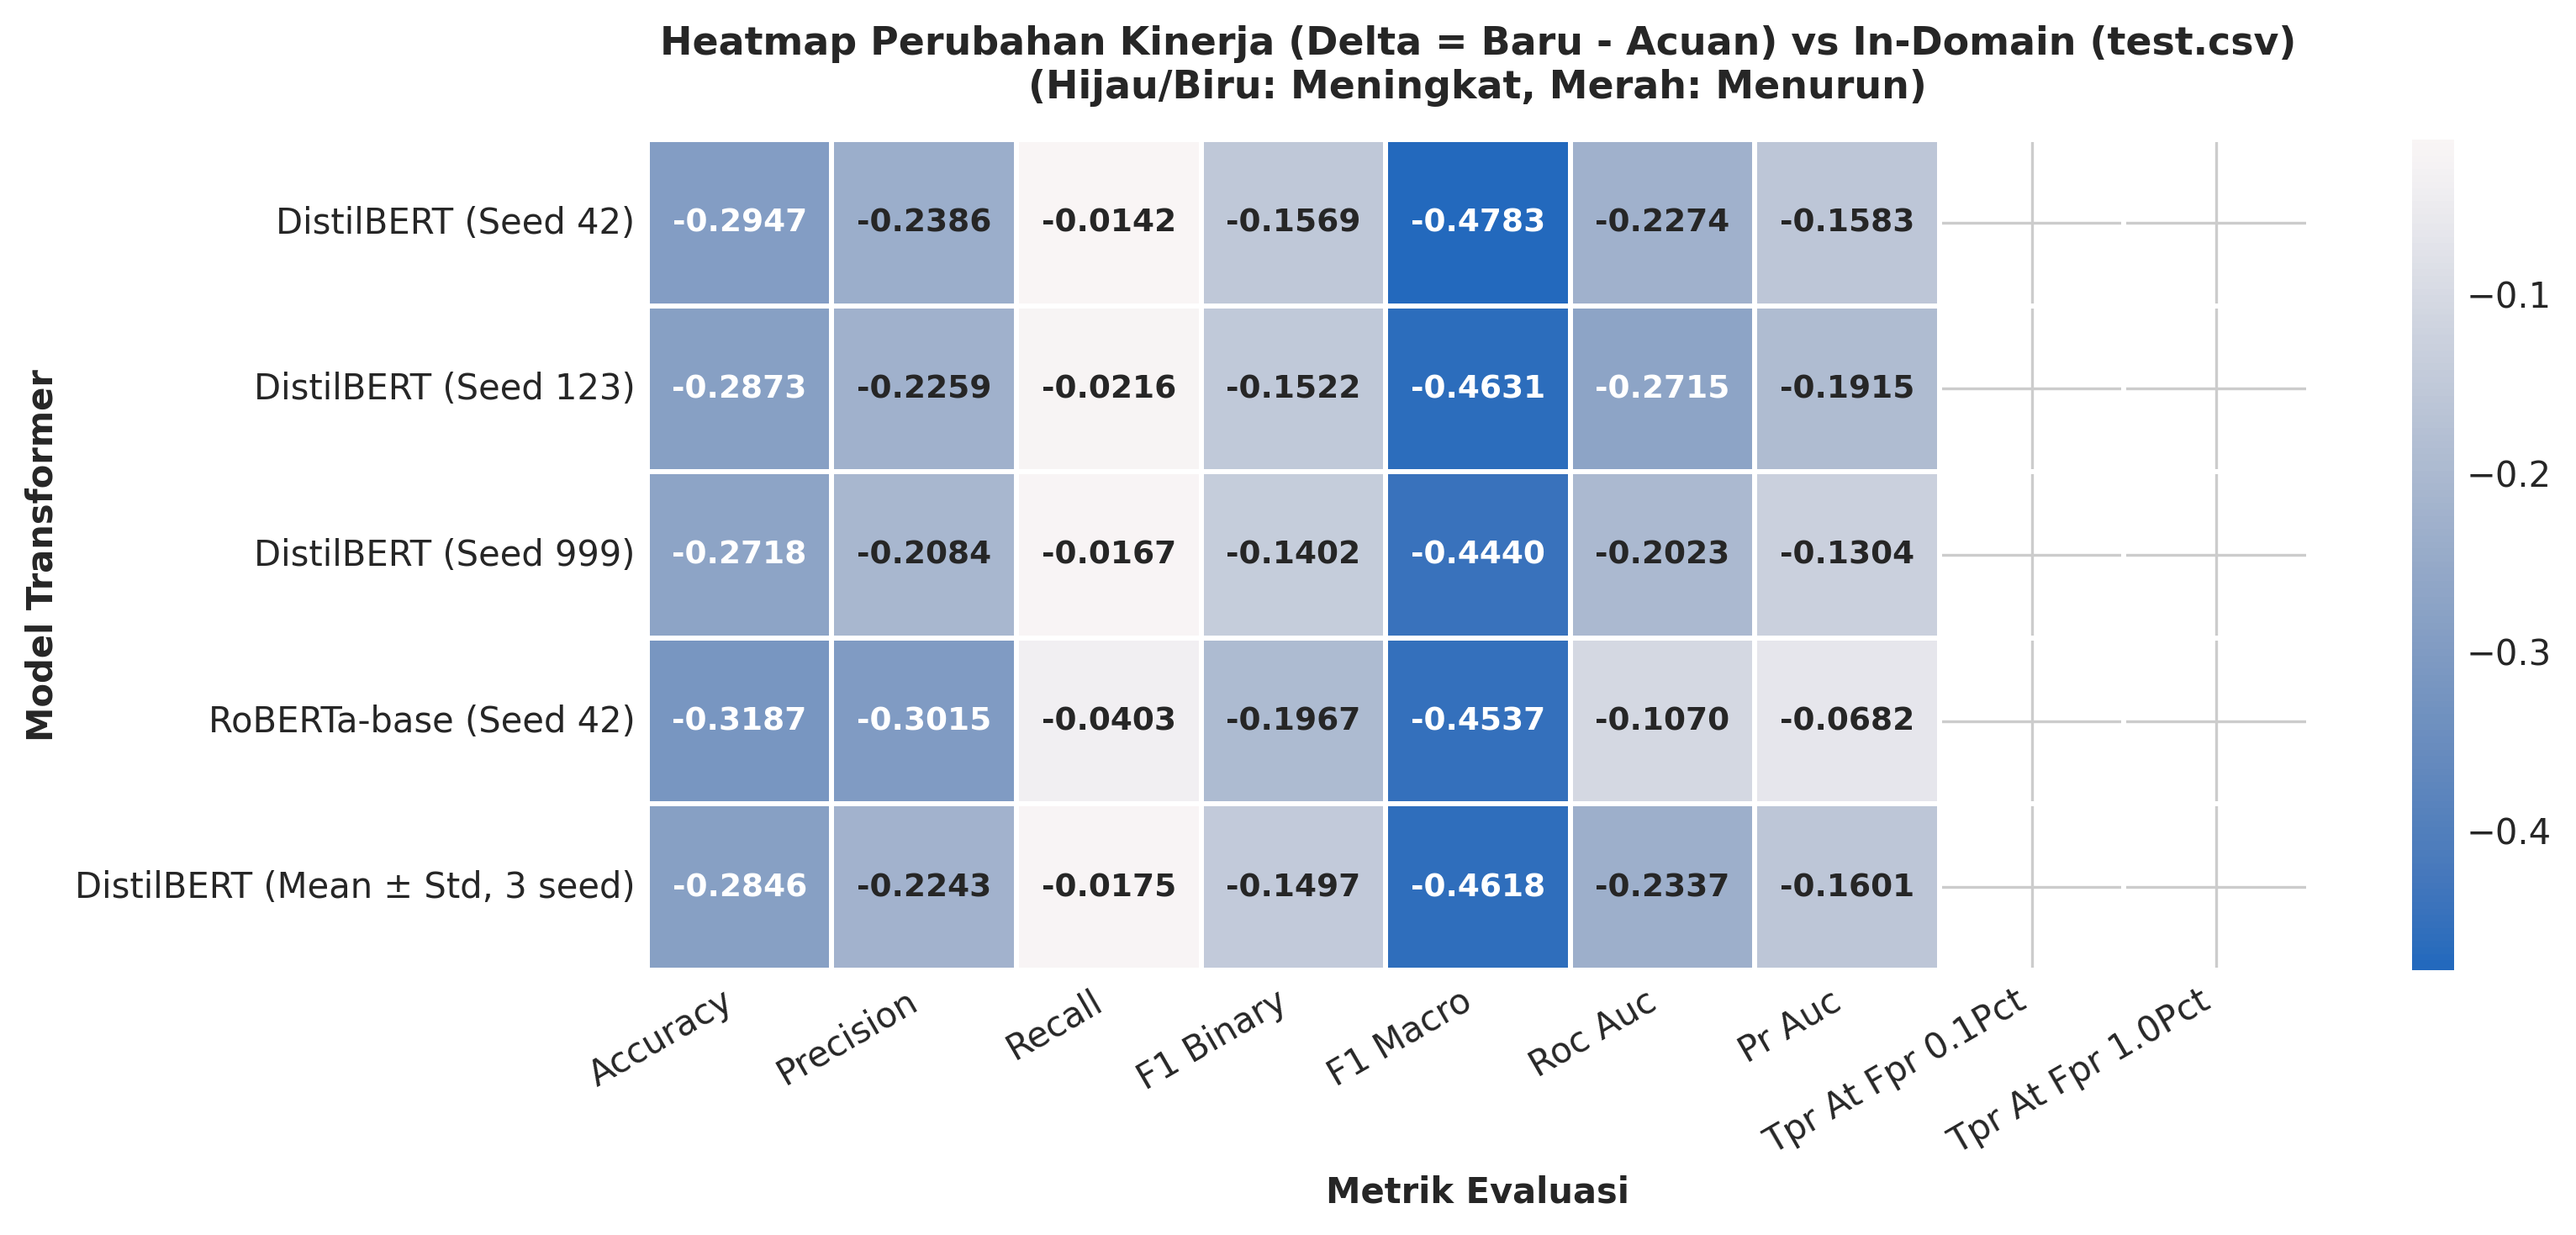

✅ Tersimpan: /content/drive/MyDrive/Skripsi/results/ext2_08_delta_heatmap_vs_indomain.png


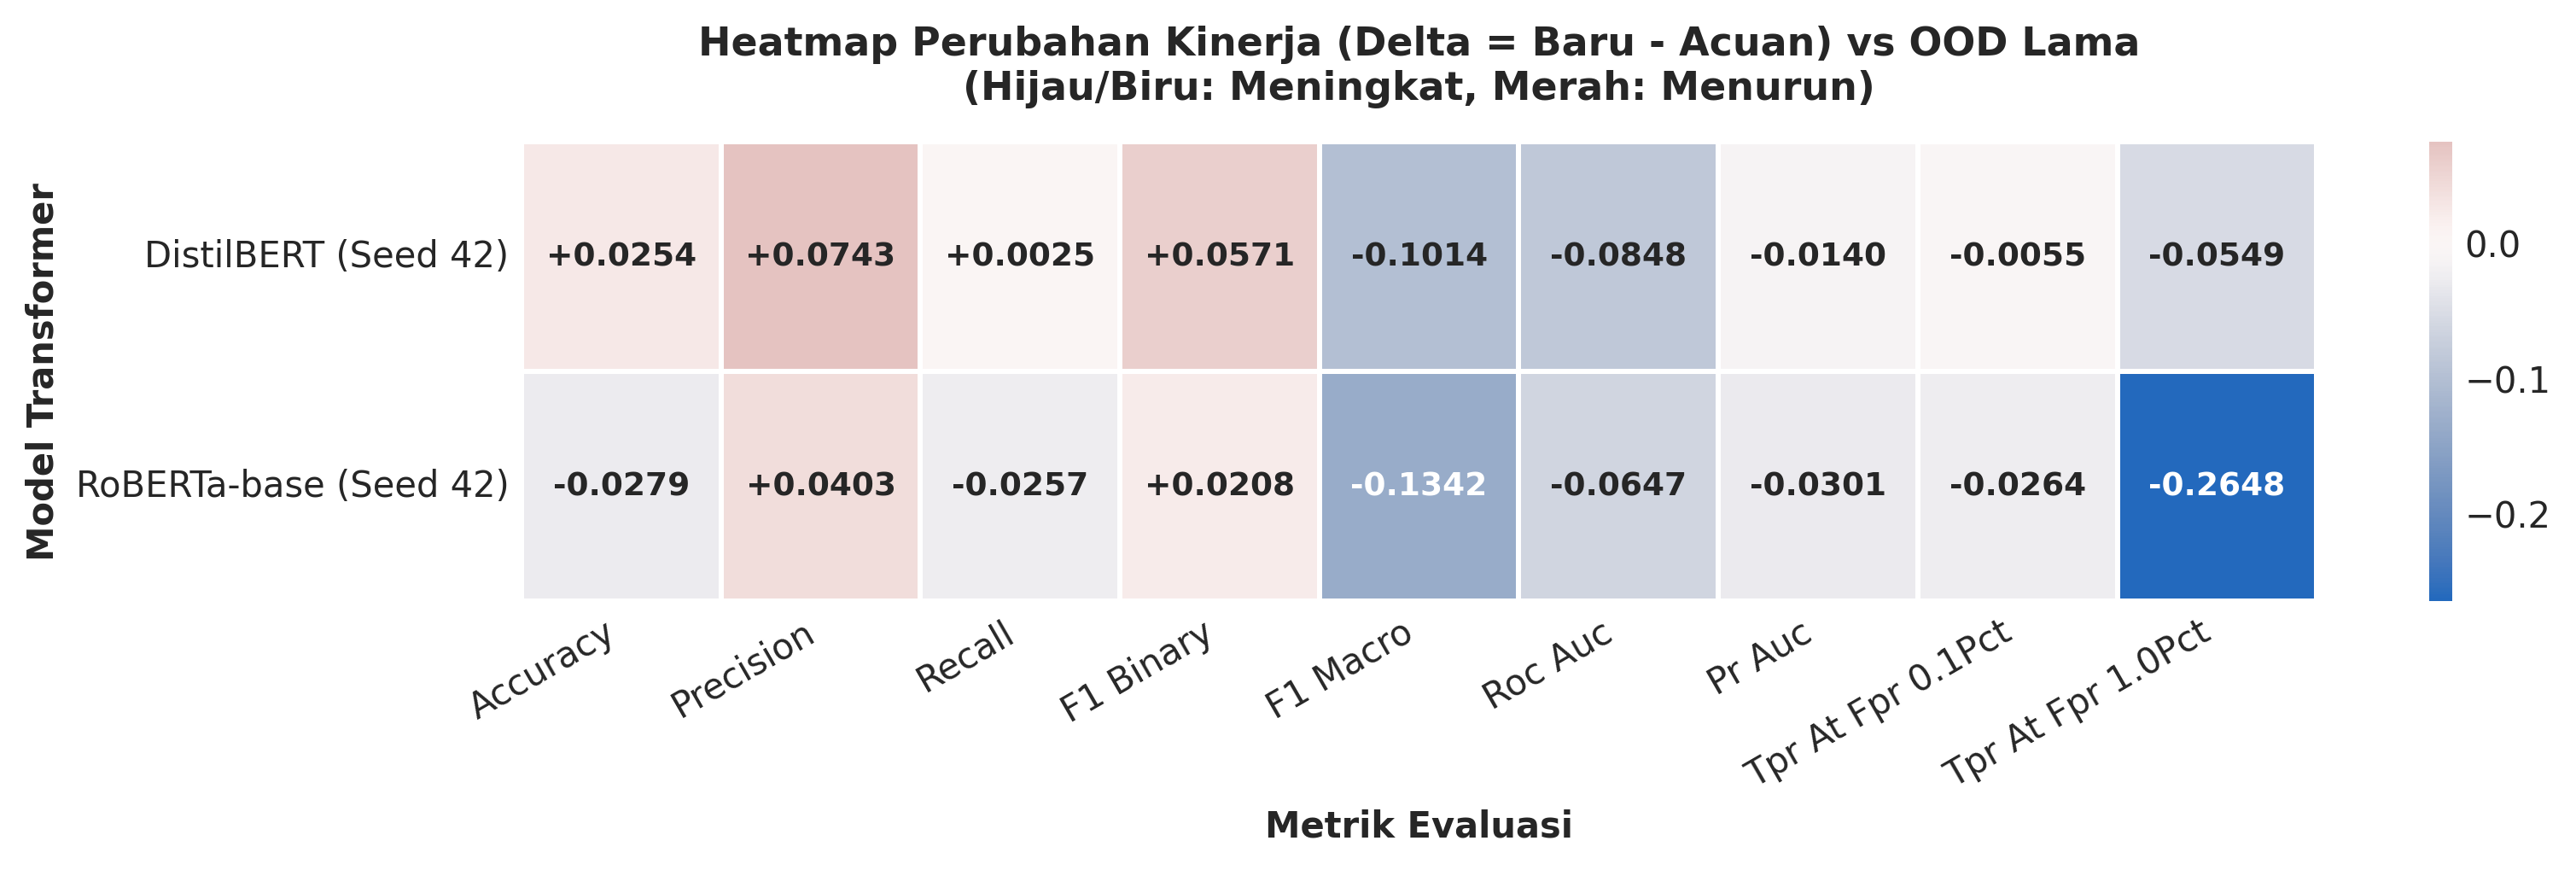

✅ Tersimpan: /content/drive/MyDrive/Skripsi/results/ext2_09_delta_heatmap_vs_ood_lama.png


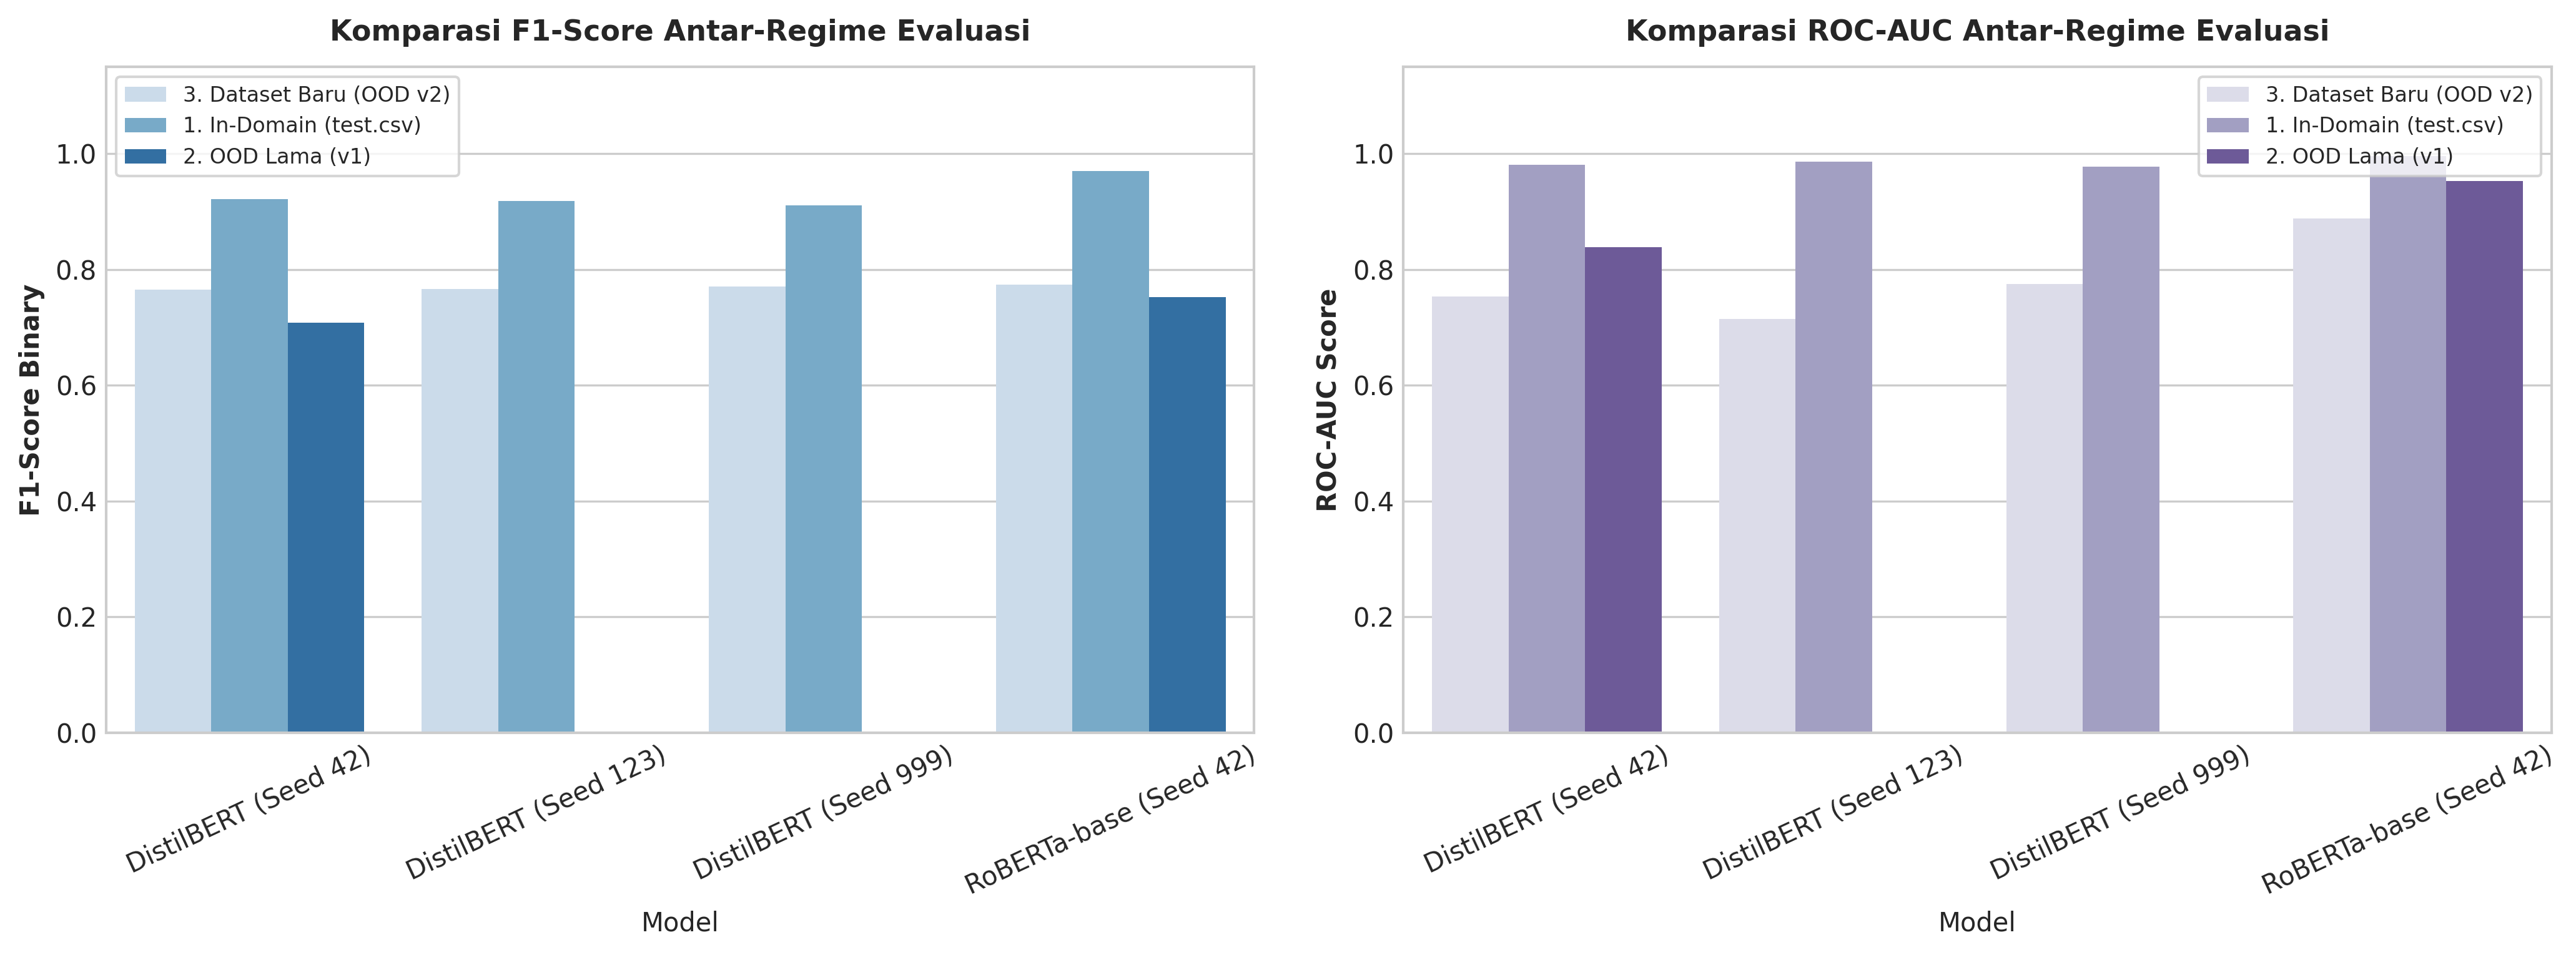

✅ Tersimpan: /content/drive/MyDrive/Skripsi/results/ext2_10_grouped_bars_indomain_vs_ood_vs_ext2.png


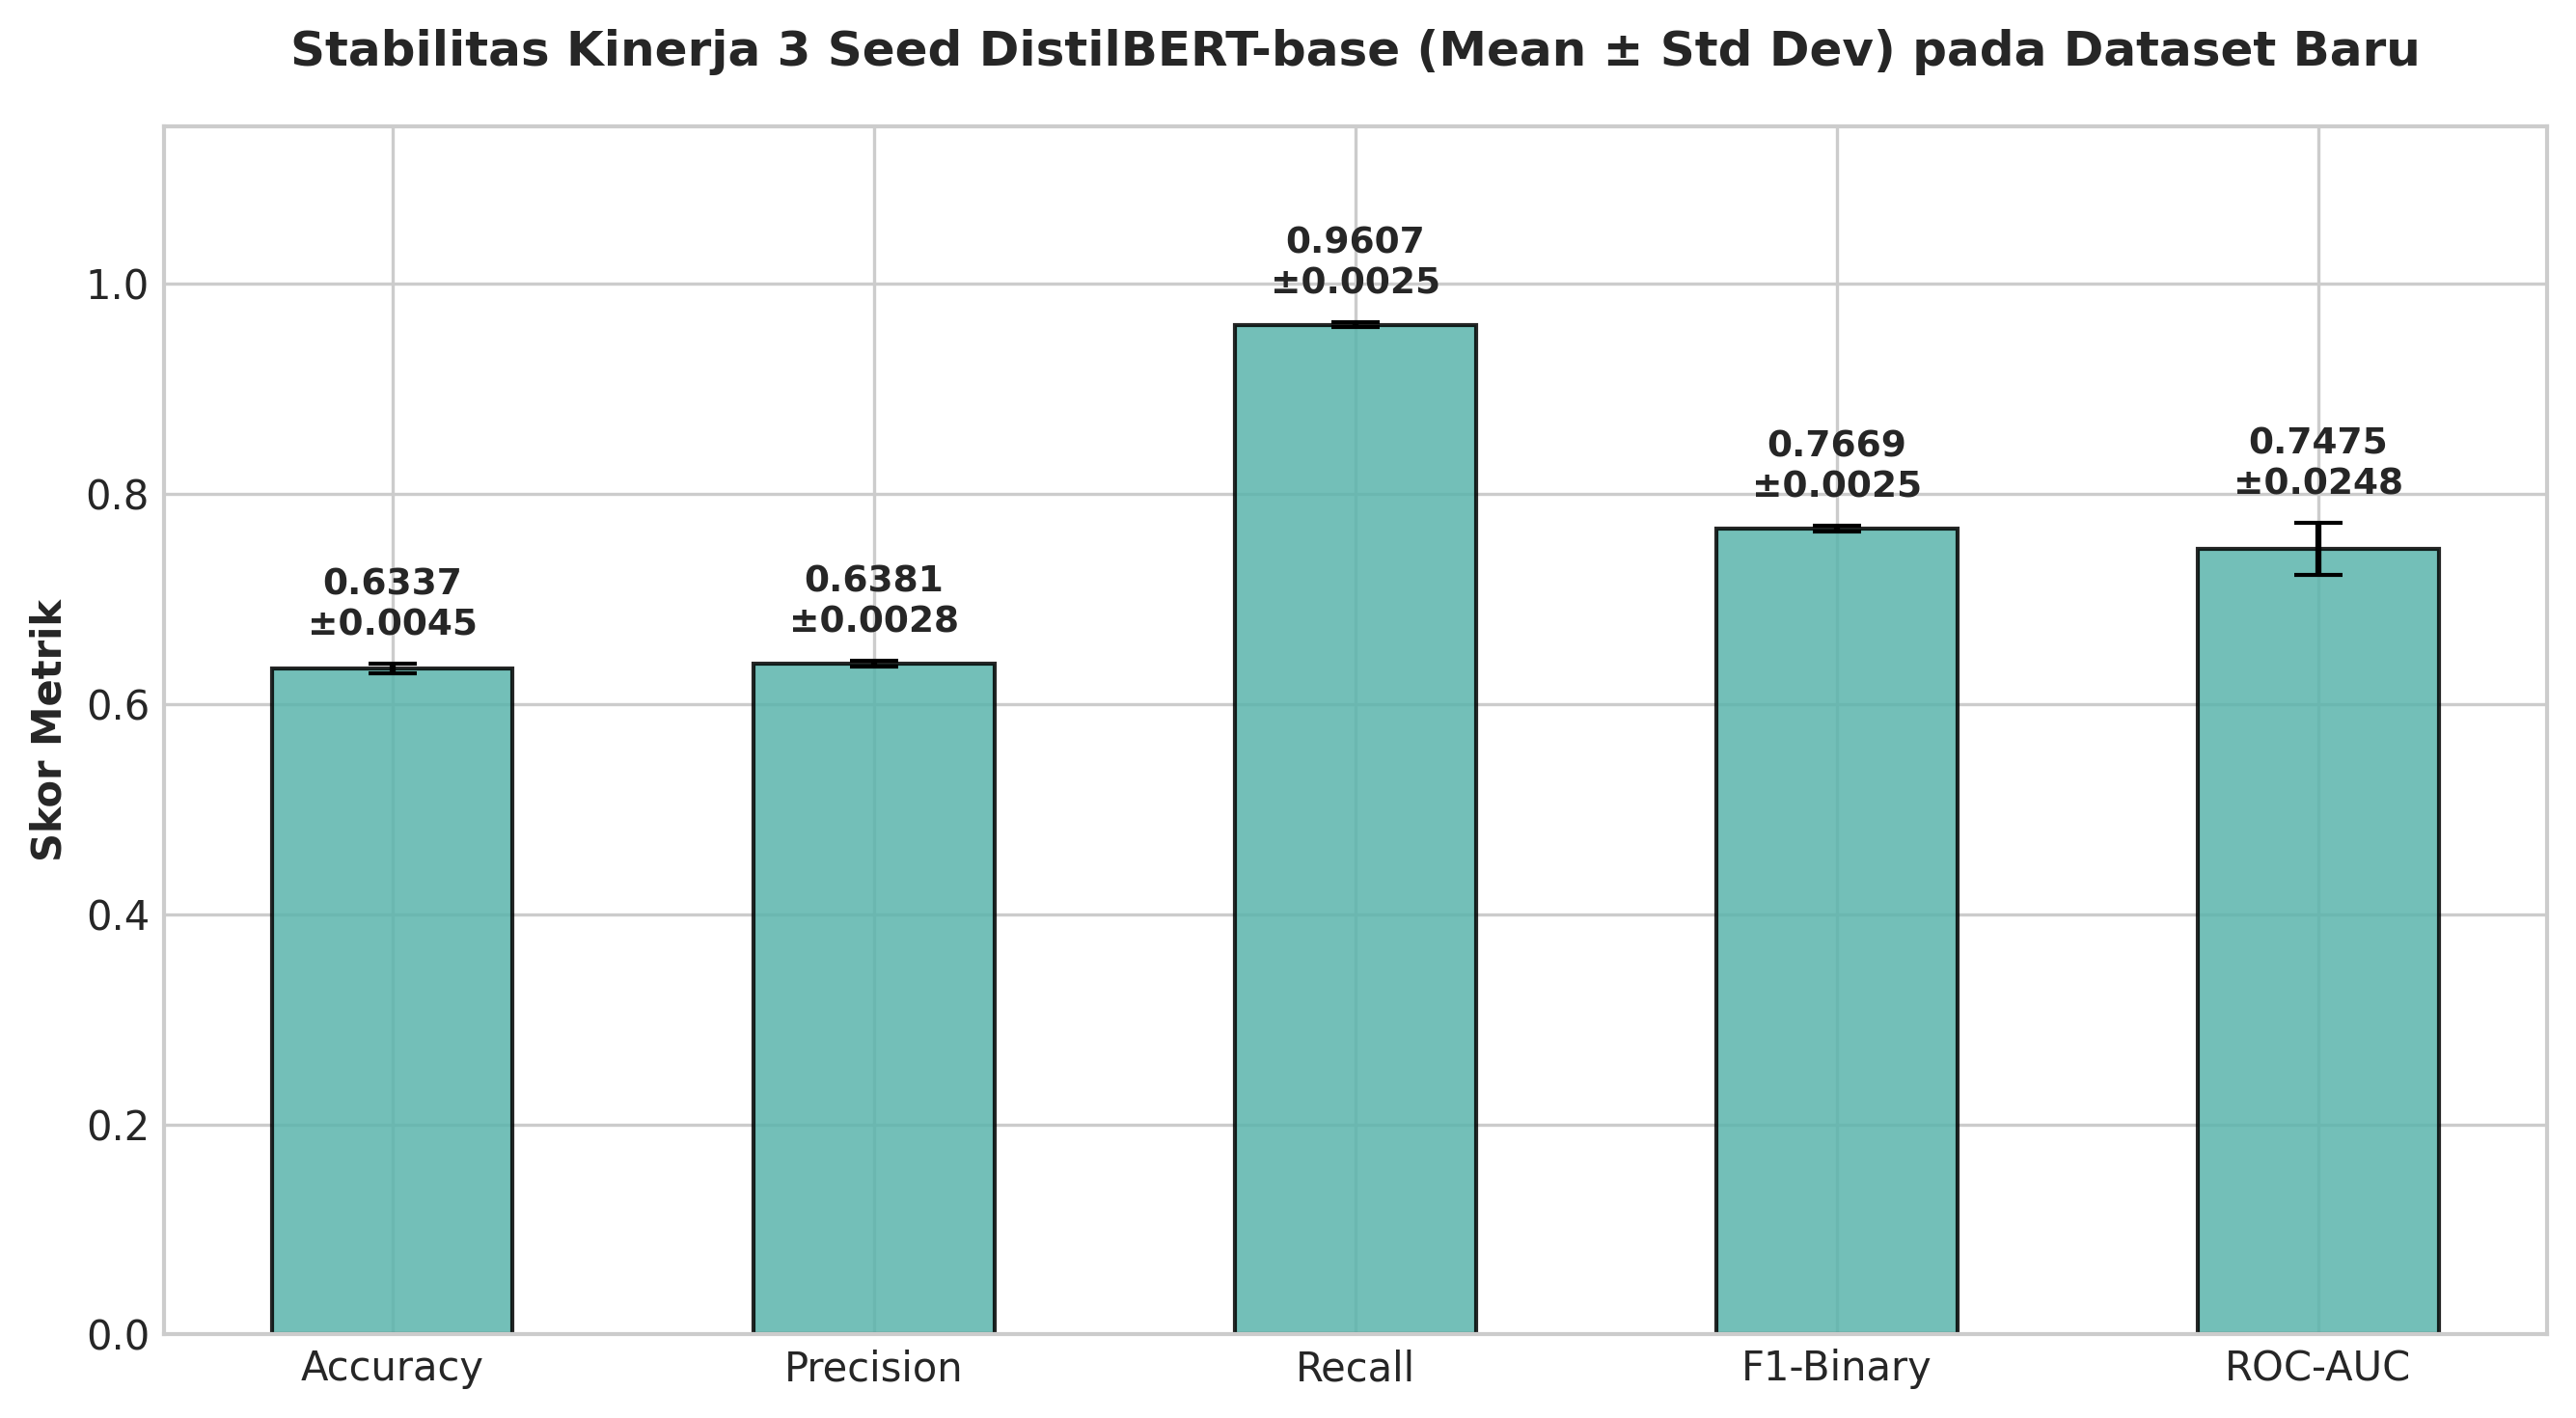

✅ Tersimpan: /content/drive/MyDrive/Skripsi/results/ext2_11_distilbert_seed_stability.png


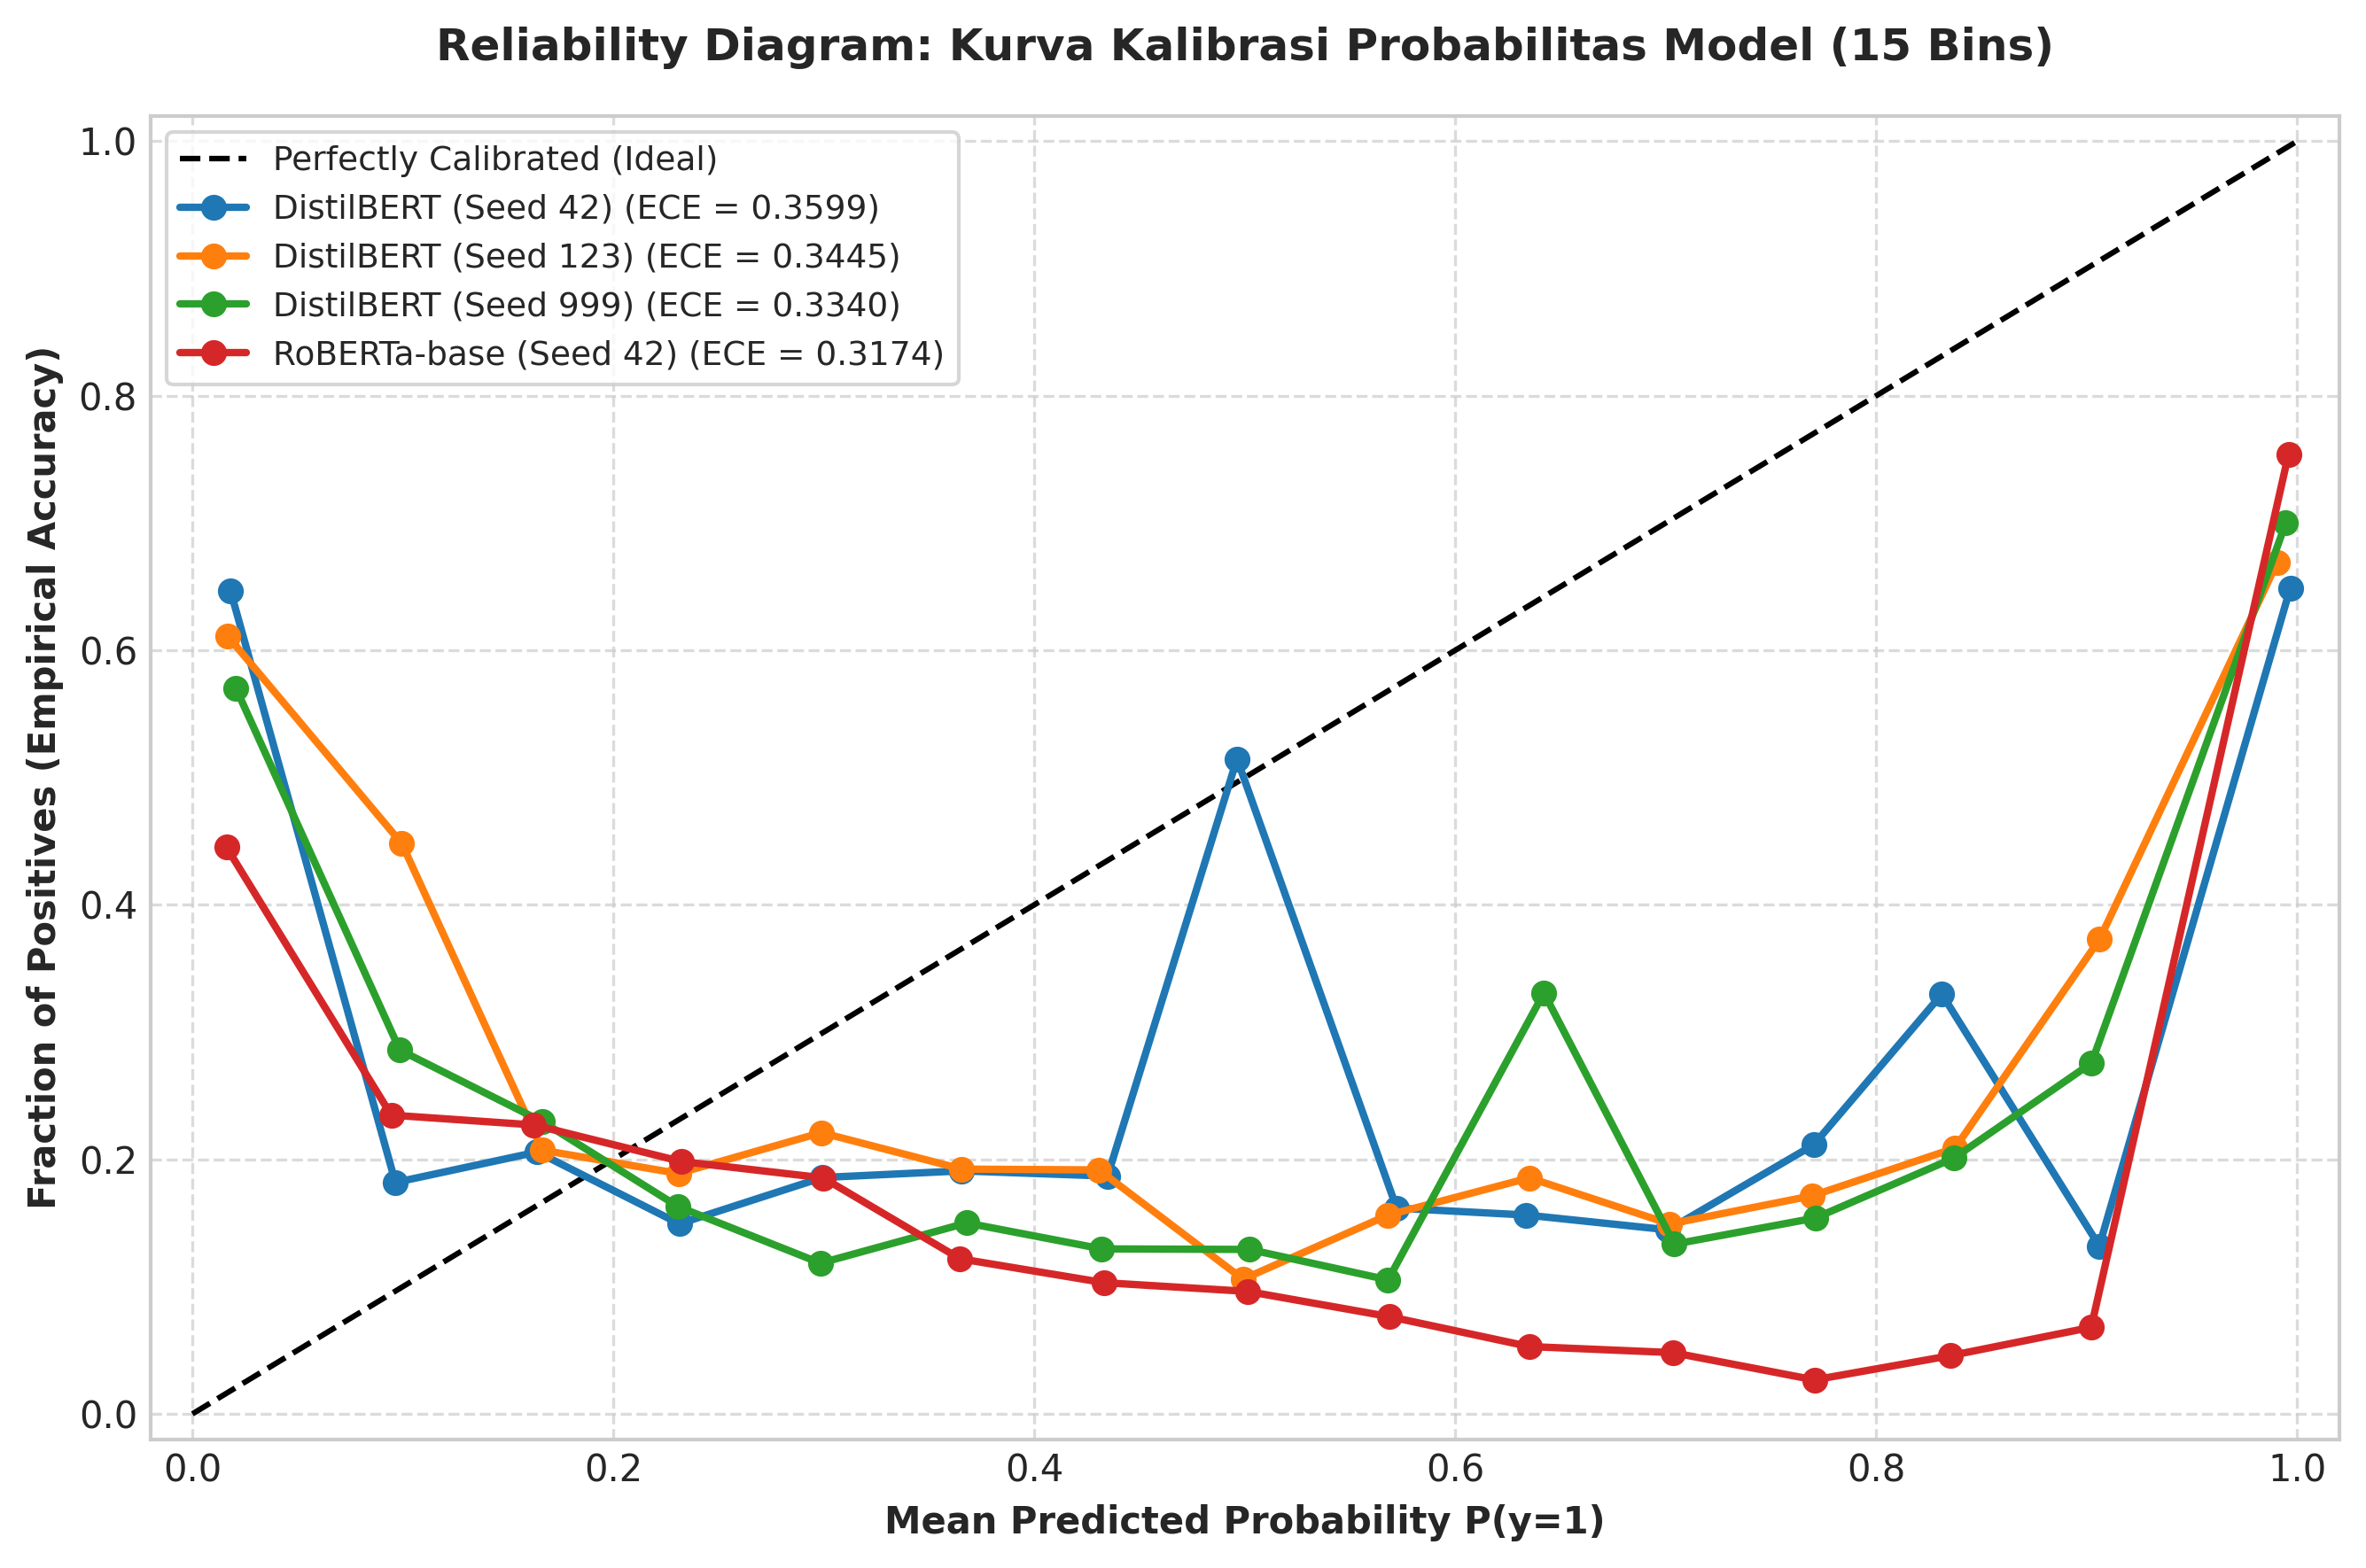

✅ Tersimpan: /content/drive/MyDrive/Skripsi/results/ext2_12_calibration_curves.png


In [14]:
print("[INFO] Membuat visualisasi analisis peningkatan dan kalibrasi (Plot 8 s.d. 12)...")

# ---------------------------------------------------------------------
# PLOT 8 & 9: Delta Heatmaps (vs In-Domain dan vs OOD Lama)
# ---------------------------------------------------------------------
def plot_delta_heatmap(df_delta, baseline_title, filename):
    if df_delta.empty:
        print(f"[INFO] Melewati pembuatan heatmap untuk {baseline_title} (data tidak tersedia).")
        return

    delta_sub = df_delta[['Model'] + [f'{k}_delta' for k in DELTA_METRICS if f'{k}_delta' in df_delta.columns]].copy()
    delta_sub.set_index('Model', inplace=True)
    delta_sub.columns = [c.replace('_delta', '').replace('_', ' ').title() for c in delta_sub.columns]

    plt.figure(figsize=(11, max(3.5, len(delta_sub) * 1.0)), dpi=300)
    sns.heatmap(delta_sub, annot=True, fmt="+.4f", cmap="vlag", center=0.0, cbar=True,
                linewidths=1.0, annot_kws={"fontsize": 9, "fontweight": "bold"})
    plt.title(f"Heatmap Perubahan Kinerja (Delta = Baru - Acuan) vs {baseline_title}\n(Hijau/Biru: Meningkat, Merah: Menurun)", fontsize=11, fontweight='bold', pad=12)
    plt.xlabel("Metrik Evaluasi", fontsize=10, fontweight='bold')
    plt.ylabel("Model Transformer", fontsize=10, fontweight='bold')
    plt.xticks(rotation=30, ha='right')

    plt.tight_layout()
    p_path = os.path.join(RESULTS_DIR, filename)
    plt.savefig(p_path, dpi=300, bbox_inches='tight')
    plt.show()
    print(f"✅ Tersimpan: {p_path}")

plot_delta_heatmap(df_delta_indomain, "In-Domain (test.csv)", "ext2_08_delta_heatmap_vs_indomain.png")
plot_delta_heatmap(df_delta_ood_lama, "OOD Lama", "ext2_09_delta_heatmap_vs_ood_lama.png")

# ---------------------------------------------------------------------
# PLOT 10: Grouped Bars: In-Domain vs OOD Lama vs Dataset Baru
# ---------------------------------------------------------------------
regime_data = []
for m_name in active_models:
    # Baru
    regime_data.append({'Model': m_name, 'Regime': '3. Dataset Baru (OOD v2)', 'F1-Score': all_model_results[m_name]['f1_binary'], 'ROC-AUC': all_model_results[m_name]['roc_auc']})

    # In-Domain
    if not df_delta_indomain.empty:
        sub_in = df_delta_indomain[df_delta_indomain['Model'] == m_name]
        if not sub_in.empty and 'f1_binary_acuan' in sub_in.columns:
            regime_data.append({'Model': m_name, 'Regime': '1. In-Domain (test.csv)', 'F1-Score': sub_in['f1_binary_acuan'].iloc[0], 'ROC-AUC': sub_in.get('roc_auc_acuan', pd.Series([np.nan])).iloc[0]})

    # OOD Lama
    if not df_delta_ood_lama.empty:
        sub_ood = df_delta_ood_lama[df_delta_ood_lama['Model'] == m_name]
        if not sub_ood.empty and 'f1_binary_acuan' in sub_ood.columns:
            regime_data.append({'Model': m_name, 'Regime': '2. OOD Lama (v1)', 'F1-Score': sub_ood['f1_binary_acuan'].iloc[0], 'ROC-AUC': sub_ood.get('roc_auc_acuan', pd.Series([np.nan])).iloc[0]})

df_regime = pd.DataFrame(regime_data)
if not df_regime.empty:
    fig, (ax_f1, ax_roc) = plt.subplots(1, 2, figsize=(14, 5.2), dpi=300)

    sns.barplot(data=df_regime, x='Model', y='F1-Score', hue='Regime', palette='Blues', ax=ax_f1)
    ax_f1.set_title("Komparasi F1-Score Antar-Regime Evaluasi", fontsize=11, fontweight='bold', pad=10)
    ax_f1.set_ylabel("F1-Score Binary", fontsize=10, fontweight='bold')
    ax_f1.tick_params(axis='x', rotation=25)
    ax_f1.set_ylim(0, 1.15)
    ax_f1.legend(frameon=True, fontsize=8)

    sns.barplot(data=df_regime, x='Model', y='ROC-AUC', hue='Regime', palette='Purples', ax=ax_roc)
    ax_roc.set_title("Komparasi ROC-AUC Antar-Regime Evaluasi", fontsize=11, fontweight='bold', pad=10)
    ax_roc.set_ylabel("ROC-AUC Score", fontsize=10, fontweight='bold')
    ax_roc.tick_params(axis='x', rotation=25)
    ax_roc.set_ylim(0, 1.15)
    ax_roc.legend(frameon=True, fontsize=8)

    plt.tight_layout()
    p10_path = os.path.join(RESULTS_DIR, "ext2_10_grouped_bars_indomain_vs_ood_vs_ext2.png")
    plt.savefig(p10_path, dpi=300, bbox_inches='tight')
    plt.show()
    print(f"✅ Tersimpan: {p10_path}")

# ---------------------------------------------------------------------
# PLOT 11: DistilBERT Seed Stability (Error Bars Mean ± Std)
# ---------------------------------------------------------------------
if len(distilbert_seeds_metrics) >= 2:
    metrics_seed_plot = ['accuracy', 'precision', 'recall', 'f1_binary', 'roc_auc']
    seed_means = [np.mean([m[k] for m in distilbert_seeds_metrics]) for k in metrics_seed_plot]
    seed_stds = [np.std([m[k] for m in distilbert_seeds_metrics]) for k in metrics_seed_plot]
    metric_plot_labels = ['Accuracy', 'Precision', 'Recall', 'F1-Binary', 'ROC-AUC']

    plt.figure(figsize=(9, 5), dpi=300)
    bars = plt.bar(metric_plot_labels, seed_means, yerr=seed_stds, capsize=6, color='#5ab4ac', edgecolor='black', alpha=0.85, width=0.5)

    plt.title("Stabilitas Kinerja 3 Seed DistilBERT-base (Mean ± Std Dev) pada Dataset Baru", fontsize=12, fontweight='bold', pad=15)
    plt.ylabel("Skor Metrik", fontsize=10, fontweight='bold')
    plt.ylim(0, 1.15)

    for i, (m_val, s_val) in enumerate(zip(seed_means, seed_stds)):
        plt.text(i, m_val + s_val + 0.02, f"{m_val:.4f}\n±{s_val:.4f}", ha='center', va='bottom', fontsize=9, fontweight='bold')

    plt.tight_layout()
    p11_path = os.path.join(RESULTS_DIR, "ext2_11_distilbert_seed_stability.png")
    plt.savefig(p11_path, dpi=300, bbox_inches='tight')
    plt.show()
    print(f"✅ Tersimpan: {p11_path}")

# ---------------------------------------------------------------------
# PLOT 12: Reliability Diagrams (Calibration Curves)
# ---------------------------------------------------------------------
plt.figure(figsize=(9, 6), dpi=300)
plt.plot([0, 1], [0, 1], "k--", label="Perfectly Calibrated (Ideal)")

for m_name in active_models:
    y_t = all_model_results[m_name]['y_true']
    y_p = all_model_results[m_name]['y_prob']
    prob_true, prob_pred = calibration_curve(y_t, y_p, n_bins=15, strategy='uniform')
    ece_val = all_model_results[m_name]['ece']
    plt.plot(prob_pred, prob_true, marker='o', lw=2, label=f"{m_name} (ECE = {ece_val:.4f})")

plt.title("Reliability Diagram: Kurva Kalibrasi Probabilitas Model (15 Bins)", fontsize=12, fontweight='bold', pad=15)
plt.xlabel("Mean Predicted Probability P(y=1)", fontsize=10, fontweight='bold')
plt.ylabel("Fraction of Positives (Empirical Accuracy)", fontsize=10, fontweight='bold')
plt.xlim(-0.02, 1.02)
plt.ylim(-0.02, 1.02)
plt.legend(frameon=True, loc='upper left', fontsize=9)
plt.grid(True, linestyle='--', alpha=0.7)

plt.tight_layout()
p12_path = os.path.join(RESULTS_DIR, "ext2_12_calibration_curves.png")
plt.savefig(p12_path, dpi=300, bbox_inches='tight')
plt.show()
print(f"✅ Tersimpan: {p12_path}")

## 12. Error Analysis: False Positives, False Negatives & Error Konsensus
Menganalisis karakteristik kesalahan klasifikasi model secara mendalam:
1. **Top-5 False Positives (FP)**: URL Benign dengan probabilitas phishing tertinggi (alarm palsu paling parah).
2. **Top-5 False Negatives (FN)**: URL Phishing dengan probabilitas phishing terendah (lolos deteksi).
3. **Error Konsensus**: URL yang salah diprediksi oleh SELURUH model yang diuji.
4. **Error Spesifik Model**: URL yang hanya salah pada SATU model saja.
Serta mengekspor data prediksi lengkap (`ext2_predictions.csv`) dan sampel analisis kesalahan (`ext2_error_analysis_samples.csv`).

In [15]:
print("======================================================================")
print("🔍 ERROR ANALYSIS: FALSE POSITIVES (FP), FALSE NEGATIVES (FN) & KONSENSUS")
print("======================================================================")

analysis_records = []
urls_raw = df_clean['url'].values
y_true_all = df_clean['label'].values

# 1. Ekstraksi 5 FP & 5 FN Teratas per Model
for m_name in active_models:
    y_pred = all_model_results[m_name]['y_pred']
    y_prob = all_model_results[m_name]['y_prob']

    # FP: True = 0, Pred = 1 (urutkan probabilitas phishing tertinggi)
    fp_idx = np.where((y_true_all == 0) & (y_pred == 1))[0]
    sorted_fp = fp_idx[np.argsort(-y_prob[fp_idx])][:5]

    # FN: True = 1, Pred = 0 (urutkan probabilitas phishing terendah)
    fn_idx = np.where((y_true_all == 1) & (y_pred == 0))[0]
    sorted_fn = fn_idx[np.argsort(y_prob[fn_idx])][:5]

    print(f"\n--- Model: {m_name} ---")
    print("📌 5 Sampel False Positive Teratas (URL Aman terdeteksi Phishing):")
    for i, idx in enumerate(sorted_fp, 1):
        u_str = urls_raw[idx]
        prob = y_prob[idx]
        print(f"   [{i}] Prob Phishing: {prob:.4f} | URL: {u_str[:90]}")
        analysis_records.append({'Model': m_name, 'Tipe_Error': 'False Positive', 'Prob_Phishing': prob, 'URL': u_str})

    print("\n📌 5 Sampel False Negative Teratas (URL Phishing lolos deteksi):")
    for i, idx in enumerate(sorted_fn, 1):
        u_str = urls_raw[idx]
        prob = y_prob[idx]
        print(f"   [{i}] Prob Phishing: {prob:.4f} | URL: {u_str[:90]}")
        analysis_records.append({'Model': m_name, 'Tipe_Error': 'False Negative', 'Prob_Phishing': prob, 'URL': u_str})

# 2. Analisis Error Konsensus (Salah di SEMUA Model)
if len(active_models) >= 2:
    print("\n======================================================================")
    print("🚨 URL DENGAN KESALAHAN KONSENSUS (SALAH DI SEMUA MODEL)")
    print("======================================================================")

    # Matriks Prediksi (N_sampel x N_model)
    preds_matrix = np.column_stack([all_model_results[m]['y_pred'] for m in active_models])

    # Konsensus FP: Seluruh model memprediksi 1 saat True = 0
    consensus_fp_mask = (y_true_all == 0) & np.all(preds_matrix == 1, axis=1)
    consensus_fp_idx = np.where(consensus_fp_mask)[0]
    print(f"Total URL Konsensus False Positive: {len(consensus_fp_idx):,} sampel")
    for idx in consensus_fp_idx[:5]:
        u_str = urls_raw[idx]
        avg_prob = np.mean([all_model_results[m]['y_prob'][idx] for m in active_models])
        print(f"   [FP Konsensus] Rata-rata Prob: {avg_prob:.4f} | URL: {u_str[:90]}")
        analysis_records.append({'Model': 'KONSENSUS_SEMUA', 'Tipe_Error': 'Consensus False Positive', 'Prob_Phishing': avg_prob, 'URL': u_str})

    # Konsensus FN: Seluruh model memprediksi 0 saat True = 1
    consensus_fn_mask = (y_true_all == 1) & np.all(preds_matrix == 0, axis=1)
    consensus_fn_idx = np.where(consensus_fn_mask)[0]
    print(f"\nTotal URL Konsensus False Negative: {len(consensus_fn_idx):,} sampel")
    for idx in consensus_fn_idx[:5]:
        u_str = urls_raw[idx]
        avg_prob = np.mean([all_model_results[m]['y_prob'][idx] for m in active_models])
        print(f"   [FN Konsensus] Rata-rata Prob: {avg_prob:.4f} | URL: {u_str[:90]}")
        analysis_records.append({'Model': 'KONSENSUS_SEMUA', 'Tipe_Error': 'Consensus False Negative', 'Prob_Phishing': avg_prob, 'URL': u_str})

    # 3. Analisis Error Spesifik Model (Salah HANYA di SATU Model)
    print("\n======================================================================")
    print("🎯 URL DENGAN KESALAHAN SPESIFIK (HANYA SALAH DI SATU MODEL)")
    print("======================================================================")
    for i, m_name in enumerate(active_models):
        curr_pred = preds_matrix[:, i]
        other_preds = np.delete(preds_matrix, i, axis=1)

        # Salah di model ini, tapi BENAR di semua model lainnya
        unique_error_mask = (curr_pred != y_true_all) & np.all(other_preds == y_true_all[:, None], axis=1)
        n_unique_err = unique_error_mask.sum()
        print(f" - Model {m_name:<25}: {n_unique_err:,} kesalahan unik")

# Ekspor File Hasil Analisis Error
df_err_export = pd.DataFrame(analysis_records)
err_csv_path = os.path.join(RESULTS_DIR, "ext2_error_analysis_samples.csv")
df_err_export.to_csv(err_csv_path, index=False)
print(f"\n✅ Tabel Sampel Error Analysis tersimpan ke: {err_csv_path}")

# Ekspor File Prediksi Lengkap Seluruh URL
df_predictions = pd.DataFrame({
    'url': df_clean['url'],
    'url_norm': df_clean['url_norm'],
    'domain_group': df_clean['domain_group'],
    'label': df_clean['label']
})
for m_name in active_models:
    clean_prefix = re.sub(r'[^a-zA-Z0-9_]', '_', m_name).lower()
    df_predictions[f'{clean_prefix}_pred'] = all_model_results[m_name]['y_pred']
    df_predictions[f'{clean_prefix}_prob'] = all_model_results[m_name]['y_prob']

pred_csv_path = os.path.join(RESULTS_DIR, "ext2_predictions.csv")
df_predictions.to_csv(pred_csv_path, index=False)
print(f"✅ Data Prediksi Lengkap Tersimpan ke: {pred_csv_path}")

🔍 ERROR ANALYSIS: FALSE POSITIVES (FP), FALSE NEGATIVES (FN) & KONSENSUS

--- Model: DistilBERT (Seed 42) ---
📌 5 Sampel False Positive Teratas (URL Aman terdeteksi Phishing):
   [1] Prob Phishing: 1.0000 | URL: https://www.getmedonline.com
   [2] Prob Phishing: 1.0000 | URL: https://www.laptopspares.pk
   [3] Prob Phishing: 1.0000 | URL: https://www.splitt.nl
   [4] Prob Phishing: 1.0000 | URL: https://www.helencooperpaintings.com
   [5] Prob Phishing: 1.0000 | URL: https://www.darkenergysurvey.org

📌 5 Sampel False Negative Teratas (URL Phishing lolos deteksi):
   [1] Prob Phishing: 0.0002 | URL: https://api.pastecode.io/anon/raw-snippet/c32qiqwg?raw=inline&api=true&ticket=912a57c7-f20
   [2] Prob Phishing: 0.0002 | URL: https://api.pastecode.io/anon/raw-snippet/vsyezv40?raw=inline&api=true&ticket=912a57c7-f20
   [3] Prob Phishing: 0.0002 | URL: http://ttykok.320.io/software/%E8%87%AA%E5%8A%A8%E5%8C%96%E6%B5%8B%E8%AF%95/%E8%87%AA%E5%8
   [4] Prob Phishing: 0.0002 | URL: https://api.p

## 13. Pencatatan Permanen ke Logbook Skripsi (`SKRIPSI_LOG.md`) & Ekspor Hasil CSV
Menambahkan ringkasan tabel hasil evaluasi dataset eksternal baru dan delta performa secara permanen ke file logbook riset (`SKRIPSI_LOG.md`) serta mengekspor tabel metrik lengkap ke `ext2_evaluation_results.csv`.

In [16]:
print(f"[INFO] Menyimpan rekapitulasi evaluasi ke CSV & Logbook Skripsi...")

# 1. Ekspor Tabel Metrik Lengkap ke CSV
final_results_csv = os.path.join(RESULTS_DIR, "ext2_evaluation_results.csv")
df_ext2_summary.to_csv(final_results_csv, index=False)
print(f"✅ Tabel ringkasan evaluasi tersimpan ke: {final_results_csv}")

# 2. Format Tabel Markdown untuk Logbook Skripsi
current_time_str = time.strftime("%Y-%m-%d %H:%M:%S", time.localtime())

# Ambil header model yang aktif
active_header_cols = [m for m in all_model_results.keys()]
header_line = "| Metrik Evaluasi | " + " | ".join(active_header_cols) + " | Keterangan / Analisis Industri |"
sep_line = "| :--- | " + " | ".join([":---:" for _ in active_header_cols]) + " | :--- |"

log_metric_keys = [
    ("Accuracy", 'accuracy', lambda v: f"{v*100:.2f}%", "Ketepatan klasifikasi total"),
    ("Precision", 'precision', lambda v: f"{v:.4f}", "Rasio kebenaran alarm phishing"),
    ("Recall / Sensitivity", 'recall', lambda v: f"{v:.4f}", "Cakupan penangkapan URL phishing"),
    ("F1-Score (Binary)", 'f1_binary', lambda v: f"{v:.4f}", "Rata-rata harmonik Precision & Recall"),
    ("F1-Score (Macro)", 'f1_macro', lambda v: f"{v:.4f}", "Keseimbangan performa kedua kelas"),
    ("ROC-AUC", 'roc_auc', lambda v: f"{v:.4f}", "Kemampuan pemisahan probabilitas"),
    ("PR-AUC", 'pr_auc', lambda v: f"{v:.4f}", "Luas kurva Precision-Recall"),
    ("TPR @ FPR ≤ 0.1%", 'tpr_at_fpr_0.1pct', lambda v: f"{v*100:.2f}%", "Deteksi saat False Alarm ≤ 1/1000"),
    ("TPR @ FPR ≤ 1.0%", 'tpr_at_fpr_1.0pct', lambda v: f"{v*100:.2f}%", "Deteksi saat False Alarm ≤ 1/100"),
    ("Expected Calib Error (ECE)", 'ece', lambda v: f"{v:.4f}", "Kalibrasi probabilitas model"),
    ("Brier Score", 'brier_score', lambda v: f"{v:.4f}", "Mean squared calibration error"),
    ("Inference Latency", 'latency_ms', lambda v: f"{v:.3f} ms", "Waktu inferensi per URL"),
    ("Throughput", 'throughput_sps', lambda v: f"{v:,.0f} URLs/s", "Throughput batch GPU T4"),
    ("Peak VRAM", 'peak_vram_gb', lambda v: f"{v:.3f} GB", "Konsumsi memori VRAM GPU"),
    ("Total Parameters", 'total_params', lambda v: f"{v:,}", "Ukuran arsitektur model")
]

metric_rows = []
for label_desc, key_m, fmt_fn, note in log_metric_keys:
    row_vals = []
    for m in active_header_cols:
        val = all_model_results[m].get(key_m, np.nan)
        row_vals.append(fmt_fn(val) if pd.notna(val) and not np.isnan(val) else "N/A")
    metric_rows.append(f"| **{label_desc}** | " + " | ".join(row_vals) + f" | {note} |")

# Ringkasan Delta vs In-Domain untuk Logbook
delta_rows = []
if not df_delta_indomain.empty:
    for m in active_header_cols:
        sub_d = df_delta_indomain[df_delta_indomain['Model'] == m]
        if not sub_d.empty and 'f1_binary_delta' in sub_d.columns:
            d_f1 = sub_d['f1_binary_delta'].iloc[0]
            d_roc = sub_d.get('roc_auc_delta', pd.Series([np.nan])).iloc[0]
            delta_rows.append(f" - **{m}**: $\\Delta F1 = {d_f1:+.4f}$, $\\Delta ROC = {d_roc:+.4f}$ vs In-Domain.")

# [DIUBAH] Menambahkan catatan validitas riset (threat domain shift) ke logbook skripsi
validity_note = (
    "> **Catatan Validitas Riset**: Model dilatih khusus untuk deteksi phishing, sedangkan kelas positif pada dataset "
    "ini didominasi oleh URL distribusi malware (misalnya botnet Mozi, IP:port, eksekusi file biner/script .sh/.exe). "
    "Oleh karena itu, penurunan performa pada pengujian ini dapat mengindikasikan adanya pergeseran jenis ancaman "
    "(threat type shift), bukan semata-mata menandakan kualitas generalisasi model yang buruk."
)

markdown_log_entry = f'''

---
### 🛡️ Catatan Evaluasi Dataset Eksternal Baru (Cross-Dataset OOD v2) ({current_time_str})
**File Dataset Uji Baru**: `{EXTERNAL_RAW_CSV}`
**File Bersih Teruji**: `{OUTPUT_CLEAN_CSV}` ({len(df_clean):,} sampel URL biner unik, Unseen Domain: {DROP_DOMAIN_OVERLAP}).

{validity_note}

{header_line}
{sep_line}
''' + "\n".join(metric_rows) + f'''

**Ringkasan Perubahan Kinerja (Delta):**
''' + "\n".join(delta_rows) + f'''

*File visualisasi publikasi 300 DPI tersimpan di `{RESULTS_DIR}/ext2_*.png`.*
'''

try:
    with open(LOG_FILE, "a", encoding="utf-8") as f:
        f.write(markdown_log_entry)
    print(f"✅ [SUKSES] Berhasil mencatat entri evaluasi baru ke: {LOG_FILE}")
except Exception as e:
    print(f"⚠️ Gagal menulis ke logbook: {e}")


[INFO] Menyimpan rekapitulasi evaluasi ke CSV & Logbook Skripsi...
✅ Tabel ringkasan evaluasi tersimpan ke: /content/drive/MyDrive/Skripsi/results/ext2_evaluation_results.csv
✅ [SUKSES] Berhasil mencatat entri evaluasi baru ke: /content/drive/MyDrive/Skripsi/SKRIPSI_LOG.md


## 14. Ringkasan Eksekutif & Simpulan Riset Otomatis
Rangkuman naratif otomatis berbahasa Indonesia yang menjawab tujuan utama penelitian:
1. Model terbaik dan terburuk pada dataset eksternal baru.
2. Analisis apakah terjadi peningkatan, penurunan, atau stabilitas dibanding acuan in-domain dan OOD lama.
3. Evaluasi trade-off kinerja vs efisiensi komputasi antara RoBERTa-base dan DistilBERT-base.
4. Catatan validitas riset: pergeseran jenis ancaman (phishing vs malware).
5. Rekomendasi praktis untuk implementasi sistem deteksi phishing di dunia nyata.


In [17]:
print("======================================================================")
print("🎯 RINGKASAN EKSEKUTIF & SIMPULAN AKHIR RISET SKRIPSI")
print("======================================================================")

# 1. Penentuan Model Terbaik & Terburuk
models_ranked = sorted([m for m in active_models if "Mean" not in m],
                       key=lambda x: all_model_results[x]['f1_binary'], reverse=True)

if not models_ranked:
    print("\n⚠️ [PERINGATAN] Tidak ada model yang berhasil dimuat atau dievaluasi.")
    print("   Pastikan direktori checkpoint model telah tersedia di direktori MODELS_DIR.")
else:
    best_model = models_ranked[0]
    worst_model = models_ranked[-1]

    print(f"\n1. PERINGKAT MODEL PADA DATASET EKSTERNAL BARU:")
    print(f"   🏆 Model Terbaik  : {best_model} (F1-Binary: {all_model_results[best_model]['f1_binary']:.4f}, ROC-AUC: {all_model_results[best_model]['roc_auc']:.4f})")
    print(f"   📉 Model Terendah : {worst_model} (F1-Binary: {all_model_results[worst_model]['f1_binary']:.4f}, ROC-AUC: {all_model_results[worst_model]['roc_auc']:.4f})")

    # 2. Analisis Peningkatan vs Penurunan
    print(f"\n2. TREN PERFORMA TERHADAP ACUAN HISTORIS:")
    for m in models_ranked:
        sub_in = df_delta_indomain[df_delta_indomain['Model'] == m] if not df_delta_indomain.empty else pd.DataFrame()
        sub_ood = df_delta_ood_lama[df_delta_ood_lama['Model'] == m] if not df_delta_ood_lama.empty else pd.DataFrame()

        d_in = sub_in['f1_binary_delta'].iloc[0] if (not sub_in.empty and 'f1_binary_delta' in sub_in.columns) else np.nan
        d_ood = sub_ood['f1_binary_delta'].iloc[0] if (not sub_ood.empty and 'f1_binary_delta' in sub_ood.columns) else np.nan

        desc_in = f"Δ={d_in:+.4f} vs In-Domain" if not np.isnan(d_in) else "acuan In-Domain N/A"
        desc_ood = f"Δ={d_ood:+.4f} vs OOD Lama" if not np.isnan(d_ood) else "acuan OOD Lama N/A"

        print(f"   - {m:<25}: {desc_in} | {desc_ood}")

    # 3. Analisis Trade-Off Akurasi vs Efisiensi (DistilBERT vs RoBERTa)
    if "DistilBERT (Seed 42)" in all_model_results and "RoBERTa-base (Seed 42)" in all_model_results:
        d_res = all_model_results["DistilBERT (Seed 42)"]
        r_res = all_model_results["RoBERTa-base (Seed 42)"]

        speedup = r_res['latency_ms'] / max(d_res['latency_ms'], 1e-6)
        vram_saving = ((r_res['peak_vram_gb'] - d_res['peak_vram_gb']) / max(r_res['peak_vram_gb'], 1e-6)) * 100
        param_saving = ((r_res['total_params'] - d_res['total_params']) / max(r_res['total_params'], 1e-6)) * 100

        print(f"\n3. ANALISIS TRADE-OFF AKURASI VS EFISIENSI:")
        print(f"   ⚡ Kecepatan Inferensi : DistilBERT-base ~{speedup:.1f}x lebih cepat dibanding RoBERTa-base.")
        print(f"   💾 Efisiensi Memori   : DistilBERT menghemat {vram_saving:.1f}% Peak VRAM GPU dan {param_saving:.1f}% bobot parameter.")
        print(f"   🎯 Selisih Akurasi     : RoBERTa vs DistilBERT F1-Score delta = {r_res['f1_binary'] - d_res['f1_binary']:+.4f}.")

    # 4. Peringatan Reliabilitas Sampel & Distribusi
    print(f"\n4. CATATAN METODOLOGIS RISET:")
    if prop_0 > 90 or prop_1 > 90:
        print(f"   ⚠️ Peringatan: Rasio kelas dataset baru timpang ({prop_0:.1f}% vs {prop_1:.1f}%). Nilai F1-Macro & PR-AUC menjadi rujukan utama.")
    else:
        print(f"   ✅ Distribusi kelas relatif seimbang ({prop_0:.1f}% Benign vs {prop_1:.1f}% Phishing).")

    if len(df_clean) < 1000:
        print(f"   ⚠️ Peringatan: Jumlah sampel pengujian relatif kecil ({len(df_clean):,} sampel). Uji signifikansi statistik McNemar & Bootstrap CI harus dipertimbangkan.")
    else:
        print(f"   ✅ Ukuran sampel pengujian representatif ({len(df_clean):,} sampel URL bersih bebas kebocoran).")

    # [DIUBAH] 5. Catatan Validitas Riset: Pergeseran Jenis Ancaman (Phishing vs Malware)
    print(f"\n5. CATATAN VALIDITAS RISET (THREAT DOMAIN SHIFT):") # [DIUBAH]
    print("   ⚠️ Catatan Validitas: Model dilatih khusus untuk phishing, sedangkan kelas positif di sini") # [DIUBAH]
    print("      sebagian besar merupakan distribusi malware (Mozi botnet, IP:port, file biner/script .exe/.sh).") # [DIUBAH]
    print("      Oleh karena itu, penurunan performa pada pengujian ini dapat mengindikasikan adanya pergeseran") # [DIUBAH]
    print("      jenis ancaman (threat type shift), bukan sekadar model yang buruk.") # [DIUBAH]

print("\n🚀 [SELESAI] File 6: 06_Evaluasi_External_Baru.ipynb berhasil diselesaikan dengan sempurna!")


🎯 RINGKASAN EKSEKUTIF & SIMPULAN AKHIR RISET SKRIPSI

1. PERINGKAT MODEL PADA DATASET EKSTERNAL BARU:
   🏆 Model Terbaik  : RoBERTa-base (Seed 42) (F1-Binary: 0.7734, ROC-AUC: 0.8882)
   📉 Model Terendah : DistilBERT (Seed 42) (F1-Binary: 0.7646, ROC-AUC: 0.7532)

2. TREN PERFORMA TERHADAP ACUAN HISTORIS:
   - RoBERTa-base (Seed 42)   : Δ=-0.1967 vs In-Domain | Δ=+0.0208 vs OOD Lama
   - DistilBERT (Seed 999)    : Δ=-0.1402 vs In-Domain | acuan OOD Lama N/A
   - DistilBERT (Seed 123)    : Δ=-0.1522 vs In-Domain | acuan OOD Lama N/A
   - DistilBERT (Seed 42)     : Δ=-0.1569 vs In-Domain | Δ=+0.0571 vs OOD Lama

3. ANALISIS TRADE-OFF AKURASI VS EFISIENSI:
   ⚡ Kecepatan Inferensi : DistilBERT-base ~2.0x lebih cepat dibanding RoBERTa-base.
   💾 Efisiensi Memori   : DistilBERT menghemat 38.7% Peak VRAM GPU dan 46.4% bobot parameter.
   🎯 Selisih Akurasi     : RoBERTa vs DistilBERT F1-Score delta = +0.0088.

4. CATATAN METODOLOGIS RISET:
   ✅ Distribusi kelas relatif seimbang (37.3% Benign 